# 05 · Avaliação — Cover Shadow Value (CSV)

Fase 5 do CRISP-DM (capítulo 8 do TFM). Dados: **SkillCorner Open Data** (licença MIT), com body pose,
nos dois jogos: 1925299 (Brisbane Roar – Perth Glory, 21/12/2024) e 1996435 (Sydney FC – Adelaide United,
01/02/2025). A métrica corre com os parâmetros de partida e o mesmo código nos dois.

Não existe variável-alvo (tal como no TFM): a avaliação faz-se pelos critérios de sucesso do notebook 01,
por sensibilidade a parâmetros, comparação de alternativas e coerência com o que aconteceu nos jogos.
Este notebook apresenta números e figuras; não classifica os critérios como cumpridos ou não.

**Duas versões.** A **v1** é a primeira avaliação, com a definição D1–D24 (commit "avaliação v1, antes da
revisão"). Um treinador reviu 15 lances (secção 1) e dessa revisão saíram as decisões **D25–D30**
(guarda-redes, fora de jogo, cruzamentos, pressão, continuidade da marcação, bloqueio pelo corpo). A **v2**
é a avaliação com a definição atualizada. A **v3** é a definição final desta fase: a v2 com a marcação a 4 m e
tolerância de 1 m no lado da baliza (D33) e o bloqueio pelo corpo gradual (D34), saídas da segunda revisão. Os
resultados da v1 estão em `data/processed/cover_shadow/avaliacao/`, os da v2 em `.../avaliacao_v2/` e os da v3
(base e variantes do bloqueio) em `.../avaliacao_v3/`; onde faz sentido, mostram-se lado a lado.

| Secção | Critério | Código |
|---|---|---|
| 1. Revisão de lances por um treinador (duas rondas) | C1, C2 | `revisao.py`, `avaliacao.escolher_lances` |
| 2. Coerência com o jogo (com controlo do comprimento e do ganho de xT) | C3 | `avaliacao.passes_com_linha` e seguintes |
| 3. Estabilidade a parâmetros | C4 | `avaliar_variantes.py`, `avaliacao.variantes` |
| 4. O que o corpo acrescenta | C5 | `metrica.pipeline.virar_para_a_bola`, `avaliacao.linhas_que_mudam` |
| 5. Comparação com a SkillCorner | D15 | `avaliacao.linhas_que_coincidem` |
| 3.2 Definição final (v3) e estabilidade do bloqueio | C3, C4 | `metrica.parametros.PADRAO`, `avaliacao.variantes_v3` |
| 6. Reprodutibilidade | C6 | testes, lint, comparação com o notebook 04 |
| 7. Avaliação face aos critérios de sucesso | C1 a C7 | |
| 8. Síntese da fase | | |

In [1]:
import subprocess
import sys
from functools import cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from footy.ingest import skillcorner as sc
from footy.paths import PROJECTS, ROOT, output_dir
from footy.viz.theme import apply_theme, load_brand

sys.path.insert(0, str(PROJECTS / "cover_shadow"))  # para importar o código do projeto

In [2]:
import avaliacao as av
import revisao as rev
import verificacoes as ver
from calcular_metrica import caminhos
from metrica import agregacao
from metrica.marcacao import baliza_propria_x
from metrica.parametros import PADRAO as PADRAO_V31
from metrica.parametros import PADRAO_V2
from metrica.parametros import PADRAO_V3 as PADRAO  # a v3 (secções 1 a 8); a v3.1 está na 6A
from metrica.pipeline import carregar_tabela, preparar_defesas

brand = load_brand()
apply_theme(brand)
FONTE = "SkillCorner Open Data (MIT)"
SAIDA = output_dir("cover_shadow")
PASTA_REVISAO, PASTA_REVISAO_V2, PASTA_REVISAO_V3 = SAIDA / "revisao", SAIDA / "revisao_v2", SAIDA / "revisao_v3"
FOLHA, FOLHA_V2, FOLHA_V3 = (PROJECTS / "cover_shadow" / f"revisao_lances{s}.csv" for s in ("", "_v2", "_v3"))
JOGOS = sc.JOGOS_COM_POSE
VERSOES = ("v1", "v2")
COR = brand.colors
ROTULOS_CORREDOR = {"wide_left": "lateral esq.", "half_space_left": "meio-espaço esq.", "center": "centro",
                    "half_space_right": "meio-espaço dir.", "wide_right": "lateral dir."}
ROTULOS_CONTEXTO = {
    "attacking_third": "terço ofensivo", "middle_third": "terço médio", "defensive_third": "terço defensivo",
    "high_block": "bloco alto", "medium_block": "bloco médio", "low_block": "bloco baixo", "chaotic": "caótica",
    "defending_direct": "defesa de jogo direto", "defending_set_play": "bola parada",
    "defending_quick_break": "contra-ataque", "defending_transition": "transição defensiva"}


In [3]:
def credito(fig, extra="", ajustar=True):
    """Crédito da fonte no fundo da figura; `ajustar` abre espaço para ele nos gráficos simples."""
    if ajustar:
        fig.tight_layout(rect=(0, 0.06, 1, 1))
    texto = (extra + " · " if extra else "") + brand.credit(FONTE)
    fig.text(0.5, 0.01, texto, ha="center", va="bottom", color=COR["text_muted"], fontsize=9)


def pt(valor, casas=1):
    """Número com vírgula decimal, para o texto."""
    return f"{valor:.{casas}f}".replace(".", ",")


def ic(valor, baixo, alto, casas=3):
    return f"{pt(valor, casas)} [{pt(baixo, casas)}; {pt(alto, casas)}]"

In [4]:
def carregar_jogo(jogo):
    """Dados de um jogo: tabela, defesas com os parâmetros de partida (v3), eventos e nomes."""
    match = sc.ler_match(jogo)
    tabela = carregar_tabela(jogo)
    jogadores = pd.DataFrame([{"jogador": p["id"], "nome": p["short_name"], "equipa": p["team_id"],
                               "posicao": p["player_role"]["acronym"]} for p in match["players"]])
    return {"jogo": jogo, "match": match, "tabela": tabela, "defesas": preparar_defesas(tabela, match, PADRAO),
            # na v1 o guarda-redes também contava como defesa: quem estava em campo é toda a equipa sem bola
            "presenca_v1": tabela[tabela["defende"]][["frame", "posse_id", "jogador"]],
            "campo": sc.dimensoes_campo(match), "jogadores": jogadores,
            "nomes": jogadores.set_index("jogador")["nome"].to_dict(), "eventos": sc.ler_eventos(jogo),
            "titulo": f"{match['home_team']['short_name']} – {match['away_team']['short_name']}"}


JG = {jogo: carregar_jogo(jogo) for jogo in JOGOS}


@cache
def ler(jogo, variante, versao="v2"):
    return av.ler_variante(jogo, variante, av.PASTAS[versao])


def calculadas(variante, versao="v2"):
    return all(av.variante_calculada(j, variante, av.PASTAS[versao]) for j in JOGOS)


def lances_da_variante(variante, versao="v2"):
    return pd.concat([agregacao.por_lance(ler(j, variante, versao)[0]).assign(jogo=j) for j in JOGOS],
                     ignore_index=True)


def jogadores_da_variante(variante, versao="v2"):
    partes = []
    for j in JOGOS:
        linhas, atribuicoes = ler(j, variante, versao)
        presenca = JG[j]["presenca_v1"] if versao == "v1" else JG[j]["defesas"][["frame", "posse_id", "jogador"]]
        partes.append(av.negada_por_jogador(linhas, atribuicoes, presenca, JG[j]["jogadores"]).assign(jogo=j))
    return pd.concat(partes, ignore_index=True)


def mudancas_de_sombra(jogo, versao="v2"):
    """Linha a linha, o que muda entre o cone pelo tronco (base) e o cone virado para a bola."""
    (linhas_b, atrib_b), (linhas_v, atrib_v) = ler(jogo, "base", versao), ler(jogo, "bola", versao)
    return av.linhas_que_mudam(linhas_b, linhas_v, atrib_b, atrib_v).assign(jogo=jogo)


for v in VERSOES:
    for j in JOGOS:
        print(f"{v} · {j} · {JG[j]['titulo']}: {JG[j]['tabela']['frame'].nunique()} frames alinhados em posse, "
              f"{len(ler(j, 'base', v)[0])} linhas de passe")

v1 · 1925299 · Brisbane FC – Perth Glory: 8915 frames alinhados em posse, 89150 linhas de passe
v1 · 1996435 · Sydney FC – Adelaide United: 8145 frames alinhados em posse, 81450 linhas de passe
v2 · 1925299 · Brisbane FC – Perth Glory: 8915 frames alinhados em posse, 89150 linhas de passe
v2 · 1996435 · Sydney FC – Adelaide United: 8145 frames alinhados em posse, 81450 linhas de passe


## 1. C1 e C2 · Revisão de lances por um treinador

Duas rondas de 15 lances (um frame de 0,2 s cada), 5 por grupo e no máximo um por posse:

- *Mais ameaça negada:* os 5 frames com maior ameaça negada total (soma das linhas avaliadas).
- *Ao acaso:* 5 frames sorteados (semente fixa) entre os que têm pelo menos uma linha avaliada.
- *Corpo e bola discordam:* os 5 frames em que a ameaça negada das linhas mais muda entre o cone pelo
  tronco e o cone virado para a bola (secção 4: soma, por frame, do valor absoluto da diferença).

Os lances ficam misturados e numerados, sem indicação do grupo nas figuras nem na folha. Em cada figura:
cones por trás de cada defesa (azul), seta laranja = frente do tronco, linhas de passe (laranja = com sombra,
com a probabilidade de o passe chegar; cinzento = sem sombra; tracejado = linha excluída), círculo vermelho =
defesa a marcar (ligado ao atacante), círculo laranja = portador. À direita, a ameaça negada por cada defesa
e as linhas excluídas por motivo. O clip tem o mesmo desenho, até 3 s centrados no momento.

### 1.1 Primeira ronda (v1, L01 a L15)

Folha `revisao_lances.csv`, preenchida por um treinador (*sim*, *em parte* ou *não*, com comentário).

In [5]:
folha_v1 = rev.ler_folha(FOLHA)
resumo_v1 = rev.resumir_folha(folha_v1)
display(resumo_v1.rename(columns={"sombras_fazem_sentido": "As sombras fazem sentido (C1)",
                                  "marcacao_correta": "A marcação está correta (C2)"}))
indice_v1 = pd.read_csv(PASTA_REVISAO / "indice_dos_lances.csv")
display(indice_v1.groupby("grupo").size().rename("lances").to_frame())

,As sombras fazem sentido (C1),A marcação está correta (C2)
sim,7,5
em parte,8,9
não,0,1
por preencher,0,0


,lances
grupo,
ao_acaso,5
corpo_vs_bola,5
negada,5


### 1.2 O que a revisão mudou

| Comentários do treinador (v1) | Decisão | Onde |
|---|---|---|
| Sombra do guarda-redes "não faz sentido" | D25 · o guarda-redes não projeta sombra nem marca | `pipeline.preparar_defesas` |
| Jogadores em fora de jogo não devem contar | D26 · linhas para fora de jogo não se avaliam (contam-se à parte) | `fora_de_jogo.py` |
| Cruzamentos: "a bola entra no ar fácil", muitos defesas "a marcar" | D27 · zona de cruzamento pelas etiquetas da SkillCorner; linhas para a área só contam se passe atrasado ou curto | `cruzamento.py` |
| Defesa perto do portador: pressão ≠ marcar | D28 · a menos de 4 m do portador nunca é "a marcar" | `marcacao.esta_a_marcar` |
| A marcação "deixa de estar a marcar" (Shaw) | D29 · entra a ≤ 3 m, só sai acima de 5 m | `marcacao.esta_a_marcar` |
| Defesa colado ao portador sem "chegar a tempo" (L10) | D30 · linha a menos de 1 m do defesa, dentro do cone, fica tapada | `linhas.probabilidade_na_linha` |

### 1.3 Segunda ronda (v2, V01 a V15)

Mesmos grupos e mesma lógica de escolha, mas com os resultados da v2 e **sem repetir posses** já revistas na
primeira ronda. As figuras e os clips ficam em `outputs/cover_shadow/revisao_v2/`; a folha em branco é
`projects/cover_shadow/revisao_lances_v2.csv`.

In [6]:
sem_bola = not (calculadas("bola") and calculadas("base"))
if sem_bola:
    print("Variantes `base` e `bola` da v2 por calcular: uv run python projects/cover_shadow/avaliar_variantes.py --so base bola")
else:
    lances = lances_da_variante("base")
    # Seleção que o treinador reviu (D35: não se recalcula, para não mudar com a correção da versão "bola")
    escolha = pd.read_csv(PASTA_REVISAO_V2 / "indice_dos_lances.csv")
    escolha["ficheiros"] = escolha["nome"] + ".png + " + escolha["nome"] + ".mp4"
    display(escolha.assign(jogo=escolha["jogo"].astype(str)).sort_values("lance")[
        ["lance", "grupo", "jogo", "periodo", "frame", "n_avaliadas", "n_sem_pose", "n_fora_de_jogo", "n_cruzamento",
         "negada"]].round(4).rename(columns={
            "grupo": "Grupo", "jogo": "Jogo", "periodo": "Parte", "frame": "Frame", "n_avaliadas": "Linhas avaliadas",
            "n_sem_pose": "Sem pose", "n_fora_de_jogo": "Fora de jogo", "n_cruzamento": "Cruzamento",
            "negada": "Ameaça negada (xT)", "lance": "Lance"}).style.hide(axis="index"))

Lance,Grupo,Jogo,Parte,Frame,Linhas avaliadas,Sem pose,Fora de jogo,Cruzamento,Ameaça negada (xT)
V01,negada,1925299,1,3566,8,0,2,0,0.592100
V02,ao_acaso,1925299,1,29890,5,5,0,0,0.000000
V03,ao_acaso,1925299,1,5614,4,6,0,0,0.003900
V04,negada,1925299,2,50588,10,0,0,0,0.632900
V05,corpo_vs_bola,1925299,1,8872,7,3,0,0,0.386100
V06,negada,1925299,2,37468,4,6,0,0,0.483500
V07,negada,1925299,2,56546,10,0,0,0,0.713900
V08,corpo_vs_bola,1996435,1,25338,10,0,0,0,0.087300
V09,negada,1925299,2,56534,9,0,1,0,0.713900
V10,corpo_vs_bola,1996435,1,8354,5,5,0,0,0.228900


In [7]:
if not sem_bola:
    for r in escolha.itertuples():
        titulo = f"{JG[r.jogo]['titulo']} · {r.periodo}.ª parte · frame {r.frame}"
        if not (PASTA_REVISAO_V2 / f"{r.nome}.png").exists():
            rev.guardar_figura(JG[r.jogo], r.frame, r.lance, titulo, brand, FONTE, PASTA_REVISAO_V2, r.nome)
        if not (PASTA_REVISAO_V2 / f"{r.nome}.mp4").exists():
            rev.guardar_clip(JG[r.jogo], r.frame, r.lance, titulo, brand, FONTE, PASTA_REVISAO_V2, r.nome)
    print(f"{len(escolha)} figuras e {len(escolha)} clips em {PASTA_REVISAO_V2}")
    criada = rev.criar_folha(escolha.sort_values("lance")[["lance", "ficheiros"]], FOLHA_V2)
    print("Folha v2 criada em branco." if criada else "Folha v2 já existente (não é alterada).")
    resumo_v2 = rev.resumir_folha(rev.ler_folha(FOLHA_V2))
    print("Folha v2 sem respostas." if resumo_v2 is None else resumo_v2)

15 figuras e 15 clips em outputs\cover_shadow\revisao_v2
Folha v2 já existente (não é alterada).
               sombras_fazem_sentido  marcacao_correta
sim                               15                10
em parte                           0                 4
não                                0                 1
por preencher                      0                 0


Três exemplos da segunda ronda (um por grupo; os 15 estão em `outputs/cover_shadow/revisao_v2/`):

**V01** (grupo: negada)

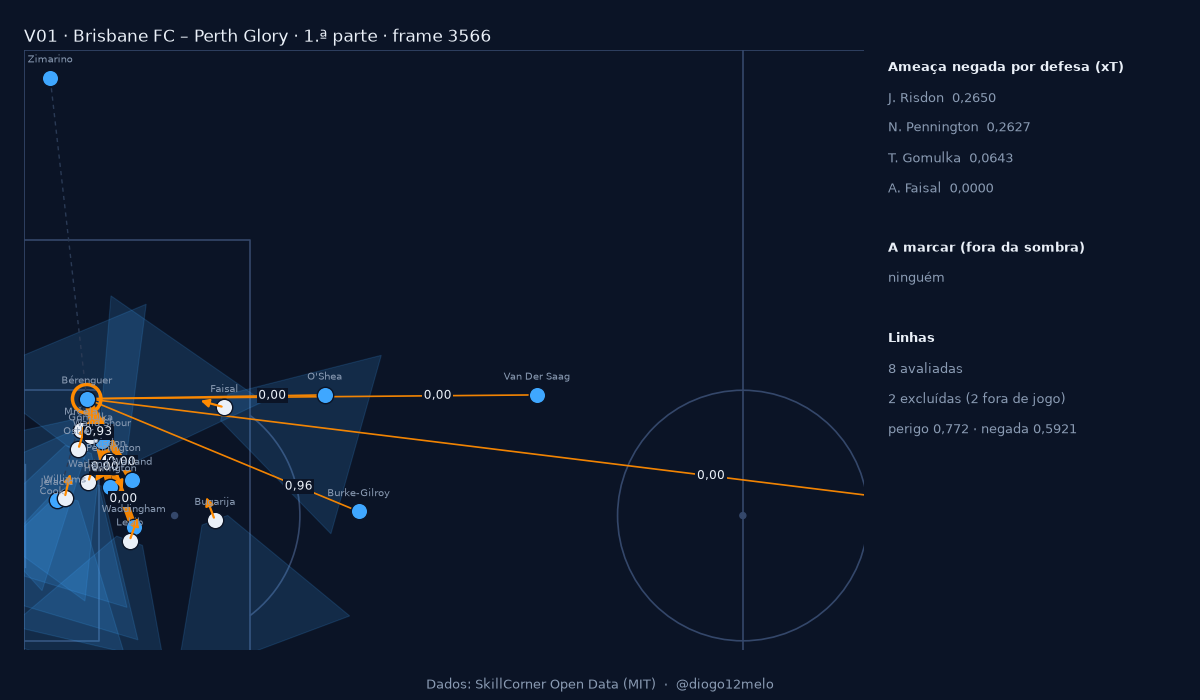

**V02** (grupo: ao acaso)

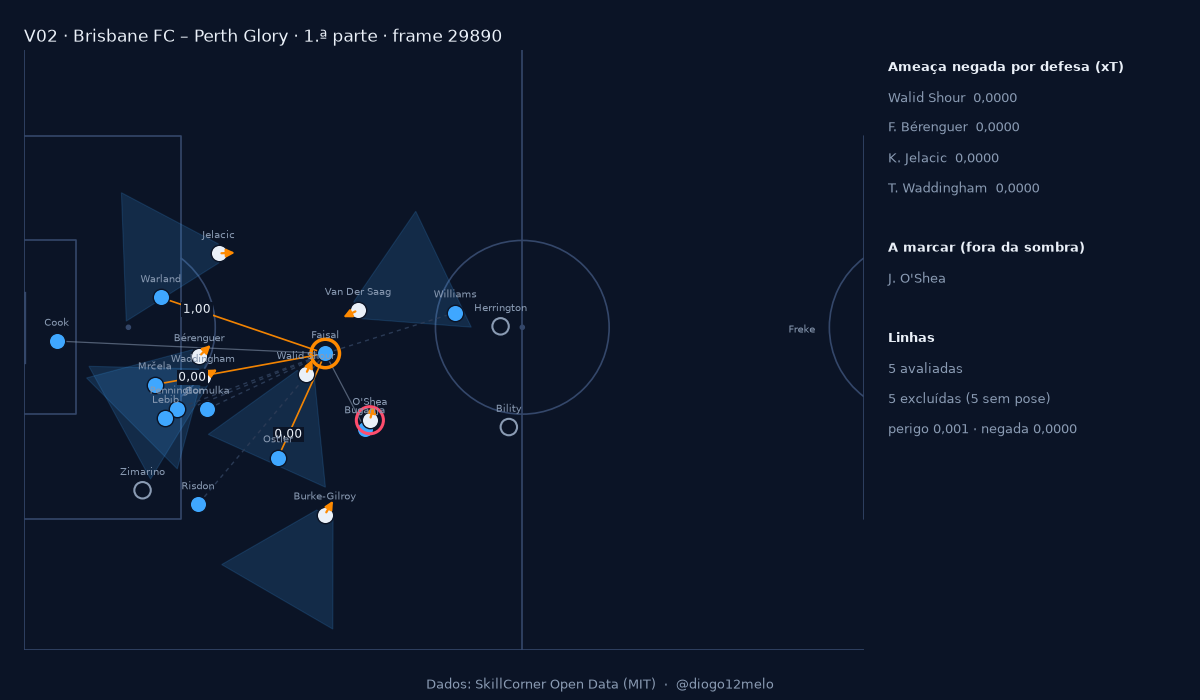

**V05** (grupo: corpo vs bola)

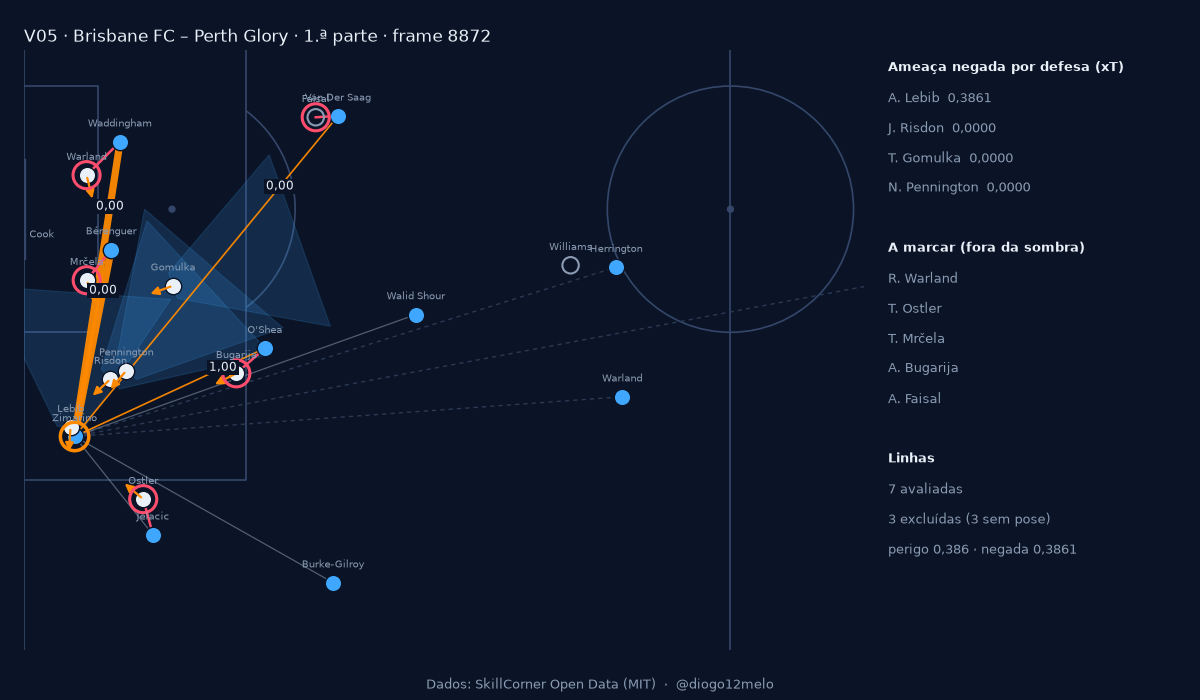

In [8]:
if not sem_bola:
    for grupo in ("negada", "ao_acaso", "corpo_vs_bola"):
        r = escolha[escolha["grupo"] == grupo].sort_values("lance").iloc[0]
        display(Markdown(f"**{r['lance']}** (grupo: {grupo.replace('_', ' ')})"))
        display(Image(filename=str(PASTA_REVISAO_V2 / f"{r['nome']}.png"), width=900))

### 1.3 Verificações depois da 2.ª revisão

A folha `revisao_lances_v2.csv` tem as respostas do treinador à segunda ronda. Os comentários levantaram três pontos,
verificados nos dados da v2 (a definição com que os lances foram revistos). Os números descrevem; não decidem.

In [9]:
folha_v2 = rev.ler_folha(FOLHA_V2)
display(rev.resumir_folha(folha_v2).rename(columns={"sombras_fazem_sentido": "As sombras fazem sentido (C1)",
                                                    "marcacao_correta": "A marcação está correta (C2)"}))
DEFESAS_V2 = {j: preparar_defesas(JG[j]["tabela"], JG[j]["match"], PADRAO_V2) for j in JOGOS}


def jogo_e_frame(lance):
    """Jogo e frame de um lance da folha, a partir do nome dos ficheiros (V01_1925299_3566.png)."""
    nome = folha_v2.loc[folha_v2["lance"] == lance, "ficheiros"].iloc[0].split(".png")[0]
    return int(nome.split("_")[1]), int(nome.split("_")[2])

,As sombras fazem sentido (C1),A marcação está correta (C2)
sim,15,10
em parte,0,4
não,0,1
por preencher,0,0


**(a) Guarda-redes no V01.** O comentário diz que parece haver uma sombra no guarda-redes. Verifica-se quem é o
guarda-redes de quem defende nesse frame, se ficou fora da tabela de defesas (D25) e quem são os defesas
mais perto da própria baliza (com cone = tem pose e não está a marcar).

In [10]:
jogo, frame = jogo_e_frame("V01")
tab = JG[jogo]["tabela"]
quadro = tab[tab["frame"] == frame]
equipa_defensora = int(quadro.loc[quadro["defende"], "equipa"].iloc[0])
baliza_x = baliza_propria_x(JG[jogo]["match"], equipa_defensora, int(quadro["periodo"].iloc[0]))
gr = ver.guarda_redes_no_frame(tab, DEFESAS_V2[jogo], frame)
print(f"V01 · jogo {jogo} · frame {frame}: guarda-redes de quem defende = "
      f"{[JG[jogo]['nomes'][j] for j in gr['guarda_redes']]} (posição GK no match.json), "
      f"em x = {[round(v, 1) for v in gr['x']]}, y = {[round(v, 1) for v in gr['y']]}; "
      f"linhas dele na tabela de defesas: {gr['na_tabela_de_defesas']}")
perto = ver.defesas_com_cone_junto_a_baliza(DEFESAS_V2[jogo], frame, baliza_x)
perto["jogador"] = perto["jogador"].map(JG[jogo]["nomes"])
display(perto.round(1).rename(columns={"jogador": "Defesa", "posicao": "Posição", "dist_baliza": "Distância à baliza (m)",
                                       "tem_cone": "Tem cone"}).style.hide(axis="index"))

V01 · jogo 1925299 · frame 3566: guarda-redes de quem defende = ['C. Cook'] (posição GK no match.json), em x = [-50.5], y = [0.4]; linhas dele na tabela de defesas: 0


Defesa,Posição,x,y,Distância à baliza (m),Tem cone
D. Williams,CF,-49.500000,1.300000,3.200000,True
R. Warland,LB,-47.800000,2.400000,5.300000,True
T. Ostler,RW,-48.500000,4.800000,6.200000,True


**(b) Cruzamentos (D27).** O comentário diz que os lances com mais ameaça negada continuam a ser quase todos
cruzamentos. Mostram-se as etiquetas de corredor e terço que existem (as que o D27 usa estão marcadas), a parte
das linhas que o D27 exclui como cruzamento e, nos 100 frames com mais ameaça negada, onde está o portador.
A regra não foi alterada.

In [11]:
etiquetas = pd.concat([ver.etiquetas_de_zona(JG[j]["tabela"]).assign(jogo=str(j)) for j in JOGOS])
display(etiquetas.pivot_table(index=["terco", "corredor", "zona_de_cruzamento"], columns="jogo", values="frames",
                              fill_value=0).reset_index().rename(columns={
    "terco": "Terço da posse", "corredor": "Corredor da posse", "zona_de_cruzamento": "Zona de cruzamento (D27)"}
    ).style.hide(axis="index"))
linhas_resumo = []
for j in JOGOS:
    linhas_v2 = ler(j, "base", "v2")[0]
    top = ver.resumo_dos_mais_negados(agregacao.por_lance(linhas_v2), JG[j]["tabela"], n=100)
    linhas_resumo.append({
        "Jogo": JG[j]["titulo"], "Linhas": len(linhas_v2),
        "Excluídas como cruzamento": int((linhas_v2["motivo"] == "cruzamento").sum()),
        "% das linhas": pt(100 * (linhas_v2["motivo"] == "cruzamento").mean(), 2),
        "100 frames com mais negada: portador no terço ofensivo": top["terco_ofensivo"],
        "… e fora da largura da área (|y| > 20,16 m)": top["terco_ofensivo_fora_da_area"],
        "… em zona de cruzamento (D27)": top["zona_de_cruzamento"],
        "Por corredor": ", ".join(f"{ROTULOS_CORREDOR.get(k, k)} {v}" for k, v in top["por_corredor"].items())})
display(pd.DataFrame(linhas_resumo).style.hide(axis="index"))

Terço da posse,Corredor da posse,Zona de cruzamento (D27),1925299,1996435
attacking_third,center,False,217.000000,156.000000
attacking_third,half_space_left,False,279.000000,288.000000
attacking_third,half_space_right,False,372.000000,275.000000
attacking_third,wide_left,True,551.000000,553.000000
attacking_third,wide_right,True,714.000000,792.000000
defensive_third,center,False,972.000000,1070.000000
defensive_third,half_space_left,False,570.000000,508.000000
defensive_third,half_space_right,False,707.000000,443.000000
defensive_third,wide_left,False,336.000000,316.000000
defensive_third,wide_right,False,325.000000,427.000000


Jogo,Linhas,Excluídas como cruzamento,% das linhas,100 frames com mais negada: portador no terço ofensivo,"… e fora da largura da área (|y| > 20,16 m)",… em zona de cruzamento (D27),Por corredor
Brisbane FC – Perth Glory,89150,916,"1,03",100,39,36,"lateral dir. 31, meio-espaço esq. 29, meio-espaço dir. 19, centro 16, lateral esq. 5"
Sydney FC – Adelaide United,81450,601,"0,74",96,42,26,"meio-espaço esq. 37, meio-espaço dir. 29, lateral dir. 23, lateral esq. 7, centro 4"


**(c) Quatro marcações não reconhecidas** (V06 Lebib→Zimarino, V11 Shaw→Jovanović, V12 Warland→Zimarino,
V15 Talladira→Lolley). Para cada uma, no frame do lance: o atacante indicado era o portador? Distância, lado da
baliza e tempo face aos limiares, e a primeira condição da regra que falha (D14, D28, D29); e, na janela de ±3 s,
em quantos frames alinhados o defesa está a marcar. A tabela da v2 mostra o que o treinador viu.

In [12]:
CASOS = [("V06", "Lebib", "Zimarino"), ("V11", "Shaw", "Jovanovic"), ("V12", "Warland", "Zimarino"),
         ("V15", "Talladira", "Lolley")]


def tabela_das_marcacoes(defesas_por_jogo, p):
    """Uma linha por caso, com os parâmetros `p` e as defesas já calculadas com eles."""
    linhas = []
    for lance, defensor, atacante in CASOS:
        jogo, frame = jogo_e_frame(lance)
        match = JG[jogo]["match"]
        id_a = ver.jogador_por_sobrenome(match, atacante)
        equipa_a = next(q["team_id"] for q in match["players"] if q["id"] == id_a)
        id_d = ver.jogador_por_sobrenome(match, defensor, outra_equipa_que=equipa_a)
        caso = ver.caso_de_marcacao(JG[jogo]["tabela"], defesas_por_jogo[jogo], frame, id_d, id_a, p)
        janela = ver.marcacao_na_janela(defesas_por_jogo[jogo], id_d, frame)
        no_frame = defesas_por_jogo[jogo].query("frame == @frame and jogador == @id_d")["a_marcar"].iloc[0]
        linhas.append({
            "Lance": lance, "Defesa → atacante": f"{defensor} → {atacante}",
            "Atacante era o portador": "sim" if caso["atacante_indicado_e_o_portador"] else "não",
            "Distância (m)": pt(caso["dist_atacante_indicado"], 2),
            "Vantagem para a baliza (m)": pt(caso["vantagem_baliza"], 2), "Tempo seguido (s)": pt(caso["persistencia_s"], 1),
            "Distância ao portador (m)": pt(caso["dist_portador"], 1), "Condição que falha": caso["regra_que_impediu"],
            "A marcar no frame": "sim" if no_frame else "não",
            "Frames a marcar na janela ±3 s": f"{janela['a_marcar']} de {janela['frames']}",
            "Distância na janela (m)": f"{pt(janela['dist_min'], 1)} a {pt(janela['dist_max'], 1)}",
            "Vantagem na janela (m)": f"{pt(janela['vantagem_min'], 2)} a {pt(janela['vantagem_max'], 2)}"})
    return pd.DataFrame(linhas)


display(Markdown("**v2 · como o treinador viu os lances**"))
display(tabela_das_marcacoes(DEFESAS_V2, PADRAO_V2).style.hide(axis="index"))

**v2 · como o treinador viu os lances**

Lance,Defesa → atacante,Atacante era o portador,Distância (m),Vantagem para a baliza (m),Tempo seguido (s),Distância ao portador (m),Condição que falha,A marcar no frame,Frames a marcar na janela ±3 s,Distância na janela (m),Vantagem na janela (m)
V06,Lebib → Zimarino,não,"3,36","2,78","5,2","15,3",distância ao atacante,não,6 de 23,"2,8 a 5,2","2,49 a 4,88"
V11,Shaw → Jovanovic,não,"2,99","0,74","1,8","22,5",nenhuma (marca),sim,5 de 20,"2,7 a 3,1","-0,89 a 0,85"
V12,Warland → Zimarino,não,"2,50","-0,10","1,2","20,7",lado da baliza,não,4 de 9,"2,4 a 3,2","-1,25 a 0,30"
V15,Talladira → Lolley,não,"2,27","-0,68","1,4","16,7",lado da baliza,não,1 de 19,"2,3 a 5,8","-3,48 a 1,72"


### 1.4 Terceira ronda (v3, W01 a W08)

Oito lances novos, com a definição v3 e os mesmos três grupos (3 de maior ameaça negada, 3 ao acaso, 2 de maior
diferença entre tronco e bola), no máximo um por posse e **sem repetir posses** das duas rondas anteriores. As figuras
passam a mostrar o guarda-redes defensor como quadrado cinzento "GR (excluído)". Folha `revisao_lances_v3.csv` em branco;
figuras e clips em `outputs/cover_shadow/revisao_v3/`.

In [13]:
if not all(calculadas(n, "v3") for n in ("base", "bola")):
    print("Variantes `base` e `bola` da v3 por calcular: uv run python projects/cover_shadow/avaliar_variantes.py --versao v3 --so base bola")
else:
    lances_v3r = lances_da_variante("base", "v3")
    # Seleção que o treinador reviu (D35: não se recalcula, para não mudar com a correção da versão "bola")
    esc3 = pd.read_csv(PASTA_REVISAO_V3 / "indice_dos_lances.csv")
    esc3["ficheiros"] = esc3["nome"] + ".png + " + esc3["nome"] + ".mp4"
    for r in esc3.itertuples():
        titulo = f"{JG[r.jogo]['titulo']} · {r.periodo}.ª parte · frame {r.frame}"
        if not (PASTA_REVISAO_V3 / f"{r.nome}.png").exists():
            rev.guardar_figura(JG[r.jogo], r.frame, r.lance, titulo, brand, FONTE, PASTA_REVISAO_V3, r.nome)
        if not (PASTA_REVISAO_V3 / f"{r.nome}.mp4").exists():
            rev.guardar_clip(JG[r.jogo], r.frame, r.lance, titulo, brand, FONTE, PASTA_REVISAO_V3, r.nome)
    criada = rev.criar_folha(esc3.sort_values("lance")[["lance", "ficheiros"]], FOLHA_V3)
    print("Folha v3 criada em branco." if criada else "Folha v3 já existente (não é alterada).")
    print(f"{len(esc3)} figuras e {len(esc3)} clips em {PASTA_REVISAO_V3}")
    display(esc3.assign(jogo=esc3["jogo"].astype(str)).sort_values("lance")[
        ["lance", "grupo", "jogo", "periodo", "frame", "n_avaliadas", "n_sem_pose", "n_fora_de_jogo", "n_cruzamento",
         "negada"]].round(4).rename(columns={
            "grupo": "Grupo", "jogo": "Jogo", "periodo": "Parte", "frame": "Frame", "n_avaliadas": "Linhas avaliadas",
            "n_sem_pose": "Sem pose", "n_fora_de_jogo": "Fora de jogo", "n_cruzamento": "Cruzamento",
            "negada": "Ameaça negada (xT)", "lance": "Lance"}).style.hide(axis="index"))

Folha v3 já existente (não é alterada).
8 figuras e 8 clips em outputs\cover_shadow\revisao_v3


Lance,Grupo,Jogo,Parte,Frame,Linhas avaliadas,Sem pose,Fora de jogo,Cruzamento,Ameaça negada (xT)
W01,corpo_vs_bola,1925299,1,14478,5,5,0,0,0.172200
W02,negada,1925299,2,50612,10,0,0,0,0.427600
W03,negada,1925299,2,57378,10,0,0,0,0.435200
W04,corpo_vs_bola,1996435,2,45252,6,4,0,0,0.036500
W05,negada,1996435,1,13394,6,4,0,0,0.443600
W06,ao_acaso,1925299,2,38118,6,3,1,0,0.003000
W07,ao_acaso,1996435,2,32452,7,3,0,0,0.000100
W08,ao_acaso,1996435,2,38680,5,5,0,0,0.000000


## 2. C3 · Coerência com o jogo

Com os passes reais dos eventos dinâmicos da SkillCorner (`player_possession` que acabam em passe, com
portador, destino e resultado; foras de jogo ficam de fora), tomando o último frame alinhado da posse
(o mais próximo do momento do passe), duas perguntas:

1. **A linha escolhida tinha mais ou menos sombra do que as outras disponíveis no mesmo momento?**
   Sombra de uma linha = 1 − probabilidade de o passe chegar. Compara-se a da linha seguida com a média das
   linhas avaliadas do frame, e mede-se o percentil da linha seguida (fração das restantes com menos sombra;
   0,5 = igual ao habitual).
2. **A taxa de passes completos varia com a probabilidade de chegar calculada?**

Os intervalos são de 95%: bootstrap percentil (ponto 1) e Wilson (taxas, ponto 2). Só entram passes cuja
linha foi avaliada e em frames com mais do que uma linha avaliada. Na v2 há menos linhas avaliadas (fora de
jogo e cruzamentos saem), por isso o número de passes pode mudar.

In [14]:
def passes_da_versao(versao):
    """Passes reais com a linha seguida, o comprimento, o ganho de xT e as linhas comparáveis."""
    partes = []
    for j in JOGOS:
        linhas = av.adicionar_comprimento(ler(j, "base", versao)[0], JG[j]["tabela"])
        com_linha = av.passes_com_linha(av.passes_do_jogo(JG[j]["eventos"]), linhas)
        partes.append(av.com_comparaveis(com_linha, linhas).assign(jogo=j))
    return pd.concat(partes, ignore_index=True)


PASSES = {v: passes_da_versao(v) for v in VERSOES}
contagem = []
for v in VERSOES:
    for j in JOGOS:
        todos = av.passes_do_jogo(JG[j]["eventos"])
        g = PASSES[v][PASSES[v]["jogo"] == j]
        contagem.append({"Versão": v, "Jogo": str(j), "Passes com resultado": len(todos),
                         "Com linha avaliada": len(g), "Completos (com linha)": int(g["completo"].sum())})
tabela_c3 = pd.DataFrame(contagem)
tabela_c3.style.hide(axis="index")

Versão,Jogo,Passes com resultado,Com linha avaliada,Completos (com linha)
v1,1925299,907,663,604
v1,1996435,874,692,605
v2,1925299,907,660,602
v2,1996435,874,682,602


In [15]:
linhas_c3a = []
for v in VERSOES:
    for nome, g in [("Dois jogos", PASSES[v])] + [(JG[j]["titulo"], PASSES[v][PASSES[v]["jogo"] == j]) for j in JOGOS]:
        r = av.comparar_com_disponiveis(g)
        linhas_c3a.append({"Versão": v, "Jogos": nome, "Passes": r["n"],
                           "Sombra da linha seguida": pt(r["sombra_escolhida"], 3),
                           "Sombra média disponível": pt(r["sombra_disponivel"], 3),
                           "Diferença [IC 95%]": ic(r["dif"], r["dif_inf"], r["dif_sup"]),
                           "Percentil [IC 95%]": ic(r["percentil"], r["percentil_inf"], r["percentil_sup"], 2)})
c3a = pd.DataFrame(linhas_c3a)
display(Markdown("**Sombra da linha seguida vs. linhas disponíveis no mesmo momento**"))
display(c3a.style.hide(axis="index"))

**Sombra da linha seguida vs. linhas disponíveis no mesmo momento**

Versão,Jogos,Passes,Sombra da linha seguida,Sombra média disponível,Diferença [IC 95%],Percentil [IC 95%]
v1,Dois jogos,1355,"0,025","0,127","-0,102 [-0,110; -0,095]","0,31 [0,29; 0,32]"
v1,Brisbane FC – Perth Glory,663,"0,019","0,107","-0,088 [-0,098; -0,077]","0,31 [0,29; 0,33]"
v1,Sydney FC – Adelaide United,692,"0,030","0,146","-0,116 [-0,127; -0,105]","0,30 [0,28; 0,32]"
v2,Dois jogos,1342,"0,087","0,268","-0,180 [-0,194; -0,166]","0,31 [0,30; 0,33]"
v2,Brisbane FC – Perth Glory,660,"0,070","0,234","-0,164 [-0,183; -0,145]","0,32 [0,30; 0,33]"
v2,Sydney FC – Adelaide United,682,"0,104","0,301","-0,196 [-0,218; -0,175]","0,31 [0,29; 0,33]"


**Taxa de passes completos por faixa de probabilidade de chegar (dois jogos)**

faixa,v1 · passes,v1 · taxa [IC 95%],v2 · passes,v2 · taxa [IC 95%]
0 a 0.5,20,"35,0% [18,1; 56,7]",113,"64,6% [55,4; 72,8]"
0.5 a 0.9,53,"67,9% [54,5; 78,9]",16,"68,8% [44,4; 85,8]"
0.9 a 1,249,"74,7% [69,0; 79,7]",176,"77,8% [71,1; 83,3]"
1 (sem sombra),1033,"94,9% [93,3; 96,1]",1037,"94,8% [93,3; 96,0]"


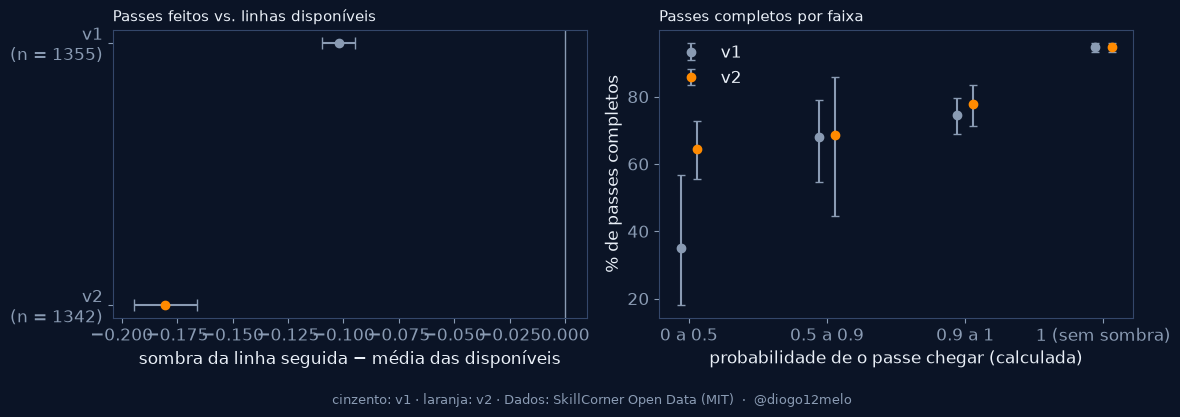

In [16]:
faixas = {v: av.taxa_de_completos_por_faixa(PASSES[v]) for v in VERSOES}
display(Markdown("**Taxa de passes completos por faixa de probabilidade de chegar (dois jogos)**"))
tabela_faixas = faixas["v1"][["faixa"]].copy()
for v in VERSOES:
    f = faixas[v]
    tabela_faixas[f"{v} · passes"] = f["n"]
    tabela_faixas[f"{v} · taxa [IC 95%]"] = [
        f"{pt(100 * r.taxa, 1)}% [{pt(100 * r.inf, 1)}; {pt(100 * r.sup, 1)}]" if r.n else "–" for r in f.itertuples()]
display(tabela_faixas.style.hide(axis="index"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
valores = [av.comparar_com_disponiveis(PASSES[v]) for v in VERSOES]
for i, (v, r) in enumerate(zip(VERSOES, valores)):
    ax1.errorbar(r["dif"], 1 - i, xerr=[[r["dif"] - r["dif_inf"]], [r["dif_sup"] - r["dif"]]], fmt="o",
                 color=COR["primary"] if v == "v2" else COR["text_muted"], ecolor=COR["text_muted"], capsize=4)
ax1.axvline(0, color=COR["text_muted"], lw=1)
ax1.set_yticks([1, 0], [f"{v}\n(n = {r['n']})" for v, r in zip(VERSOES, valores)])
ax1.set_xlabel("sombra da linha seguida − média das disponíveis")
ax1.set_title("Passes feitos vs. linhas disponíveis", loc="left", fontsize=11)
for i, v in enumerate(VERSOES):
    f = faixas[v][faixas[v]["n"] > 0]
    x = faixas[v].index[faixas[v]["n"] > 0].to_numpy() + (i - 0.5) * 0.12
    ax2.errorbar(x, 100 * f["taxa"], yerr=[100 * (f["taxa"] - f["inf"]), 100 * (f["sup"] - f["taxa"])], fmt="o",
                 color=COR["primary"] if v == "v2" else COR["text_muted"], ecolor=COR["text_muted"], capsize=3, label=v)
ax2.set_xticks(np.arange(len(faixas["v2"])), faixas["v2"]["faixa"])
ax2.set_xlabel("probabilidade de o passe chegar (calculada)")
ax2.set_ylabel("% de passes completos")
ax2.set_title("Passes completos por faixa", loc="left", fontsize=11)
ax2.legend(frameon=False)
credito(fig, "cinzento: v1 · laranja: v2")
fig.savefig(SAIDA / "fase5_c3.png", dpi=150, facecolor=COR["background"])
plt.show()

### 2.1 Controlo do comprimento e do ganho de xT

A comparação anterior pode misturar a sombra com o tipo de passe: passes longos ou muito para a frente
atravessam mais sombra e falham mais por outras razões. Dois controlos:

- **Linhas comparáveis:** para cada passe, só contam as outras linhas avaliadas do mesmo frame com
  comprimento até 5 m diferente e ganho de xT até 0,02 diferente. Os passes sem nenhuma linha comparável saem.
  Mostra-se a diferença com e sem controlo, **no mesmo conjunto de passes**.
- **Taxa de completos por banda de comprimento do passe** (0 a 10 m, 10 a 20 m, 20 m ou mais), para ver se a
  taxa varia com a sombra dentro de cada banda.

In [17]:
linhas_ctl = []
for v in VERSOES:
    r = av.comparar_com_comparaveis(PASSES[v])
    linhas_ctl.append({"Versão": v, "Passes com linhas comparáveis": r["n"],
                       "Sem controlo [IC 95%]": ic(r["dif_sem_controlo"], r["dif_sem_controlo_inf"], r["dif_sem_controlo_sup"]),
                       "Com controlo [IC 95%]": ic(r["dif_controlada"], r["dif_controlada_inf"], r["dif_controlada_sup"]),
                       "Comparáveis por passe (mediana)": int(PASSES[v].loc[PASSES[v]["n_comparaveis"] > 0,
                                                                          "n_comparaveis"].median())})
display(Markdown("**Diferença de sombra (linha seguida − referência), com e sem controlo**"))
display(pd.DataFrame(linhas_ctl).style.hide(axis="index"))
display(PASSES["v2"].groupby(pd.cut(PASSES["v2"]["comprimento"], [0, 10, 20, 200], right=False))
        .agg(passes=("sombra", "size"), sombra_media=("sombra", "mean"), ganho_xt_medio=("valor_xt", "mean"),
             completos=("completo", "mean")).round(3).rename_axis("Comprimento do passe (m), v2"))

**Diferença de sombra (linha seguida − referência), com e sem controlo**

Versão,Passes com linhas comparáveis,Sem controlo [IC 95%],Com controlo [IC 95%],Comparáveis por passe (mediana)
v1,1081,"-0,100 [-0,107; -0,092]","-0,038 [-0,046; -0,030]",2
v2,1072,"-0,177 [-0,192; -0,160]","-0,161 [-0,186; -0,138]",2


<cell>:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(PASSES["v2"].groupby(pd.cut(PASSES["v2"]["comprimento"], [0, 10, 20, 200], right=False))


,passes,sombra_media,ganho_xt_medio,completos
"Comprimento do passe (m), v2",,,,
"[0, 10)",324,0.119,0.002,0.877
"[10, 20)",727,0.061,0.004,0.917
"[20, 200)",291,0.120,0.006,0.869


In [18]:
por_banda = pd.concat([av.taxa_por_faixa_e_comprimento(PASSES[v]).assign(versao=v) for v in VERSOES])
por_banda = por_banda[por_banda["n"] > 0]
display(Markdown("**Taxa de passes completos por banda de comprimento e faixa de probabilidade de chegar**"))
display(pd.DataFrame({
    "Versão": por_banda["versao"], "Comprimento": por_banda["comprimento"], "Probabilidade de chegar": por_banda["faixa"],
    "Passes": por_banda["n"], "Completos": por_banda["completos"],
    "Taxa [IC 95%]": [f"{pt(100 * r.taxa, 1)}% [{pt(100 * r.inf, 1)}; {pt(100 * r.sup, 1)}]" for r in por_banda.itertuples()],
}).style.hide(axis="index"))

**Taxa de passes completos por banda de comprimento e faixa de probabilidade de chegar**

Versão,Comprimento,Probabilidade de chegar,Passes,Completos,Taxa [IC 95%]
v1,0 a 10 m,0.5 a 0.9,9,6,"66,7% [35,4; 87,9]"
v1,0 a 10 m,0.9 a 1,60,42,"70,0% [57,5; 80,1]"
v1,0 a 10 m,1 (sem sombra),257,237,"92,2% [88,3; 94,9]"
v1,10 a 20 m,0 a 0.5,2,1,"50,0% [9,5; 90,5]"
v1,10 a 20 m,0.5 a 0.9,19,15,"78,9% [56,7; 91,5]"
v1,10 a 20 m,0.9 a 1,134,102,"76,1% [68,2; 82,5]"
v1,10 a 20 m,1 (sem sombra),576,550,"95,5% [93,5; 96,9]"
v1,20 m ou mais,0 a 0.5,18,6,"33,3% [16,3; 56,3]"
v1,20 m ou mais,0.5 a 0.9,25,15,"60,0% [40,7; 76,6]"
v1,20 m ou mais,0.9 a 1,55,42,"76,4% [63,7; 85,6]"


## 3. C4 · Estabilidade a parâmetros

Cada parâmetro varia de cada vez à volta dos valores de partida (`dataclasses.replace` sobre `PADRAO`), com a
métrica a correr de raiz nos dois jogos (`avaliar_variantes.py`). A v1 testou 8 parâmetros (17 variantes por jogo);
a v2 junta os 5 limiares novos (A11), incluindo valores que **desligam** a regra (pressão 0 m, bloqueio 0 m,
saída da marcação 3 m = sem continuidade), para ver quanto cada regra pesa. Para cada variação:

- **% negada:** percentagem da ameaça disponível (linhas avaliadas) que a métrica nega, por jogo.
- **ρ jogador:** correlação de Spearman, face aos valores de partida da mesma versão, da ameaça negada por
  jogador, calculada dentro de cada posição (só posições com pelo menos 4 jogadores nos dois jogos) e com média
  ponderada pelo número de jogadores.
- **ρ lance:** correlação de Spearman da ameaça negada por lance (frame), nos lances com linhas avaliadas nas duas.

Com o comprimento do cone, o comprimento do passe curto e o avanço do passe atrasado, as linhas excluídas também
mudam (muda quem pode afetar cada linha ou o que é cruzamento); por isso a % negada compara-se sobre as linhas
avaliadas de cada variante.

In [19]:
NOMES = {"angulo_cone": "Ângulo do cone (°)", "comprimento_cone": "Comprimento do cone (m)",
         "largura_junto_ao_corpo": "Largura junto ao corpo (m)", "tempo_reacao": "Tempo de reação (s)",
         "velocidade_bola": "Velocidade da bola (m/s)", "incerteza_tempo": "Incerteza do tempo (s)",
         "distancia_marcacao": "Marcação: distância (m)", "tempo_marcacao": "Marcação: tempo mínimo (s)",
         "distancia_pressao": "Pressão: distância ao portador (m)",
         "distancia_saida_marcacao": "Marcação: distância de saída (m)",
         "raio_bloqueio_corpo": "Bloqueio pelo corpo: raio (m)",
         "bloqueio_gradual": "Bloqueio pelo corpo: gradual",
         "comprimento_passe_curto": "Cruzamento: passe curto até (m)",
         "avanco_maximo_atrasado": "Cruzamento: avanço do passe atrasado (m)"}
TESTADOS = {"v1": av.VALORES_TESTADOS_V1, "v2": av.VALORES_TESTADOS, "v3": av.VALORES_ANTIGOS_V3}
em_falta = [n for n in av.variantes() if not calculadas(n, "v2")]
if em_falta:
    print(f"Variantes da v2 por calcular ({len(em_falta)} de {len(av.variantes())}): "
          "uv run python projects/cover_shadow/avaliar_variantes.py --trabalhadores 6")

In [20]:
def comparar_com_a_base(variante, versao, base_jogador, base_lance):
    """Linha da tabela de estabilidade de uma variante."""
    linha = {f"pct_{j}": av.pct_negada(ler(j, variante, versao)[0]) for j in JOGOS}
    linha["rho_jogador"] = av.spearman_por_posicao(base_jogador, jogadores_da_variante(variante, versao))["rho_media"]
    linha["rho_lance"] = av.spearman_por_lance(base_lance, lances_da_variante(variante, versao))
    linha["excluidas"] = np.mean([ler(j, variante, versao)[0]["excluida"].mean() * 100 for j in JOGOS])
    return linha


def tabela_c4(versao):
    """Uma linha por parâmetro e valor já calculado (a base conta como o valor de partida)."""
    base_jogador, base_lance = jogadores_da_variante("base", versao), lances_da_variante("base", versao)
    linhas = []
    for parametro, valores in TESTADOS[versao].items():
        partida = getattr(PADRAO if versao == "v3" else PADRAO_V2, parametro)  # a v1 e a v2 partiam da definição D25–D31
        for valor in sorted((partida, *valores)):
            nome = "base" if valor == partida else av.nome_da_variante(parametro, valor)
            if calculadas(nome, versao):
                linhas.append({"parametro": parametro, "valor": valor, "partida": valor == partida,
                               **comparar_com_a_base(nome, versao, base_jogador, base_lance)})
    return pd.DataFrame(linhas)


def mostrar_c4(c4):
    return pd.DataFrame({
        "Parâmetro": c4["parametro"].map(NOMES),
        "Valor": [f"{v:g}".replace(".", ",") + (" (partida)" if p else "") for v, p in zip(c4["valor"], c4["partida"])],
        **{f"% negada {JG[j]['titulo']}": c4[f"pct_{j}"].map(lambda v: pt(v, 1)) for j in JOGOS},
        "% linhas excluídas": c4["excluidas"].map(lambda v: pt(v, 1)),
        "ρ jogador": c4["rho_jogador"].map(lambda v: pt(v, 3)), "ρ lance": c4["rho_lance"].map(lambda v: pt(v, 3)),
    })


C4 = {v: tabela_c4(v) for v in VERSOES}
display(Markdown("**v2 · variantes já calculadas**"))
display(mostrar_c4(C4["v2"]).style.hide(axis="index"))

**v2 · variantes já calculadas**

Parâmetro,Valor,% negada Brisbane FC – Perth Glory,% negada Sydney FC – Adelaide United,% linhas excluídas,ρ jogador,ρ lance
Ângulo do cone (°),45,"56,7","48,4","31,7","0,985","0,990"
Ângulo do cone (°),60 (partida),"57,7","49,8","31,7","1,000","1,000"
Ângulo do cone (°),90,"59,5","52,3","31,7","0,996","0,984"
Comprimento do cone (m),8,"57,3","49,1","27,5","1,000","0,957"
Comprimento do cone (m),10 (partida),"57,7","49,8","31,7","1,000","1,000"
Comprimento do cone (m),12,"58,2","49,6","35,9","0,992","0,953"
Largura junto ao corpo (m),1,"51,2","43,0","30,7","0,996","0,951"
Largura junto ao corpo (m),2 (partida),"57,7","49,8","31,7","1,000","1,000"
Largura junto ao corpo (m),3,"59,4","51,7","32,8","0,997","0,979"
Tempo de reação (s),"0,5","61,2","54,3","31,7","1,000","0,994"


In [21]:
display(Markdown("**v1 · primeira avaliação (para comparar)**"))
display(mostrar_c4(C4["v1"]).style.hide(axis="index"))

**v1 · primeira avaliação (para comparar)**

Parâmetro,Valor,% negada Brisbane FC – Perth Glory,% negada Sydney FC – Adelaide United,% linhas excluídas,ρ jogador,ρ lance
Ângulo do cone (°),45,"32,0","29,3","30,6","0,991","0,986"
Ângulo do cone (°),60 (partida),"34,0","31,4","30,6","1,000","1,000"
Ângulo do cone (°),90,"37,7","35,3","30,6","1,000","0,976"
Comprimento do cone (m),8,"34,2","31,3","26,2","0,982","0,951"
Comprimento do cone (m),10 (partida),"34,0","31,4","30,6","1,000","1,000"
Comprimento do cone (m),12,"33,1","30,6","34,9","0,997","0,935"
Largura junto ao corpo (m),1,"30,6","27,6","29,5","1,000","0,965"
Largura junto ao corpo (m),2 (partida),"34,0","31,4","30,6","1,000","1,000"
Largura junto ao corpo (m),3,"37,0","34,5","31,7","1,000","0,968"
Tempo de reação (s),"0,5","44,8","42,0","30,6","0,979","0,993"


In [22]:
def amplitude(c4):
    """Por parâmetro: intervalo da % negada (por jogo), e o menor ρ de jogador e de lance."""
    linhas = []
    for parametro, g in c4.groupby("parametro", sort=False):
        linha = {"Parâmetro": NOMES[parametro]}
        for j in JOGOS:
            linha[f"% negada {j}"] = f"{pt(g[f'pct_{j}'].min())} a {pt(g[f'pct_{j}'].max())}"
        linha["ρ jogador (mín.)"] = pt(g["rho_jogador"].min(), 3)
        linha["ρ lance (mín.)"] = pt(g["rho_lance"].min(), 3)
        linhas.append(linha)
    return pd.DataFrame(linhas)


display(Markdown("**Amplitude da variação, v1 e v2**"))
for v in VERSOES:
    display(Markdown(f"*{v}*"))
    display(amplitude(C4[v]).style.hide(axis="index"))

**Amplitude da variação, v1 e v2**

*v1*

Parâmetro,% negada 1925299,% negada 1996435,ρ jogador (mín.),ρ lance (mín.)
Ângulo do cone (°),"32,0 a 37,7","29,3 a 35,3","0,991","0,976"
Comprimento do cone (m),"33,1 a 34,2","30,6 a 31,4","0,982","0,935"
Largura junto ao corpo (m),"30,6 a 37,0","27,6 a 34,5","1,000","0,965"
Tempo de reação (s),"24,6 a 44,8","22,0 a 42,0","0,979","0,993"
Velocidade da bola (m/s),"26,2 a 43,9","23,6 a 41,6","0,979","0,994"
Incerteza do tempo (s),"31,9 a 36,4","29,8 a 33,3","0,972","0,992"
Marcação: distância (m),"34,0 a 35,8","31,4 a 32,9","1,000","0,975"
Marcação: tempo mínimo (s),"34,0 a 34,9","31,0 a 33,0","0,955","0,991"


*v2*

Parâmetro,% negada 1925299,% negada 1996435,ρ jogador (mín.),ρ lance (mín.)
Ângulo do cone (°),"56,7 a 59,5","48,4 a 52,3","0,985","0,984"
Comprimento do cone (m),"57,3 a 58,2","49,1 a 49,8","0,992","0,953"
Largura junto ao corpo (m),"51,2 a 59,4","43,0 a 51,7","0,996","0,951"
Tempo de reação (s),"54,9 a 61,2","46,2 a 54,3","0,985","0,994"
Velocidade da bola (m/s),"55,1 a 61,6","46,4 a 55,0","0,985","0,993"
Incerteza do tempo (s),"57,0 a 58,5","49,0 a 50,8","1,000","0,997"
Marcação: distância (m),"57,7 a 58,9","49,8 a 51,1","1,000","0,975"
Marcação: tempo mínimo (s),"57,7 a 58,6","49,5 a 50,9","0,975","0,989"
Pressão: distância ao portador (m),"57,3 a 57,8","49,3 a 50,0","1,000","0,994"
Marcação: distância de saída (m),"57,6 a 58,1","49,7 a 50,1","1,000","0,990"


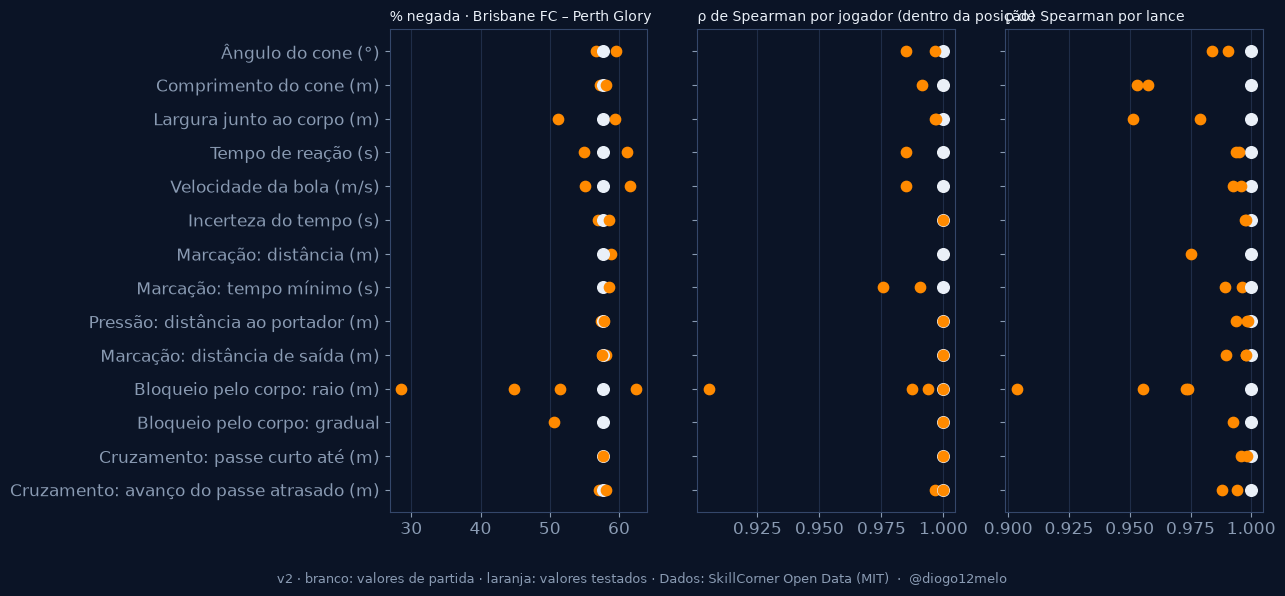

In [23]:
c4 = C4["v2"]
fig, eixos = plt.subplots(1, 3, figsize=(13, 6), sharey=True)
y_por = {p: i for i, p in enumerate([p for p in NOMES if p in set(c4["parametro"])][::-1])}
paineis = [("pct_" + str(JOGOS[0]), f"% negada · {JG[JOGOS[0]]['titulo']}"),
           ("rho_jogador", "ρ de Spearman por jogador (dentro da posição)"),
           ("rho_lance", "ρ de Spearman por lance")]
for ax, (coluna, titulo) in zip(eixos, paineis):
    for _, r in c4.iterrows():
        ax.scatter(r[coluna], y_por[r["parametro"]], s=70 if r["partida"] else 55,
                   color=COR["text"] if r["partida"] else COR["primary"], zorder=3)
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.grid(axis="x", color=COR["lines"], alpha=0.5)
eixos[0].set_yticks(list(y_por.values()), [NOMES[p] for p in y_por])
credito(fig, "v2 · branco: valores de partida · laranja: valores testados")
fig.savefig(SAIDA / "fase5_c4.png", dpi=150, facecolor=COR["background"])
plt.show()

### 3.1 Regras novas (D25–D30): ameaça negada, C3 com controlo e passes na faixa abaixo de 0,5

Para o valor de partida e para cada variante dos limiares novos (A11), três medidas, sem as interpretar:

- **% negada** em cada jogo (como no C4);
- **C3 com controlo:** diferença de sombra entre a linha seguida e as linhas comparáveis em comprimento e ganho de xT
  (secção 2.1), com IC 95% por bootstrap, e o número de passes em que se calcula;
- **Faixa de probabilidade de chegar abaixo de 0,5:** passes nessa faixa, quantos foram completos e a taxa com IC 95% de Wilson.

Variantes do bloqueio pelo corpo (D30): raios 0 (desligado), 0,5, 0,7, 1 (partida) e 1,5 m com probabilidade 1; e o
**bloqueio gradual**, com probabilidade 1 até 0,3 m do defesa a descer linearmente até 0 a 1,2 m (fica com a maior entre
o bloqueio e a probabilidade de chegar a tempo). Valores 0 m (pressão e bloqueio) e 3 m (saída da marcação) desligam a regra.

In [24]:
REGRAS_NOVAS = ("distancia_pressao", "distancia_saida_marcacao", "raio_bloqueio_corpo", "bloqueio_gradual",
                "comprimento_passe_curto", "avanco_maximo_atrasado")
DESLIGADAS = {("distancia_pressao", 0.0), ("raio_bloqueio_corpo", 0.0), ("distancia_saida_marcacao", 3.0)}


def passes_da_variante(variante, versao="v2"):
    partes = []
    for j in JOGOS:
        linhas = av.adicionar_comprimento(ler(j, variante, versao)[0], JG[j]["tabela"])
        com_linha = av.passes_com_linha(av.passes_do_jogo(JG[j]["eventos"]), linhas)
        partes.append(av.com_comparaveis(com_linha, linhas).assign(jogo=j))
    return pd.concat(partes, ignore_index=True)


def linha_das_regras(rotulo, valor, variante, versao="v2"):
    t = passes_da_variante(variante, versao)
    c3 = av.comparar_com_comparaveis(t)
    baixa = t[t["p_chegar"] < 0.5]
    taxa, inf, sup = av.intervalo_wilson(int(baixa["completo"].sum()), len(baixa))
    return {"Regra": rotulo, "Valor": valor,
            **{f"% negada {JG[j]['titulo']}": pt(av.pct_negada(ler(j, variante, versao)[0]), 1) for j in JOGOS},
            "Passes (C3 controlado)": c3["n"], "Dif. de sombra [IC 95%]": ic(c3["dif_controlada"], c3["dif_controlada_inf"], c3["dif_controlada_sup"]),
            "Passes com p < 0,5": len(baixa), "Completos": int(baixa["completo"].sum()),
            "Taxa [IC 95%]": f"{pt(100 * taxa, 1)}% [{pt(100 * inf, 1)}; {pt(100 * sup, 1)}]" if len(baixa) else "–"}


linhas_regras = [linha_das_regras("Valores de partida", "–", "base")]
for parametro in REGRAS_NOVAS:
    for valor in av.VALORES_TESTADOS[parametro]:
        nome = av.nome_da_variante(parametro, valor)
        if not calculadas(nome):
            continue
        etiqueta = ("gradual: 1 até 0,3 m, 0 a 1,2 m" if parametro == "bloqueio_gradual" else
                    f"{valor:g}".replace(".", ",") + (" (regra desligada)" if (parametro, valor) in DESLIGADAS else ""))
        linhas_regras.append(linha_das_regras(NOMES[parametro], etiqueta, nome))
regras_novas = pd.DataFrame(linhas_regras)
regras_novas.style.hide(axis="index")

Regra,Valor,% negada Brisbane FC – Perth Glory,% negada Sydney FC – Adelaide United,Passes (C3 controlado),Dif. de sombra [IC 95%],"Passes com p < 0,5",Completos,Taxa [IC 95%]
Valores de partida,–,"57,7","49,8",1072,"-0,161 [-0,186; -0,138]",113,73,"64,6% [55,4; 72,8]"
Pressão: distância ao portador (m),0 (regra desligada),"57,3","49,3",1073,"-0,159 [-0,182; -0,135]",111,71,"64,0% [54,7; 72,3]"
Pressão: distância ao portador (m),3,"57,7","49,5",1072,"-0,161 [-0,186; -0,137]",113,73,"64,6% [55,4; 72,8]"
Pressão: distância ao portador (m),5,"57,8","50,0",1072,"-0,162 [-0,186; -0,138]",116,76,"65,5% [56,5; 73,5]"
Marcação: distância de saída (m),3 (regra desligada),"58,1","50,1",1068,"-0,162 [-0,186; -0,138]",115,75,"65,2% [56,1; 73,3]"
Marcação: distância de saída (m),4,"57,9","49,9",1071,"-0,162 [-0,185; -0,138]",114,74,"64,9% [55,8; 73,1]"
Marcação: distância de saída (m),6,"57,6","49,7",1073,"-0,160 [-0,183; -0,135]",113,73,"64,6% [55,4; 72,8]"
Bloqueio pelo corpo: raio (m),0 (regra desligada),"28,6","26,7",1072,"-0,037 [-0,044; -0,029]",16,5,"31,2% [14,2; 55,6]"
Bloqueio pelo corpo: raio (m),"0,5","44,9","39,5",1072,"-0,098 [-0,117; -0,078]",65,38,"58,5% [46,3; 69,6]"
Bloqueio pelo corpo: raio (m),"0,7","51,4","43,7",1072,"-0,121 [-0,142; -0,099]",84,52,"61,9% [51,2; 71,6]"


### 3.2 Definição final (v3): marcação a 4 m e bloqueio gradual (D33, D34)

A v3 muda dois pontos da v2: a marcação passa a entrar a 4 m (era 3 m) e a contar o lado a lado (até 1 m de tolerância
no lado da baliza), e o bloqueio pelo corpo passa de um raio fixo de 1 m a uma probabilidade que vai de 1 (até 0,3 m)
a 0 (a 1,2 m). Só se recalculou a base e as variantes do bloqueio por raio fixo (0, 0,5, 0,7, 1 e 1,5 m); o resto da
sensibilidade da v2 não se repetiu.

**(a) v1, v2 e v3 lado a lado.** As mesmas três medidas da secção 3.1: % negada em cada jogo, C3 com controlo do
comprimento e do ganho de xT e taxa de passes completos nas linhas com probabilidade de chegar abaixo de 0,5.

In [25]:
linhas_versoes = [linha_das_regras("Versão", v, "base", v) for v in ("v1", "v2", "v3")]
versoes_lado_a_lado = pd.DataFrame(linhas_versoes).drop(columns="Regra").rename(columns={"Valor": "Versão"})
versoes_lado_a_lado.style.hide(axis="index")

Versão,% negada Brisbane FC – Perth Glory,% negada Sydney FC – Adelaide United,Passes (C3 controlado),Dif. de sombra [IC 95%],"Passes com p < 0,5",Completos,Taxa [IC 95%]
v1,"34,0","31,4",1081,"-0,038 [-0,046; -0,030]",20,7,"35,0% [18,1; 56,7]"
v2,"57,7","49,8",1072,"-0,161 [-0,186; -0,138]",113,73,"64,6% [55,4; 72,8]"
v3,"46,9","39,4",1087,"-0,121 [-0,139; -0,102]",86,53,"61,6% [51,1; 71,2]"


**(b) Estabilidade relativa.** A v3 comparada com a mesma métrica a usar um raio fixo no bloqueio (0, 0,5, 0,7, 1 e 1,5 m),
tudo o resto como na v3: % negada, C3 com controlo, taxa de completos abaixo de 0,5 e, nas duas últimas colunas, a correlação
de Spearman com a v3 da ameaça negada por jogador (dentro da posição, posições com pelo menos 4 jogadores nos dois jogos) e
por lance. Os valores absolutos mudam com o bloqueio; o que se vê aqui é se a ordem se mantém.

In [26]:
VARIANTES_RAIO = [av.nome_da_variante("raio_bloqueio_corpo", r) for r in av.RAIOS_BLOQUEIO_V3]
em_falta_v3 = [n for n in ("base", *VARIANTES_RAIO) if not calculadas(n, "v3")]
if em_falta_v3:
    print("Por calcular na v3:", em_falta_v3, "→ uv run python projects/cover_shadow/avaliar_variantes.py --versao v3")
else:
    base_jogador_v3, base_lance_v3 = jogadores_da_variante("base", "v3"), lances_da_variante("base", "v3")
    linhas_estab = [{**linha_das_regras("Bloqueio", "gradual (v3)", "base", "v3"), "ρ jogador": "–", "ρ lance": "–"}]
    for r, nome_v in zip(av.RAIOS_BLOQUEIO_V3, VARIANTES_RAIO):
        rotulo = f"raio fixo de {pt(r, 1)} m" + (" (bloqueio desligado)" if r == 0 else "")
        rho = comparar_com_a_base(nome_v, "v3", base_jogador_v3, base_lance_v3)
        linhas_estab.append({**linha_das_regras("Bloqueio", rotulo, nome_v, "v3"),
                             "ρ jogador": pt(rho["rho_jogador"], 3), "ρ lance": pt(rho["rho_lance"], 3)})
    estabilidade_v3 = pd.DataFrame(linhas_estab).drop(columns="Regra").rename(columns={"Valor": "Bloqueio pelo corpo"})
    display(estabilidade_v3.style.hide(axis="index"))

Bloqueio pelo corpo,% negada Brisbane FC – Perth Glory,% negada Sydney FC – Adelaide United,Passes (C3 controlado),Dif. de sombra [IC 95%],"Passes com p < 0,5",Completos,Taxa [IC 95%],ρ jogador,ρ lance
gradual (v3),"46,9","39,4",1087,"-0,121 [-0,139; -0,102]",86,53,"61,6% [51,1; 71,2]",–,–
"raio fixo de 0,0 m (bloqueio desligado)","24,8","22,2",1087,"-0,033 [-0,041; -0,027]",16,5,"31,2% [14,2; 55,6]","0,896","0,911"
"raio fixo de 0,5 m","40,8","35,3",1087,"-0,095 [-0,114; -0,077]",65,38,"58,5% [46,3; 69,6]","0,984","0,970"
"raio fixo de 0,7 m","47,5","39,5",1087,"-0,119 [-0,140; -0,099]",83,52,"62,7% [51,9; 72,3]","0,996","0,984"
"raio fixo de 1,0 m","54,1","45,5",1087,"-0,157 [-0,180; -0,135]",112,73,"65,2% [56,0; 73,4]","0,997","0,992"
"raio fixo de 1,5 m","59,3","51,4",1087,"-0,185 [-0,211; -0,160]",133,85,"63,9% [55,5; 71,6]","0,920","0,973"


**(c) As quatro marcações da 2.ª revisão com a v3.** A mesma tabela da secção 1.3, agora com a definição v3.

In [27]:
DEFESAS_V3 = {j: JG[j]["defesas"] for j in JOGOS}
display(tabela_das_marcacoes(DEFESAS_V3, PADRAO).style.hide(axis="index"))

Lance,Defesa → atacante,Atacante era o portador,Distância (m),Vantagem para a baliza (m),Tempo seguido (s),Distância ao portador (m),Condição que falha,A marcar no frame,Frames a marcar na janela ±3 s,Distância na janela (m),Vantagem na janela (m)
V06,Lebib → Zimarino,não,"3,36","2,78","5,2","15,3",nenhuma (marca),sim,13 de 23,"2,8 a 5,2","2,49 a 4,88"
V11,Shaw → Jovanovic,não,"2,99","0,74","1,8","22,5",nenhuma (marca),sim,20 de 20,"2,7 a 3,1","-0,89 a 0,85"
V12,Warland → Zimarino,não,"2,50","-0,10","1,2","20,7",nenhuma (marca),sim,6 de 9,"2,4 a 3,2","-1,25 a 0,30"
V15,Talladira → Lolley,não,"2,27","-0,68","1,4","16,7",nenhuma (marca),sim,3 de 19,"2,3 a 5,8","-3,48 a 1,72"


**(d) Por fase defensiva (D32), v3.** Ameaça negada por fase de jogo da SkillCorner (`team_out_of_possession_phase_type`)
e por terço da posse, nos dois jogos juntos; sem leitura. A mesma divisão, por jogo, está no notebook 04, secção 4.1.

In [28]:
contexto_v3 = pd.concat([
    agregacao.contexto_dos_frames(JG[j]["tabela"], sc.ler_fases(j)).assign(jogo=j) for j in JOGOS], ignore_index=True)
lances_ctx = lances_da_variante("base", "v3").merge(contexto_v3, on=["jogo", "frame"])
for por, titulo in [("fase", "Fase defensiva"), ("terco", "Terço da posse")]:
    g = lances_ctx[lances_ctx["n_avaliadas"] > 0].groupby(por, dropna=False).agg(
        lances=("frame", "size"), disponivel=("disponivel", "sum"), negada=("negada", "sum")).reset_index()
    g["pct_negada"] = 100 * g["negada"] / g["disponivel"]
    g[por] = g[por].map(ROTULOS_CONTEXTO).fillna("sem fase")
    display(g.sort_values("negada", ascending=False).round(2).rename(columns={
        por: titulo, "lances": "Lances", "disponivel": "Disponível (xT)", "negada": "Negada (xT)",
        "pct_negada": "% negada"}).style.hide(axis="index"))

Fase defensiva,Lances,Disponível (xT),Negada (xT),% negada
bloco baixo,4938,271.320000,125.480000,46.250000
bola parada,246,53.080000,28.690000,54.050000
bloco médio,6138,92.410000,28.150000,30.460000
contra-ataque,380,33.400000,17.770000,53.190000
bloco alto,3354,31.770000,7.910000,24.910000
caótica,904,14.030000,7.520000,53.620000
transição defensiva,315,9.050000,3.550000,39.280000
defesa de jogo direto,26,0.350000,0.080000,24.170000
sem fase,4,0.010000,0.000000,0.000000


Terço da posse,Lances,Disponível (xT),Negada (xT),% negada
terço ofensivo,4001,300.480000,154.730000,51.490000
terço médio,6952,151.410000,50.880000,33.600000
terço defensivo,5352,53.530000,13.550000,25.320000


### 3.3 Estabilidade dos parâmetros antigos na v3 (C4)

Os parâmetros da v1 (ângulo, comprimento e largura do cone, tempo de reação, velocidade da bola, incerteza do tempo e
marcação: entrada a 3 e 5 m, tempo mínimo 0,5 e 1,5 s) variam de cada vez à volta da definição v3, nos dois jogos.
As colunas são as da secção 3: % negada por jogo, % de linhas excluídas e ρ de Spearman face à v3 por jogador (dentro
da posição) e por lance. O bloqueio pelo corpo está na secção 3.2.

In [29]:
em_falta = [n for n in av.variantes_v3() if not calculadas(n, "v3")]
if em_falta:
    print(f"Variantes da v3 por calcular ({len(em_falta)}): uv run python projects/cover_shadow/avaliar_variantes.py --versao v3")
else:
    C4["v3"] = tabela_c4("v3")
    display(mostrar_c4(C4["v3"]).style.hide(axis="index"))
    display(Markdown("**Amplitude da variação, v3**"))
    display(amplitude(C4["v3"]).style.hide(axis="index"))

Parâmetro,Valor,% negada Brisbane FC – Perth Glory,% negada Sydney FC – Adelaide United,% linhas excluídas,ρ jogador,ρ lance
Ângulo do cone (°),45,"45,8","38,1","29,5","1,000","0,989"
Ângulo do cone (°),60 (partida),"46,9","39,4","29,5","1,000","1,000"
Ângulo do cone (°),90,"48,8","41,9","29,5","1,000","0,982"
Comprimento do cone (m),8,"46,7","38,9","25,3","0,993","0,957"
Comprimento do cone (m),10 (partida),"46,9","39,4","29,5","1,000","1,000"
Comprimento do cone (m),12,"46,9","39,6","33,5","0,994","0,950"
Largura junto ao corpo (m),1,"42,6","35,4","28,5","0,975","0,963"
Largura junto ao corpo (m),2 (partida),"46,9","39,4","29,5","1,000","1,000"
Largura junto ao corpo (m),3,"48,5","41,4","30,5","1,000","0,978"
Tempo de reação (s),"0,5","51,1","44,4","29,5","1,000","0,993"


**Amplitude da variação, v3**

Parâmetro,% negada 1925299,% negada 1996435,ρ jogador (mín.),ρ lance (mín.)
Ângulo do cone (°),"45,8 a 48,8","38,1 a 41,9","1,000","0,982"
Comprimento do cone (m),"46,7 a 46,9","38,9 a 39,6","0,993","0,950"
Largura junto ao corpo (m),"42,6 a 48,5","35,4 a 41,4","0,975","0,963"
Tempo de reação (s),"43,7 a 51,1","35,4 a 44,4","0,977","0,993"
Velocidade da bola (m/s),"43,8 a 51,5","35,6 a 45,2","0,990","0,992"
Incerteza do tempo (s),"46,3 a 47,8","38,9 a 40,2","0,994","0,997"
Marcação: tempo mínimo (s),"46,8 a 48,3","38,8 a 41,1","0,977","0,977"
Marcação: distância (m),"45,5 a 49,0","38,1 a 40,7","0,997","0,962"


## 4. C5 · O corpo acrescenta alguma coisa

Mesma métrica, com a orientação do tronco substituída pela de um defesa a olhar para o portador (a sombra
fica no lado oposto ao portador). Os defesas sem pose continuam sem orientação nas duas versões, por isso as
linhas avaliadas são as mesmas. Compara-se:

- **linhas em que muda a sombra:** o conjunto de defesas que fazem sombra sobre a linha é diferente;
- **ameaça negada por jogador:** diferença e correlação de Spearman dentro da posição;
- **lances de maior diferença** (os que entram na revisão, secção 1).

In [30]:
def numeros_c5(versao):
    mudancas = pd.concat([mudancas_de_sombra(j, versao) for j in JOGOS], ignore_index=True)
    tronco, bola = jogadores_da_variante("base", versao), jogadores_da_variante("bola", versao)
    rho = av.spearman_por_posicao(tronco, bola)
    juntos = tronco.merge(bola, on=["jogo", "jogador", "posicao", "nome"], suffixes=("_tronco", "_bola"))
    com_valor = mudancas[mudancas["valor_xt"] > 0]
    return {"mudancas": mudancas, "com_valor": com_valor, "rho": rho, "jogadores": juntos,
            "dif_mediana": (juntos["negada_bola"] - juntos["negada_tronco"]).abs().median()}


VERSOES_C5 = ("v1", "v2", "v3")
if all(calculadas("bola", v) for v in VERSOES_C5):
    C5 = {v: numeros_c5(v) for v in VERSOES_C5}
    linhas_c5 = []
    for v in VERSOES_C5:
        for nome, g in [("Todas as linhas avaliadas", C5[v]["mudancas"]), ("Só com perigo (ganho de xT > 0)", C5[v]["com_valor"])]:
            linhas_c5.append({"Versão": v, "Conjunto": nome, "Linhas": len(g), "Mudam de sombra": int(g["muda"].sum()),
                              "% que mudam": pt(100 * g["muda"].mean(), 1),
                              "Sombra só no corpo": int(((g["quem_base"] != "") & (g["quem_var"] == "")).sum()),
                              "Sombra só na bola": int(((g["quem_base"] == "") & (g["quem_var"] != "")).sum())})
    display(pd.DataFrame(linhas_c5).style.hide(axis="index"))
    display(pd.DataFrame([{"Versão": v, "Jogo": JG[j]["titulo"],
                           "% que mudam": pt(100 * C5[v]["mudancas"].query("jogo == @j")["muda"].mean(), 1),
                           "% negada (tronco)": pt(av.pct_negada(ler(j, "base", v)[0]), 1),
                           "% negada (bola)": pt(av.pct_negada(ler(j, "bola", v)[0]), 1)}
                          for v in VERSOES_C5 for j in JOGOS]).style.hide(axis="index"))

Versão,Conjunto,Linhas,Mudam de sombra,% que mudam,Sombra só no corpo,Sombra só na bola
v1,Todas as linhas avaliadas,117978,51678,"43,8",17356,6513
v1,Só com perigo (ganho de xT > 0),64538,31513,"48,8",8909,4482
v2,Todas as linhas avaliadas,116152,49497,"42,6",17560,6509
v2,Só com perigo (ganho de xT > 0),62090,29094,"46,9",8887,4428
v3,Todas as linhas avaliadas,119963,48079,"40,1",18287,6738
v3,Só com perigo (ganho de xT > 0),63954,28163,"44,0",9318,4620


Versão,Jogo,% que mudam,% negada (tronco),% negada (bola)
v1,Brisbane FC – Perth Glory,"41,5","34,0","39,2"
v1,Sydney FC – Adelaide United,"46,0","31,4","35,1"
v2,Brisbane FC – Perth Glory,"40,4","57,7","60,4"
v2,Sydney FC – Adelaide United,"44,8","49,8","54,5"
v3,Brisbane FC – Perth Glory,"38,2","46,9","49,2"
v3,Sydney FC – Adelaide United,"41,9","39,4","43,5"


**v1 · ameaça negada por jogador, tronco vs. bola:** ρ de Spearman dentro da posição = 0,953 (média ponderada; mínimo 0,800); diferença absoluta mediana = 0,029 xT.

**v2 · ameaça negada por jogador, tronco vs. bola:** ρ de Spearman dentro da posição = 0,975 (média ponderada; mínimo 0,800); diferença absoluta mediana = 0,037 xT.

**v3 · ameaça negada por jogador, tronco vs. bola:** ρ de Spearman dentro da posição = 0,972 (média ponderada; mínimo 0,800); diferença absoluta mediana = 0,023 xT.

Posição,Jogadores,ρ (v3)
AM,5,1.000000
CF,9,0.967000
LB,4,1.000000
LCB,5,1.000000
LW,8,0.976000
RB,5,1.000000
RCB,4,0.800000
RDM,5,1.000000
RW,8,0.976000


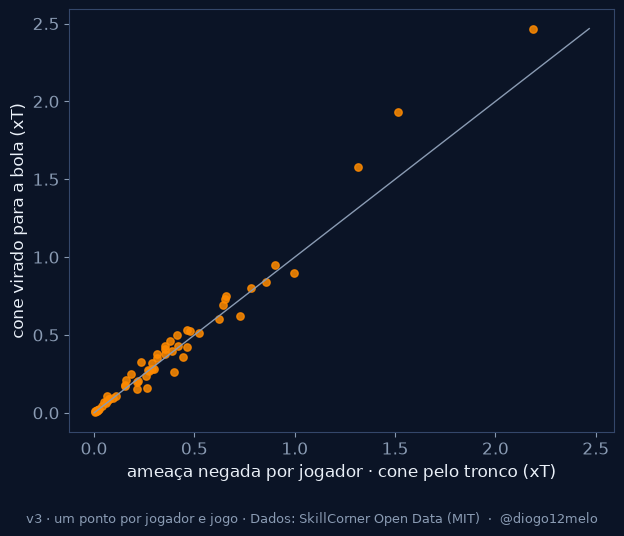

In [31]:
if all(calculadas("bola", v) for v in VERSOES_C5):
    for v in VERSOES_C5:
        rho = C5[v]["rho"]
        display(Markdown(f"**{v} · ameaça negada por jogador, tronco vs. bola:** ρ de Spearman dentro da posição = "
                         f"{pt(rho['rho_media'], 3)} (média ponderada; mínimo {pt(rho['rho_min'], 3)}); "
                         f"diferença absoluta mediana = {pt(C5[v]['dif_mediana'], 3)} xT."))
    display(C5["v3"]["rho"]["posicoes"].rename(columns={"posicao": "Posição", "n": "Jogadores", "rho": "ρ (v3)"})
            .round(3).style.hide(axis="index"))
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    j2 = C5["v3"]["jogadores"]
    ax.scatter(j2["negada_tronco"], j2["negada_bola"], s=28, color=COR["primary"], alpha=0.85)
    maximo = j2[["negada_tronco", "negada_bola"]].max().max()
    ax.plot([0, maximo], [0, maximo], color=COR["text_muted"], lw=1)
    ax.set_xlabel("ameaça negada por jogador · cone pelo tronco (xT)")
    ax.set_ylabel("cone virado para a bola (xT)")
    credito(fig, "v3 · um ponto por jogador e jogo")
    fig.savefig(SAIDA / "fase5_c5.png", dpi=150, facecolor=COR["background"])
    plt.show()

In [32]:
if calculadas("bola", "v2"):
    disc = pd.concat([av.discordancia_por_lance(mudancas_de_sombra(j)).assign(jogo=j) for j in JOGOS], ignore_index=True)
    maiores = disc.sort_values("discordancia", ascending=False).head(10)
    display(Markdown("**v2 · os 10 lances de maior diferença entre tronco e bola** (um por frame)"))
    display(maiores.assign(jogo=maiores["jogo"].astype(str))[
        ["jogo", "frame", "discordancia", "linhas_que_mudam", "linhas"]].round(4).rename(columns={
            "jogo": "Jogo", "frame": "Frame", "discordancia": "Ameaça negada que muda (xT)",
            "linhas_que_mudam": "Linhas que mudam", "linhas": "Linhas"}).style.hide(axis="index"))

**v2 · os 10 lances de maior diferença entre tronco e bola** (um por frame)

Jogo,Frame,Ameaça negada que muda (xT),Linhas que mudam,Linhas
1996435,23726,0.339800,4,4
1996435,39334,0.314300,5,10
1996435,37852,0.304300,4,9
1996435,39332,0.294400,4,10
1996435,23728,0.289200,4,4
1996435,23724,0.272600,4,4
1996435,23720,0.272600,4,4
1996435,23718,0.272600,4,4
1996435,23716,0.272600,4,4
1996435,23722,0.253000,4,4


### 4.1 Orientação dos jogadores da equipa sem bola face à bola

Ângulo entre a frente do tronco de cada jogador da equipa sem bola e a direção do portador (0° = virado para a bola,
180° = de costas), na definição v3, nos dois jogos, só durante as posses adversárias e para os jogadores com pose (sem
guarda-redes; a amostra inclui defesas, médios e avançados). Cada observação é um jogador num instante (a pose está
alinhada 5 vezes por segundo). Apresentam-se: a distribuição, o ângulo por faixa de distância à bola, por grupo de
posição e por marcação, o teste bola vs frente e os jogadores das linhas em que a sombra muda entre o cone pelo tronco
e o cone virado para a bola. Os valores descrevem, sem interpretação.

In [33]:
import orientacao_defesas as od

OD = od.calcular(JG)
dist = OD["distribuicao"]
display(pd.DataFrame([{"Conjunto": nome, "Observações": d["n"], "Mediana (°)": pt(d["mediana"], 1),
                       "% até 45°": pt(d["pct_ate_45"], 1), "% até 90°": pt(d["pct_ate_90"], 1),
                       "% acima de 135°": pt(d["pct_acima_135"], 1)}
                      for nome, d in [("Todos", dist["todos"]), ("A marcar", dist["a_marcar"]), ("Sem marcar", dist["sem_marcar"])]
                      ]).style.hide(axis="index"))

Conjunto,Observações,Mediana (°),% até 45°,% até 90°,% acima de 135°
Todos,124671,"34,8","63,3","95,9","0,6"
A marcar,28428,"34,0","64,3","96,0","0,6"
Sem marcar,96243,"35,0","63,0","95,9","0,6"


Faixa de distância,Observações,Mediana (°),% até 45°,% até 90°,% acima de 135°
0–10 m,29445,"29,9","68,6","95,1","1,1"
10–20 m,42404,"34,1","63,7","95,2","0,6"
20–30 m,33319,"36,6","61,2","96,7","0,3"
30+ m,19503,"39,5","57,9","97,4","0,3"


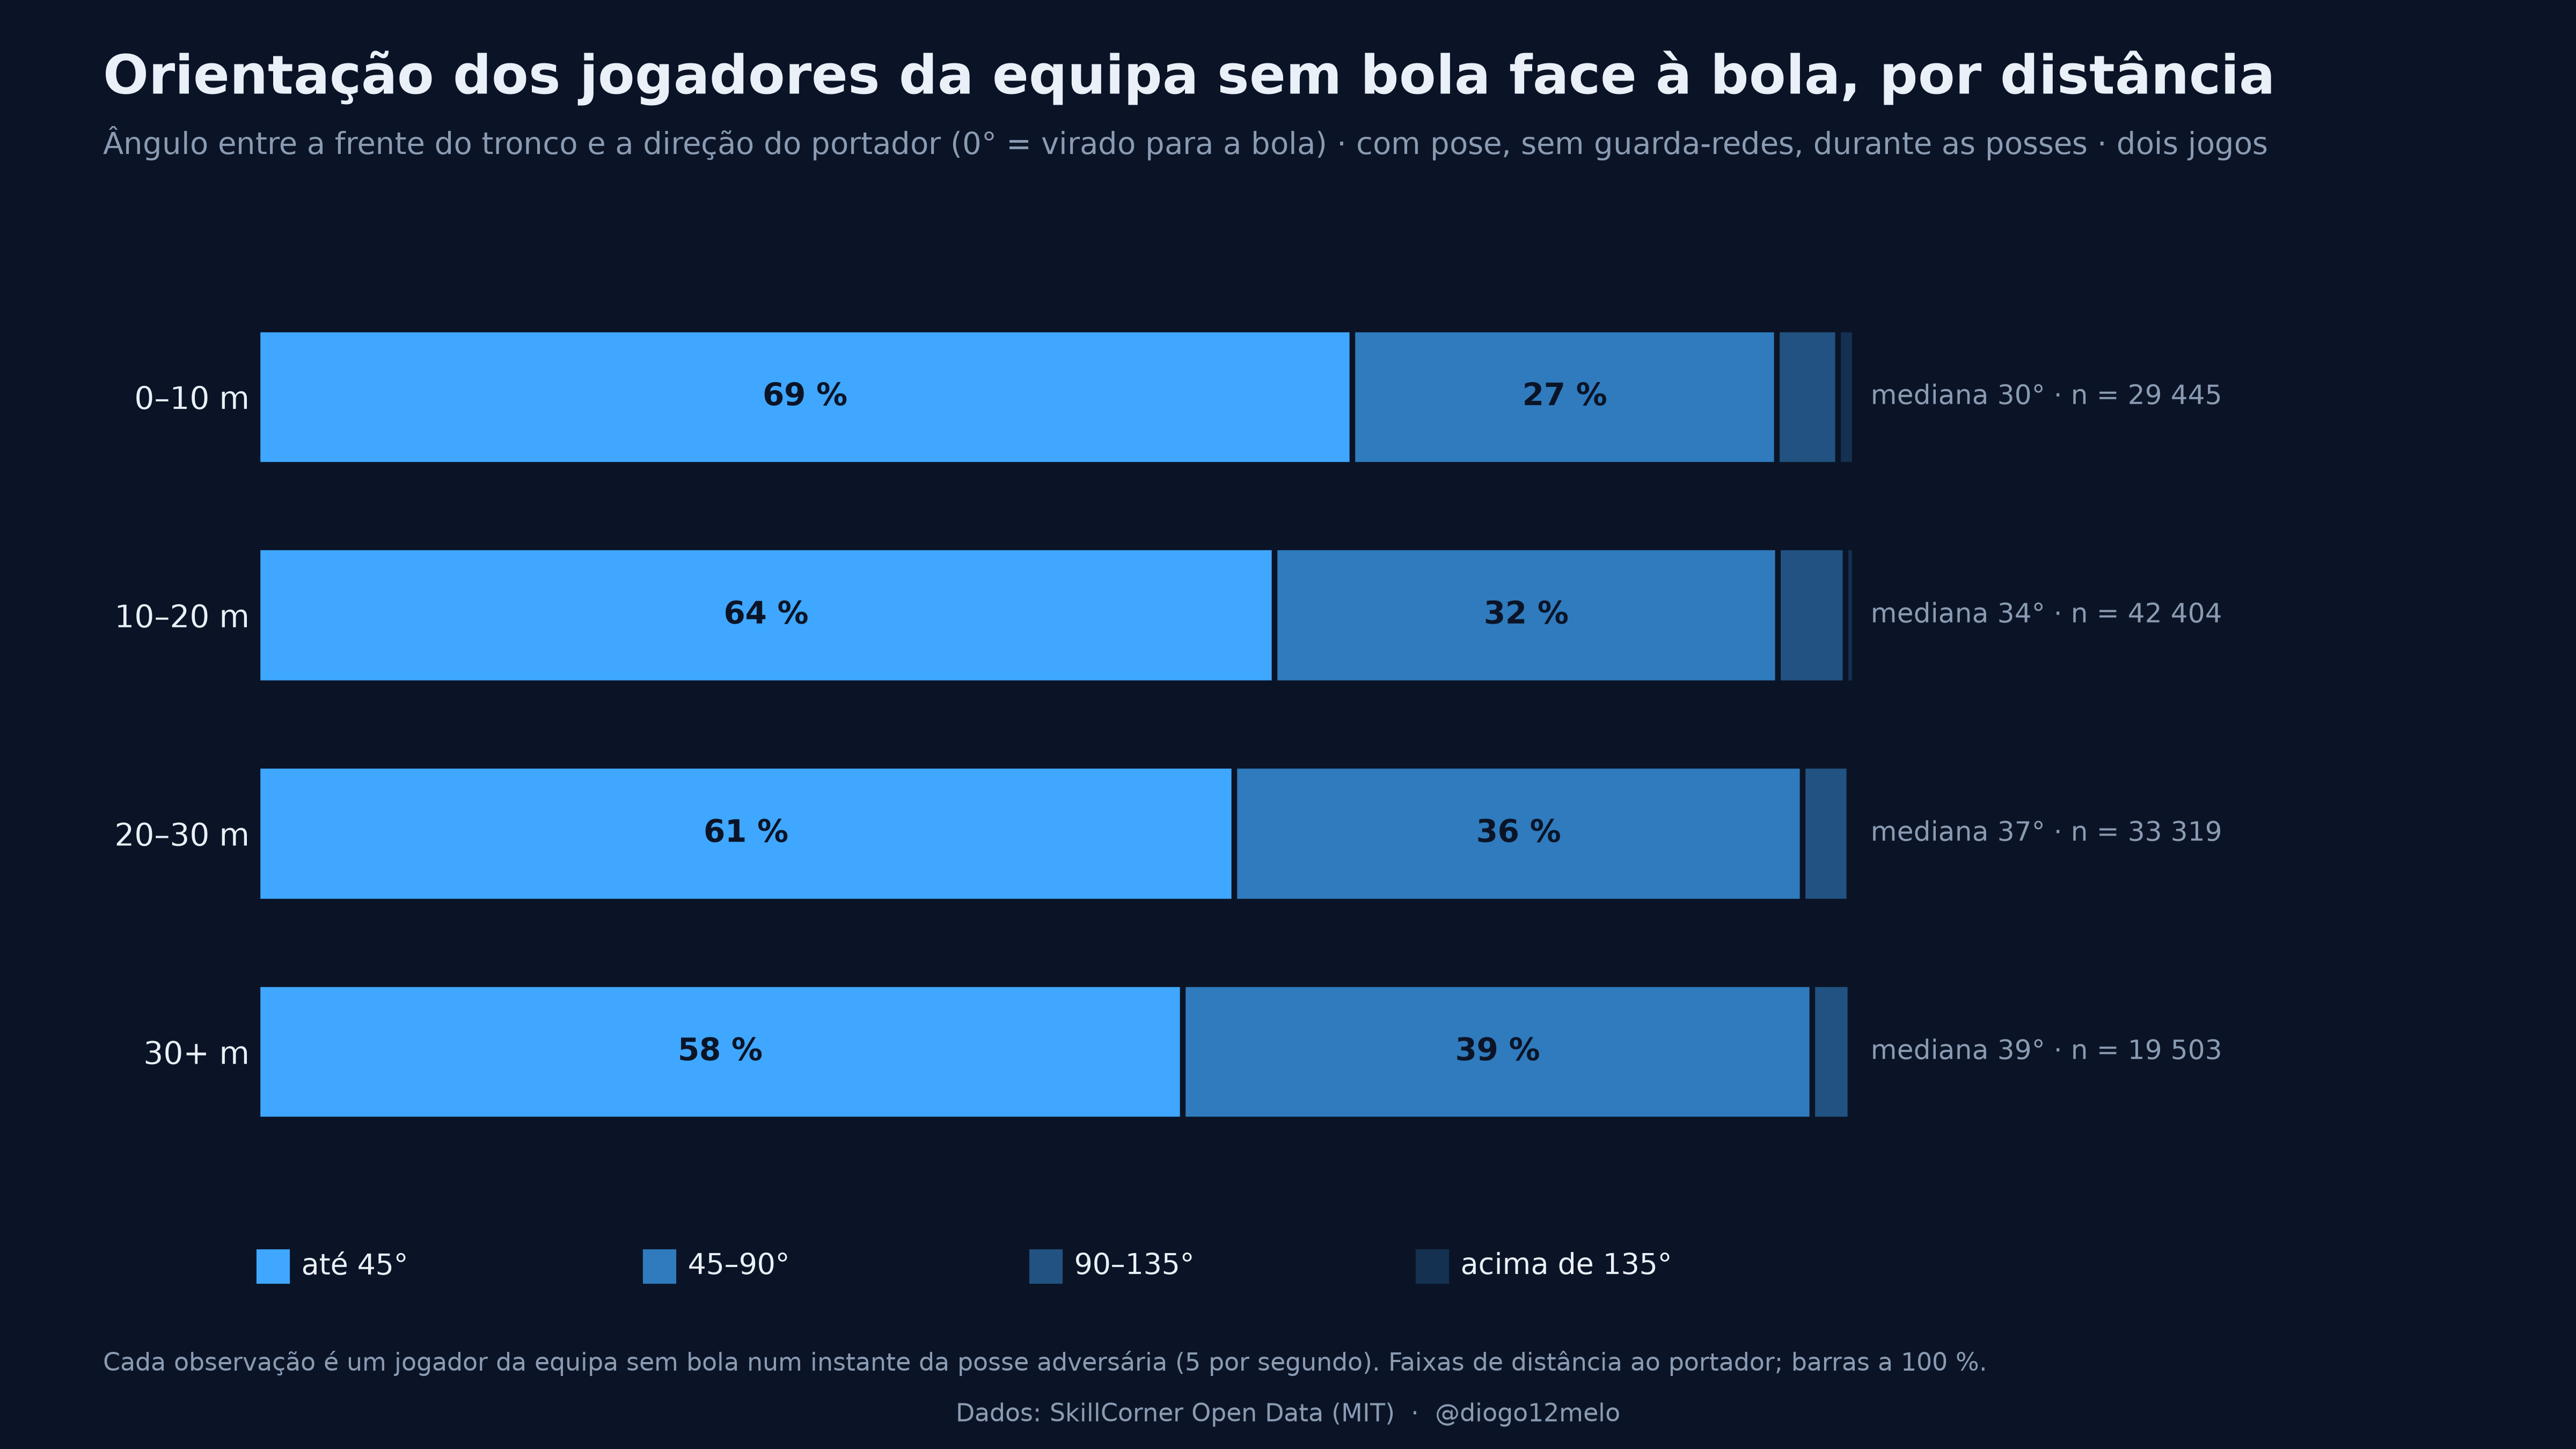

In [34]:
f = OD["faixas"]
display(pd.DataFrame({"Faixa de distância": f["faixa"], "Observações": f["n"], "Mediana (°)": f["mediana"].map(lambda v: pt(v, 1)),
                      "% até 45°": f["pct_ate_45"].map(lambda v: pt(v, 1)), "% até 90°": f["pct_ate_90"].map(lambda v: pt(v, 1)),
                      "% acima de 135°": f["pct_acima_135"].map(lambda v: pt(v, 1))}).style.hide(axis="index"))
destino = SAIDA / "artigo" / "orientacao_angulo_por_distancia.png"
destino.parent.mkdir(parents=True, exist_ok=True)
od.figura_angulo_por_distancia(OD["defesas"], brand, destino)
display(Image(filename=str(destino), width=900))

**Por grupo de posição, faixa de distância e marcação.** Mediana do ângulo (°), % até 45° e número de observações.

In [35]:
g = OD["grupos"].copy()
g["valor"] = g.apply(lambda r: f"{pt(r['mediana'], 0)}° · {pt(r['pct_ate_45'], 0)} % · n = {r['n']}", axis=1)
display(g.pivot_table(index=["grupo", "marcacao"], columns="faixa", values="valor", aggfunc="first", sort=False)[list(od.ROTULOS_FAIXA)])

faixa                                 0–10 m                 10–20 m  \
grupo     marcacao                                                     
centrais  a marcar      36° · 59 % · n = 440   34° · 62 % · n = 2480   
          sem marcar   41° · 54 % · n = 1924   40° · 56 % · n = 3636   
laterais  a marcar      34° · 65 % · n = 562   43° · 52 % · n = 1495   
          sem marcar   39° · 57 % · n = 3427   45° · 50 % · n = 3702   
médios    a marcar     30° · 67 % · n = 1702   34° · 64 % · n = 4025   
          sem marcar   31° · 66 % · n = 8150  34° · 64 % · n = 11050   
avançados a marcar     26° · 76 % · n = 1960   28° · 74 % · n = 3322   
          sem marcar  26° · 76 % · n = 11280  31° · 69 % · n = 12694   

faixa                               20–30 m                  30+ m  
grupo     marcacao                                                  
centrais  a marcar    35° · 63 % · n = 3171  38° · 59 % · n = 1503  
          sem marcar  36° · 61 % · n = 4631  41° · 56 % · n = 1715  
laterais  a marcar    46° · 50 % · n = 1220  46° · 48 % · n = 1232  
          sem marcar  45° · 51 % · n = 3526  50° · 43 % · n = 4982  
médios    a marcar    37° · 61 % · n = 2105   34° · 65 % · n = 570  
          sem marcar  39° · 60 % · n = 8230  42° · 55 % · n = 2298  
avançados a marcar    30° · 72 % · n = 1682   33° · 71 % · n = 959  
          sem marcar  33° · 66 % · n = 8754  33° · 70 % · n = 6244

**Por grupo de posição, todas as faixas e marcação juntas.**

In [36]:
ga = OD["grupos_agregado"]
display(pd.DataFrame({"Grupo": ga["grupo"], "Observações": ga["n"], "Mediana (°)": ga["mediana"].map(lambda v: pt(v, 1)),
                      "% até 45°": ga["pct_ate_45"].map(lambda v: pt(v, 1)),
                      "% acima de 135°": ga["pct_acima_135"].map(lambda v: pt(v, 1))}).style.hide(axis="index"))

Grupo,Observações,Mediana (°),% até 45°,% acima de 135°
centrais,19500,"37,1","59,1","0,6"
laterais,20146,"45,1","49,9","0,9"
médios,38130,"35,3","62,9","0,4"
avançados,46895,"29,9","71,0","0,5"


**Bola vs frente.** O ângulo tronco–portador não separa "virado para a bola" de "virado para a frente": um jogador entre a
bola e a própria baliza, virado para o campo adversário, tem ângulo pequeno sem acompanhar a bola. Por isso calcula-se também
o ângulo tronco–frente (entre a frente do tronco e a direção perpendicular à linha da própria baliza, a apontar para longe dela;
o sentido de jogo por parte é o do pipeline, `sentido_de_ataque`, invertido para a equipa sem bola) e a separação bola–frente
(ângulo entre a direção do portador e a da frente; só geometria, não depende da pose). Por faixa de separação: observações,
mediana de cada ângulo e % de observações em que o tronco está mais perto da direção do portador do que da frente.

Separação bola–frente,Observações,Mediana tronco–portador (°),Mediana tronco–frente (°),% mais perto da bola
0–45°,46170,"36,3","42,5","62,7"
45–90°,45770,"36,9","87,0","84,8"
90°+,32731,"30,5","142,9","96,7"


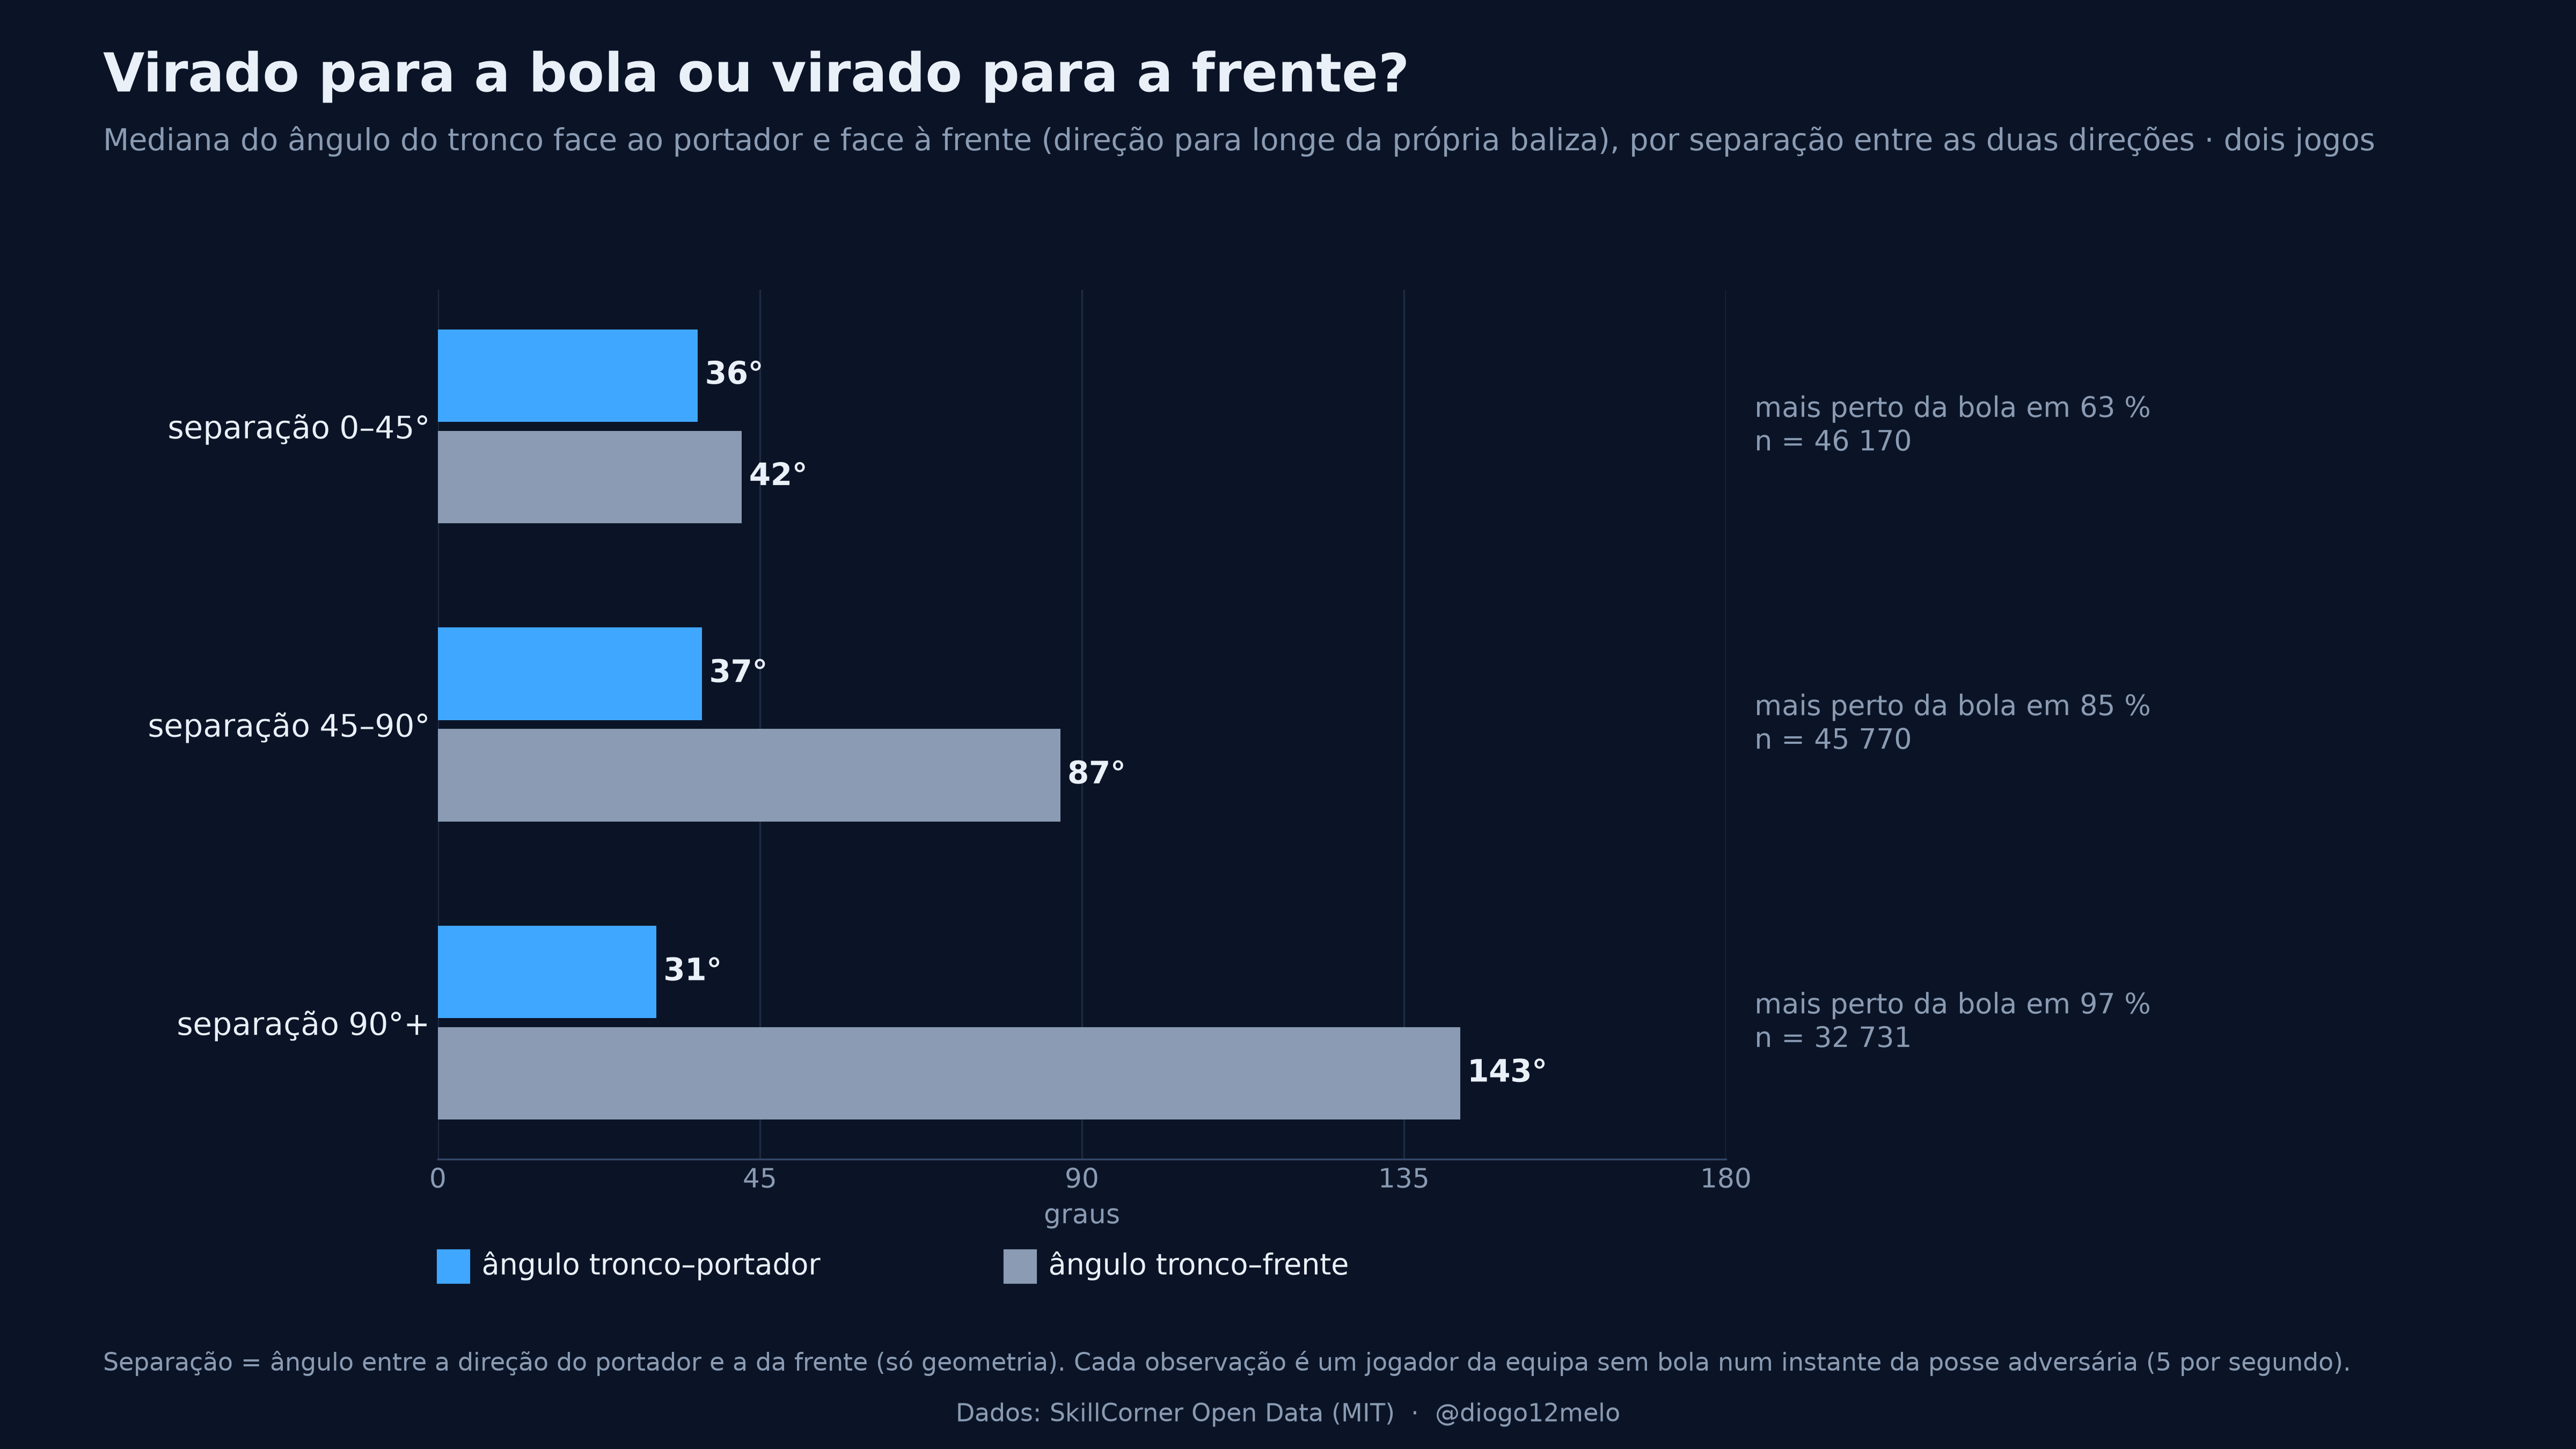

In [37]:
def tabela_bola_frente(t, colunas_iniciais):
    return pd.DataFrame({**{nome: t[col] for nome, col in colunas_iniciais},
                         "Separação bola–frente": t["separacao"], "Observações": t["n"],
                         "Mediana tronco–portador (°)": t["mediana_portador"].map(lambda v: pt(v, 1)),
                         "Mediana tronco–frente (°)": t["mediana_frente"].map(lambda v: pt(v, 1)),
                         "% mais perto da bola": t["pct_mais_perto_da_bola"].map(lambda v: pt(v, 1))}).style.hide(axis="index")


display(tabela_bola_frente(OD["bola_frente"], []))
destino_bf = SAIDA / "artigo" / "orientacao_bola_vs_frente.png"
od.figura_bola_vs_frente(OD["defesas"], brand, destino_bf)
display(Image(filename=str(destino_bf), width=900))

**Bola vs frente, por faixa de distância à bola e por grupo de posição.**

In [38]:
display(Markdown("*Por faixa de distância à bola*"))
display(tabela_bola_frente(OD["bola_frente_por_faixa"], [("Distância à bola", "faixa")]))
display(Markdown("*Por grupo de posição*"))
display(tabela_bola_frente(OD["bola_frente_por_grupo"], [("Grupo", "grupo")]))

*Por faixa de distância à bola*

Distância à bola,Separação bola–frente,Observações,Mediana tronco–portador (°),Mediana tronco–frente (°),% mais perto da bola
0–10 m,0–45°,10812,"29,8","40,5","68,6"
0–10 m,45–90°,8298,"33,6","90,4","89,3"
0–10 m,90°+,10335,"27,6","145,9","96,2"
10–20 m,0–45°,17809,"37,8","44,3","63,2"
10–20 m,45–90°,13700,"35,7","86,8","86,3"
10–20 m,90°+,10895,"28,0","142,2","97,2"
20–30 m,0–45°,12345,"38,1","43,7","60,9"
20–30 m,45–90°,13655,"36,9","80,6","81,4"
20–30 m,90°+,7319,"34,2","142,4","96,0"
30+ m,0–45°,5204,"41,2","38,2","52,8"


*Por grupo de posição*

Grupo,Separação bola–frente,Observações,Mediana tronco–portador (°),Mediana tronco–frente (°),% mais perto da bola
centrais,0–45°,9112,"37,7","48,6","68,4"
centrais,45–90°,9168,"36,8","82,8","86,8"
centrais,90°+,1220,"35,5","127,4","90,7"
laterais,0–45°,8220,"45,4","48,6","61,8"
laterais,45–90°,8767,"48,0","103,6","84,1"
laterais,90°+,3159,"37,7","146,2","95,3"
médios,0–45°,16133,"34,9","42,6","65,3"
médios,45–90°,11988,"38,1","96,1","89,3"
médios,90°+,10009,"32,7","147,8","97,7"
avançados,0–45°,12705,"32,4","35,5","55,9"


**Ligação ao C5.** Nas linhas em que o conjunto de defesas com sombra muda entre o cone pelo tronco e o cone virado para a
bola, cada registo é um jogador que faz sombra sobre uma linha só com um dos cones. Distância à bola e ângulo
tronco–portador são os desse jogador nesse instante (o ângulo é sempre o do tronco, também quando o cone é o virado para a bola).
Quem marca não projeta sombra (D5), por isso a marcação não aparece.

In [39]:
r = OD["resumo_mudancas"]
display(pd.DataFrame({"Jogador faz sombra": r["tipo"], "Registos": r["registos"],
                      "Distância à bola, mediana (m)": r["dist_mediana"].map(lambda v: pt(v, 1)),
                      "Quartis (m)": [f"{pt(a, 1)} – {pt(b, 1)}" for a, b in zip(r["dist_q1"], r["dist_q3"])],
                      "Ângulo tronco–portador, mediana (°)": r["mediana"].map(lambda v: pt(v, 1)),
                      "% até 45°": r["pct_ate_45"].map(lambda v: pt(v, 1)), "% até 90°": r["pct_ate_90"].map(lambda v: pt(v, 1)),
                      "% acima de 135°": r["pct_acima_135"].map(lambda v: pt(v, 1))}).style.hide(axis="index"))

Jogador faz sombra,Registos,"Distância à bola, mediana (m)",Quartis (m),"Ângulo tronco–portador, mediana (°)",% até 45°,% até 90°,% acima de 135°
só com o cone para a bola,19363,"12,5","6,5 – 20,4","41,1","56,3","97,0","0,1"
só com o cone pelo tronco,48649,"11,3","5,1 – 19,1","55,2","35,2","86,3","3,8"


## 5. Comparação com a SkillCorner (D15)

A SkillCorner regista opções de passe (`passing_option`) com o `xthreat` da opção: probabilidade de golo nos
10 s seguintes se o jogador for servido, não um ganho. O perigo de cada linha aqui é o ganho de xT numa grelha
de zonas (D15). Compara-se nas linhas que coincidem: mesmo portador e recetor, em frames alinhados dentro da
duração da opção. Uma opção da SkillCorner dá um ponto: o `xthreat` dela e a média, nos frames que coincidem,
do ganho de xT calculado. As duas medidas têm unidades diferentes; interessa a ordem (Spearman).

O perigo da linha (xT) não depende dos defesas nem das regras novas, por isso a v1 e a v2 só podem diferir
se a tabela de linhas mudar; calcula-se nas duas para o confirmar.

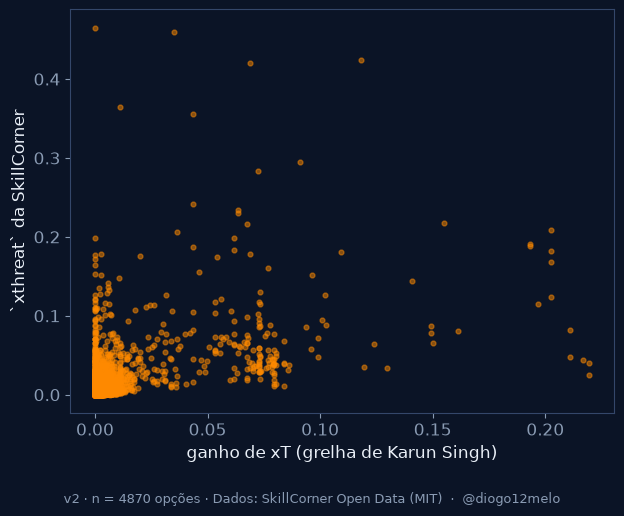

Versão,Opções da SkillCorner,Coincidem,Com ganho de xT = 0,ρ [IC 95%],Opções com ganho > 0,ρ só com ganho > 0 [IC 95%]
v1,5360,4870,1627,"0,417 [0,392; 0,442]",3243,"0,585 [0,559; 0,610]"
v2,5360,4870,1627,"0,417 [0,392; 0,442]",3243,"0,585 [0,559; 0,610]"


In [40]:
linhas_sc = []
for v in VERSOES:
    coincidencias = pd.concat([
        av.linhas_que_coincidem(av.opcoes_de_passe(JG[j]["eventos"]), ler(j, "base", v)[0]).assign(jogo=j) for j in JOGOS],
        ignore_index=True)
    total = sum(int(JG[j]["eventos"]["event_type"].eq("passing_option").sum()) for j in JOGOS)
    rho_sc = av.spearman_com_intervalo(coincidencias["valor_xt"], coincidencias["xthreat"])
    positivas = coincidencias[coincidencias["valor_xt"] > 0]
    rho_pos = av.spearman_com_intervalo(positivas["valor_xt"], positivas["xthreat"])
    linhas_sc.append({"Versão": v, "Opções da SkillCorner": total, "Coincidem": len(coincidencias),
                      "Com ganho de xT = 0": int((coincidencias["valor_xt"] == 0).sum()),
                      "ρ [IC 95%]": ic(*rho_sc), "Opções com ganho > 0": len(positivas), "ρ só com ganho > 0 [IC 95%]": ic(*rho_pos)})
    if v == "v2":
        fig, ax = plt.subplots(figsize=(6.4, 5.2))
        ax.scatter(coincidencias["valor_xt"], coincidencias["xthreat"], s=12, color=COR["primary"], alpha=0.5)
        ax.set_xlabel("ganho de xT (grelha de Karun Singh)")
        ax.set_ylabel("`xthreat` da SkillCorner")
        credito(fig, f"v2 · n = {len(coincidencias)} opções")
        fig.savefig(SAIDA / "fase5_skillcorner.png", dpi=150, facecolor=COR["background"])
        plt.show()
pd.DataFrame(linhas_sc).style.hide(axis="index")

## 6. C6 · Reprodutibilidade

- A execução `base` da v3 (parâmetros de partida, `avaliar_variantes.py --versao v3`) compara-se, tabela a tabela, com os
  resultados do notebook 04 (`calcular_metrica.py`), que correm com a mesma definição.
- A `base` da v1 foi comparada da mesma forma na altura (idênticas); hoje o notebook 04 já tem as regras novas,
  por isso a comparação deixou de se aplicar à v1. O código da v1 está no commit "avaliação v1, antes da revisão".
- Testes e lint correm a seguir, a partir deste notebook.
- A preparação (`preparar_dados.py`) e a métrica refazem-se de raiz com os comandos abaixo.

In [41]:
for j in JOGOS:
    linhas_04, atrib_04 = (pd.read_parquet(c) for c in caminhos(j))
    linhas_05, atrib_05 = ler(j, "base", "v3")
    try:
        pd.testing.assert_frame_equal(linhas_05, linhas_04)
        pd.testing.assert_frame_equal(atrib_05, atrib_04)
        resultado = "idênticas"
    except AssertionError as erro:
        resultado = f"diferem: {str(erro).splitlines()[0]}"
    print(f"{j}: {len(linhas_05)} linhas e {len(atrib_05)} atribuições; "
          f"ameaça negada total {linhas_05['ameaca_negada'].sum():.4f} xT; "
          f"tabelas do notebook 04 vs. desta fase: {resultado}")

1925299: 89150 linhas e 46398 atribuições; ameaça negada total 124.8168 xT; tabelas do notebook 04 vs. desta fase: idênticas
1996435: 81450 linhas e 53251 atribuições; ameaça negada total 94.3474 xT; tabelas do notebook 04 vs. desta fase: idênticas


In [42]:
for nome, comando in [("pytest", [sys.executable, "-m", "pytest", "-q"]),
                      ("ruff", [sys.executable, "-m", "ruff", "check", "src", "tests", "projects"])]:
    r = subprocess.run(comando, check=False, cwd=ROOT, capture_output=True, text=True)
    print(f"{nome}: código {r.returncode} · {(r.stdout.strip().splitlines() or [''])[-1]}")

pytest: código 0 · 443 passed, 5 warnings in 96.84s (0:01:36)


ruff: código 1 · [*] 1 fixable with `--fix` (10 unsafe fixes available with `--fix --unsafe-fixes`).


Do zero, no terminal (da raiz do repositório):

```
uv run python -m footy.ingest.skillcorner --tracking --pose      # só se data/raw estiver vazio (~700 MB)
uv run python projects/cover_shadow/preparar_dados.py --jogo 1925299
uv run python projects/cover_shadow/preparar_dados.py --jogo 1996435
uv run python projects/cover_shadow/calcular_metrica.py --jogo 1925299
uv run python projects/cover_shadow/calcular_metrica.py --jogo 1996435
uv run python projects/cover_shadow/avaliar_variantes.py --trabalhadores 6     # v2 (a v1 não se recalcula)
```

## 6A. v3.1 · a versão final (D43), com a v3 ao lado

A versão do artigo é a **v3.1** = v3 + exclusão das linhas com mais de 35 m (D37, D43). Esta secção repete a avaliação com a v3.1 e mostra os números da v3
ao lado. Tudo se lê de `outputs/cover_shadow/artigo_v31.json` (v3.1; `numeros_v31.py`) e de `outputs/cover_shadow/artigo_v3/numeros_das_figuras.json`
(v3, guardado antes de regenerar as figuras). Só números. O valor da sombra é um índice de fecho da linha, não uma probabilidade calibrada de o passe chegar.
A pasta `v3_1_literatura/` (modelo físico completo da D40, com `p_fundo`) **não** é a v3.1: ver a tabela da alínea 6A.1.

In [43]:
import json

V31 = json.loads((SAIDA / "artigo_v31.json").read_text(encoding="utf-8"))
V3 = json.loads((SAIDA / "artigo_v3" / "numeros_das_figuras.json").read_text(encoding="utf-8"))
ATUAL = json.loads((SAIDA / "artigo" / "numeros_das_figuras.json").read_text(encoding="utf-8"))
pt = lambda v, c=3: f"{v:.{c}f}".replace(".", ",")
print(V31["definicao"], "· comprimento_maximo_linha =", PADRAO_V31.comprimento_maximo_linha, "m")

{'versao': 'v3.1 (D43)', 'regra': 'v3 + exclusão das linhas com mais de 35 m (D37)', 'comprimento_maximo_linha_m': 35.0, 'valor_da_sombra': 'índice de fecho da linha, não probabilidade calibrada de o passe chegar'} · comprimento_maximo_linha = 35.0 m


### 6A.1 Definição e totais: v3.1 contra a v3 e contra `v3_1_literatura/`

In [44]:
v = ATUAL["versoes"]
display(pd.DataFrame([{"jogo": j, "versão": ver.replace("v3_1", "v3.1"), "% negada": round(v[f"{ver}_{j}"]["pct_negada"], 1),
                       "% de linhas excluídas": round(v[f"{ver}_{j}"]["pct_excluidas"], 1)} for j in JOGOS for ver in ("v3", "v3_1")]))
display(pd.DataFrame(V31["v3_1_literatura_vs_definicao"]).T.round(2).rename_axis("jogo"))

,jogo,versão,% negada,% de linhas excluídas
0,1925299,v3,46.9,33.5
1,1925299,v3.1,45.8,46.4
2,1996435,v3,39.4,25.6
3,1996435,v3.1,37.5,40.4


,linhas_avaliadas_v3_1,linhas_avaliadas_literatura,negada_v3_1,negada_literatura,disponivel_v3_1,disponivel_literatura,p_fundo_media_literatura
jogo,,,,,,,
1925299,47763.0,47763.0,108.74,24.97,237.27,81.24,0.71
1996435,48542.0,48542.0,78.68,19.11,210.04,72.36,0.66


### 6A.2 C3 · coerência com o jogo

In [45]:
c3 = pd.DataFrame({"v3": V3["c3"]["v3"], "v3.1": V31["c3"]})
chaves = ["n", "dif_controlada", "dif_controlada_inf", "dif_controlada_sup", "dif_sem_controlo", "dif_sem_controlo_inf",
          "dif_sem_controlo_sup", "n_baixa", "completos_baixa", "taxa_baixa"]
display(c3.loc[chaves].astype(float).round(3))

,v3,v3.1
n,1087.000,1071.000
dif_controlada,-0.121,-0.118
dif_controlada_inf,-0.139,-0.137
dif_controlada_sup,-0.102,-0.099
dif_sem_controlo,-0.142,-0.117
dif_sem_controlo_inf,-0.154,-0.130
dif_sem_controlo_sup,-0.128,-0.104
n_baixa,86.000,84.000
completos_baixa,53.000,53.000
taxa_baixa,0.616,0.631


### 6A.3 C4 · estabilidade (v3.1 com a v3 ao lado; inclui os limites de 30 e 40 m)

In [46]:
c4_31 = pd.DataFrame(V31["c4"]).set_index("variante")
c4_3 = pd.DataFrame(V3["c4"]).set_index("variante")
t = c4_31[["rho_jogador", "rho_jogador_minimo", "rho_lance", "pct_1925299", "pct_1996435"]].join(
    c4_3[["rho_jogador", "pct_1925299", "pct_1996435"]], rsuffix="_v3")
t.columns = ["ρ jogador", "ρ mínimo", "ρ lance", "% negada 1925299", "% negada 1996435", "ρ jogador (v3)", "% 1925299 (v3)", "% 1996435 (v3)"]
display(t.round(3))
print(f"v3.1: ρ por jogador de {t['ρ jogador'].min():.3f} a {t['ρ jogador'].max():.3f}; ρ por lance a partir de {t['ρ lance'].min():.3f}")

,ρ jogador,ρ mínimo,ρ lance,% negada 1925299,% negada 1996435,ρ jogador (v3),% 1925299 (v3),% 1996435 (v3)
variante,,,,,,,,
angulo_cone=45,0.985,0.800,0.987,44.860,36.392,1.000,45.781,38.141
angulo_cone=90,0.997,0.983,0.979,47.324,39.563,1.000,48.810,41.871
comprimento_cone=8,0.994,0.976,0.960,45.599,37.163,0.993,46.748,38.892
comprimento_cone=12,0.991,0.900,0.962,45.794,37.661,0.994,46.903,39.580
largura_junto_ao_corpo=1,0.975,0.800,0.957,41.389,33.446,0.975,42.640,35.362
largura_junto_ao_corpo=3,0.988,0.900,0.978,47.281,39.313,1.000,48.546,41.389
tempo_reacao=0.5,0.997,0.983,0.994,49.843,42.064,1.000,51.148,44.396
tempo_reacao=0.9,0.996,0.976,0.995,43.015,33.978,0.977,43.670,35.438
velocidade_bola=12,0.997,0.983,0.993,49.960,42.531,1.000,51.544,45.199


v3.1: ρ por jogador de 0.849 a 1.000; ρ por lance a partir de 0.896


### 6A.4 C5 · tronco contra bola

In [47]:
c5_3, c5_31 = V3["c5"], V31["c5"]
pc3 = {str(k): v for k, v in c5_3["pct_negada"].items()}
linhas5 = {
    "ρ por jogador": (c5_3["rho"], c5_31["rho_media"]),
    "ρ mínimo": (c5_3["rho_min"], c5_31["rho_minimo"]),
    "% de linhas em que muda a sombra": (c5_3["pct_mudam"], c5_31["pct_mudam"]),
    "linhas": (c5_3["linhas"], c5_31["linhas"]),
}
for j in ("1925299", "1996435"):
    linhas5[f"% negada {j} (tronco / bola)"] = (" / ".join(pt(x, 1) for x in pc3[j]), " / ".join(pt(x, 1) for x in c5_31["pct_negada_tronco_bola"][j]))
display(pd.DataFrame(linhas5, index=["v3", "v3.1"]).T)

,v3,v3.1
ρ por jogador,0.972058,0.944699
ρ mínimo,0.8,0.4
% de linhas em que muda a sombra,40.078191,36.594154
linhas,119963,96305
% negada 1925299 (tronco / bola),"46,9 / 49,2","45,8 / 47,9"
% negada 1996435 (tronco / bola),"39,4 / 43,5","37,5 / 40,9"


### 6A.5 C6 · reprodutibilidade da v3.1
Recálculo a partir dos dados originais (`reprodutibilidade_v31.py`: `preparar_dados.py` e a métrica v3.1) e comparação, tabela a tabela, com as guardadas; a suíte de testes corre a seguir.

In [48]:
c6 = V31["c6"]
display(pd.DataFrame({k: {"linhas": v["linhas_antes"], "iguais": v["iguais"], "maior diferença": v["maior_diferenca_absoluta"]} for k, v in c6["tabelas"].items()}).T)
print("todas iguais:", c6["todas_iguais"], "·", c6["testes"]["resumo"])

,linhas,iguais,maior diferença
v3.1 linhas 1925299,89150,True,0.0
v3.1 atribuicoes 1925299,32753,True,0.0
posses_pose 1925299,196130,True,0.0
ultrapassados 1925299,89150,True,0.0
v3.1 linhas 1996435,81450,True,0.0
v3.1 atribuicoes 1996435,36606,True,0.0
posses_pose 1996435,179190,True,0.0
ultrapassados 1996435,81450,True,0.0


todas iguais: True · 435 passed, 5 warnings in 93.76s (0:01:33)


### 6A.6 C1 e C2 · os lances W01 a W08 na v3.1 (descritivo, sem nova ronda)
Ameaça negada no lance (xT) e linhas de mais de 35 m que saem do lance, com a v3 ao lado.

In [49]:
w = V31["lances_w01_w08"]
display(pd.DataFrame([{"lance": k, "jogo": x["jogo"], "frame": x["frame"], "linhas de mais de 35 m": x["linhas_de_mais_de_35m_no_lance"],
                       "perigo v3": round(x["v3"]["perigo"], 4), "negada v3": round(x["v3"]["negada"], 4),
                       "perigo v3.1": round(x["v3_1_xt"]["perigo"], 4), "negada v3.1": round(x["v3_1_xt"]["negada"], 4),
                       "negada v3.1 (linhas)": round(x["v3_1_linhas"]["negada"], 2),
                       "defesas v3.1 (xT)": ", ".join(f"{n} {pt(s, 4)}" for n, s in x["v3_1_xt"]["shapley"].items())} for k, x in w.items()]))

,lance,jogo,frame,linhas de mais de 35 m,perigo v3,negada v3,perigo v3.1,negada v3.1,negada v3.1 (linhas),defesas v3.1 (xT)
0,W01,1925299,14478,1,0.2274,0.1722,0.2104,0.1583,0.00,"T. Gomulka 0,0864, N. Pennington 0,0464, R. Wa..."
1,W02,1925299,50612,1,0.4582,0.4276,0.4582,0.4276,13.85,"T. Gomulka 0,1677, J. Carluccio 0,1428, N. Pen..."
2,W03,1925299,57378,4,0.4385,0.4352,0.3683,0.3651,0.00,"J. Carluccio 0,2085, N. Pennington 0,1565, K. ..."
3,W04,1996435,45252,1,0.2905,0.0365,0.2905,0.0365,0.00,"J. Courtney-Perkins 0,0186, R. Grant 0,0116, C..."
4,W05,1996435,13394,0,0.4582,0.4436,0.4582,0.4436,8.72,"E. Alagich 0,4408, P. Kikianis 0,0015, F. Tall..."
5,W06,1925299,38118,1,0.0057,0.0030,0.0054,0.0027,3.00,"A. Bugarija 0,0027, A. Faisal 0,0000"
6,W07,1996435,32452,3,0.0063,0.0001,0.0041,0.0000,0.00,"Léo Sena 0,0000, K. Shaw 0,0000"
7,W08,1996435,38680,2,0.0054,0.0000,0.0054,0.0000,0.01,"B. Vriends 0,0000"


### 6A.7 Segunda leitura: a moeda «linhas quebradas»
Valor de cada linha = nº de adversários de campo (sem GR) ultrapassados pelo passe; `negada_linhas = Σ linhas_l · (1 − p_l(C))`, mesmo Shapley e mesma agregação.

In [50]:
m = V31["segunda_leitura_moedas"]
display(pd.DataFrame(m["totais"]).T.round(2))
ROT = {"high_block": "bloco alto", "medium_block": "bloco médio", "low_block": "bloco baixo", "chaotic": "caótica", "defending_direct": "defesa de jogo direto",
       "defending_set_play": "bola parada", "defending_quick_break": "contra-ataque", "defending_transition": "transição defensiva",
       "attacking_third": "terço ofensivo", "middle_third": "terço médio", "defensive_third": "terço defensivo"}
for por in ("fase", "terco"):
    a = pd.DataFrame(m["fase_e_terco"]["xt"][por]).set_index(por)[["lances", "pct_negada"]]
    b = pd.DataFrame(m["fase_e_terco"]["linhas"][por]).set_index(por)[["pct_negada"]]
    t = a.join(b, rsuffix="_linhas").rename(columns={"lances": "momentos", "pct_negada": "% negada xT", "pct_negada_linhas": "% negada linhas"})
    t.index = [ROT.get(i, str(i)) for i in t.index]
    display(t.round(1))
r = m["rho_entre_moedas"]
print(f"ρ por jogador entre as duas moedas, dentro da posição: média {pt(r['media'])}, mínimo {pt(r['minimo'])}")
for lance in ("C06", "C03"):
    for moeda in ("xt", "linhas"):
        x = m[lance][moeda]
        print(lance, moeda, f"perigo {pt(x['perigo'], 3)} · negada {pt(x['negada'], 3)} ·", {k: round(s, 4) for k, s in x["shapley"].items()})

,lances,disponivel,negada,pct_negada
xt,16299.0,447.31,187.41,41.90
linhas,16299.0,133852.00,35440.01,26.48


,momentos,% negada xT,% negada linhas
bola parada,246,53.9,41.9
contra-ataque,380,53.2,23.5
caótica,904,50.8,27.7
bloco baixo,4938,44.4,31.3
transição defensiva,315,39.3,21.1
bloco médio,6137,24.0,23.9
bloco alto,3349,21.1,22.7
defesa de jogo direto,26,21.1,27.2
None,4,0.0,0.0


,momentos,% negada xT,% negada linhas
terço ofensivo,4001,50.5,34.5
terço médio,6951,28.6,26.2
terço defensivo,5347,20.8,22.8


ρ por jogador entre as duas moedas, dentro da posição: média 0,748, mínimo 0,548
C06 xt perigo 0,024 · negada 0,004 · {'K. Jelacic': 0.0043}
C06 linhas perigo 16,000 · negada 3,352 · {'K. Jelacic': 3.3516}
C03 xt perigo 0,023 · negada 0,004 · {'P. Klimala': 0.0042}
C03 linhas perigo 20,000 · negada 3,042 · {'P. Klimala': 3.0419}


### 6A.8 As duas moedas dentro de cada fase defensiva
ρ por jogador entre xT e linhas, dentro da posição, em cada bloco (só os frames da fase); parte da ameaça negada total que cada fase reúne em cada moeda;
os dois momentos de bloco alto ou médio em que as moedas mais discordam em cada sentido (percentil da ameaça negada do momento entre os momentos dessas fases).

In [51]:
f = V31["moedas_por_fase"]
display(pd.DataFrame(f["rho_por_jogador_dentro_da_posicao"]).T[["media", "minimo", "n_jogadores", "n_posicoes"]].rename(
    index=ROT, columns={"media": "ρ médio", "minimo": "ρ mínimo", "n_jogadores": "n (jogadores)", "n_posicoes": "posições"}).astype(float).round(3))
p = f["parte_da_negada_total_por_fase"]
t = pd.DataFrame(p["xt"]).set_index("fase")[["pct_da_negada_total"]].join(pd.DataFrame(p["linhas"]).set_index("fase")[["pct_da_negada_total"]], rsuffix="_linhas")
t.columns = ["% da negada total (xT)", "% da negada total (linhas)"]
t.index = [ROT.get(i, str(i)) for i in t.index]
display(t.round(1))
print(f"bloco alto + médio: {pt(p['xt_bloco_alto_mais_medio'], 1)} % da negada total em xT contra {pt(p['linhas_bloco_alto_mais_medio'], 1)} % em linhas")

,ρ médio,ρ mínimo,n (jogadores),posições
bloco alto,0.915,0.400,52.0,9.0
bloco médio,0.993,0.976,53.0,9.0
bloco baixo,0.791,0.400,53.0,9.0


,% da negada total (xT),% da negada total (linhas)
bloco baixo,59.2,34.6
bola parada,14.6,4.6
contra-ataque,9.5,0.6
bloco médio,8.8,36.6
caótica,3.5,4.7
bloco alto,2.5,18.1
transição defensiva,1.9,0.7
defesa de jogo direto,0.0,0.2
None,0.0,0.0


bloco alto + médio: 11,3 % da negada total em xT contra 54,6 % em linhas


,grupo,jogo,frame,fase,negada xT,percentil xT,negada linhas,percentil linhas
0,"xT alto, linhas baixo",1996435,28188,bloco alto,0.0459,1.00,0.00,0.14
1,"xT alto, linhas baixo",1996435,55052,bloco alto,0.0063,0.89,0.00,0.14
2,"linhas alto, xT baixo",1925299,3584,bloco alto,0.0000,0.11,22.00,1.00
3,"linhas alto, xT baixo",1996435,42752,bloco alto,0.0000,0.11,11.87,0.98


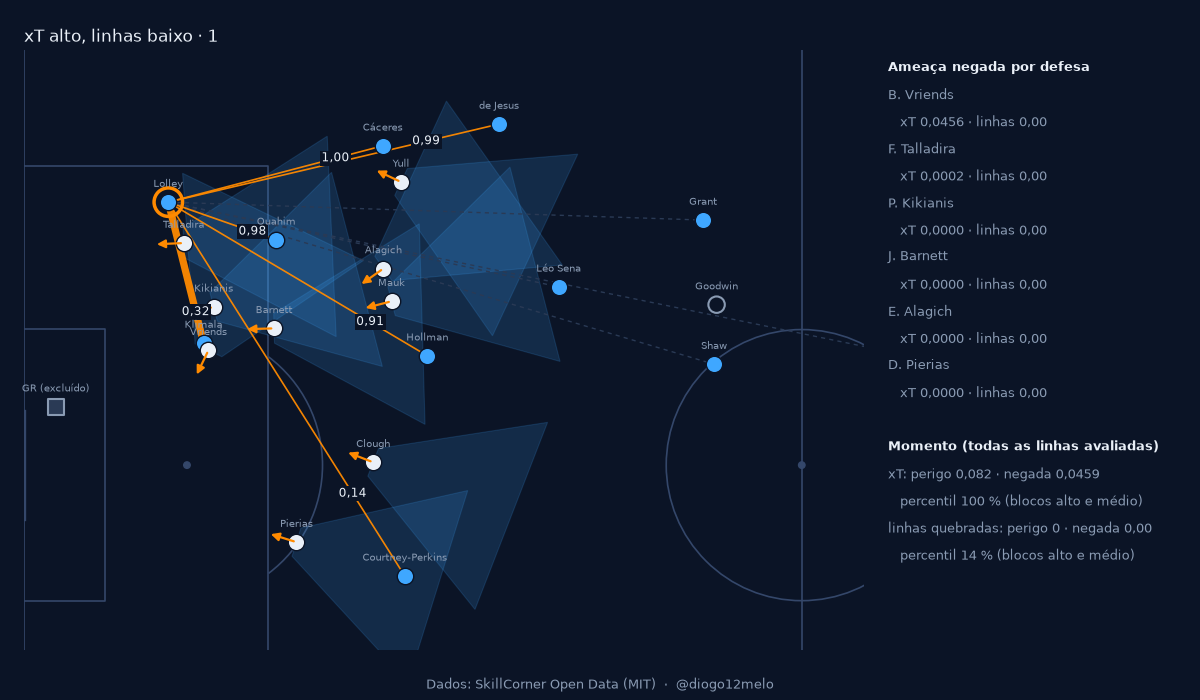

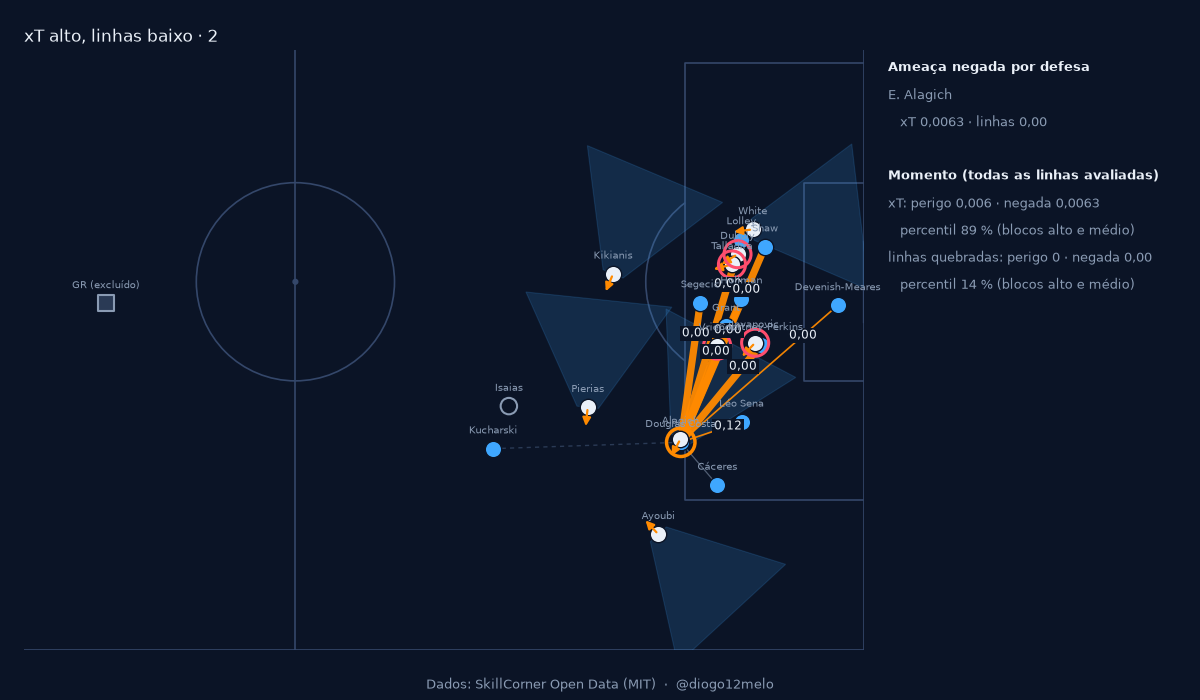

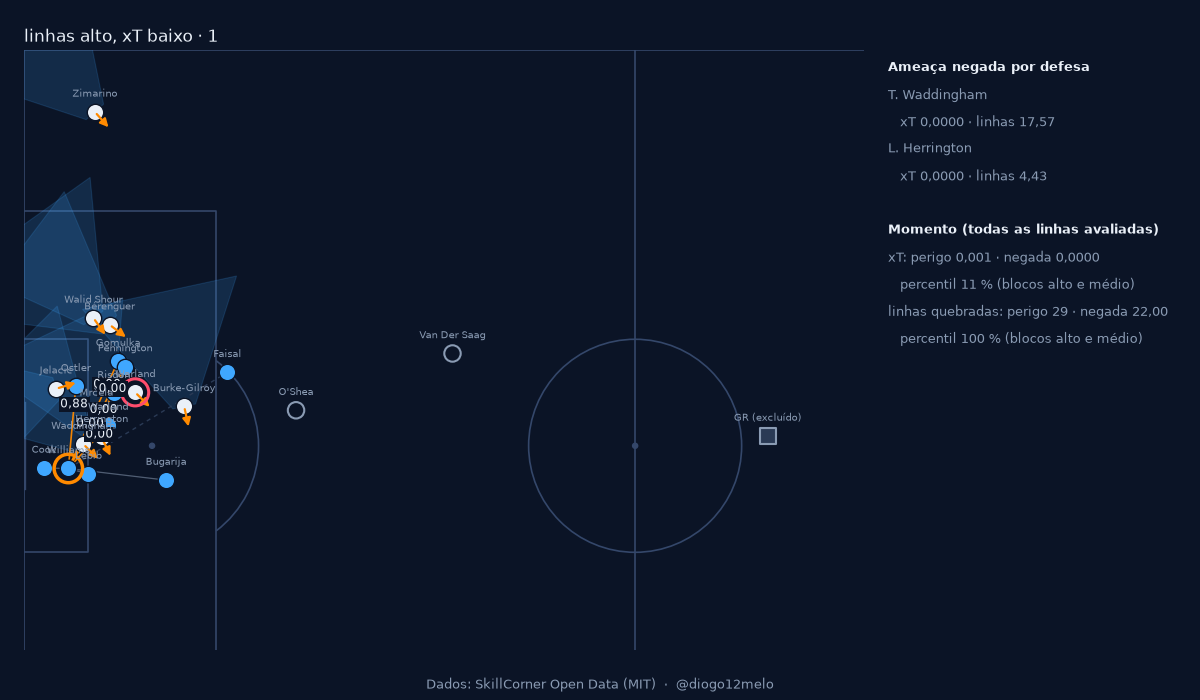

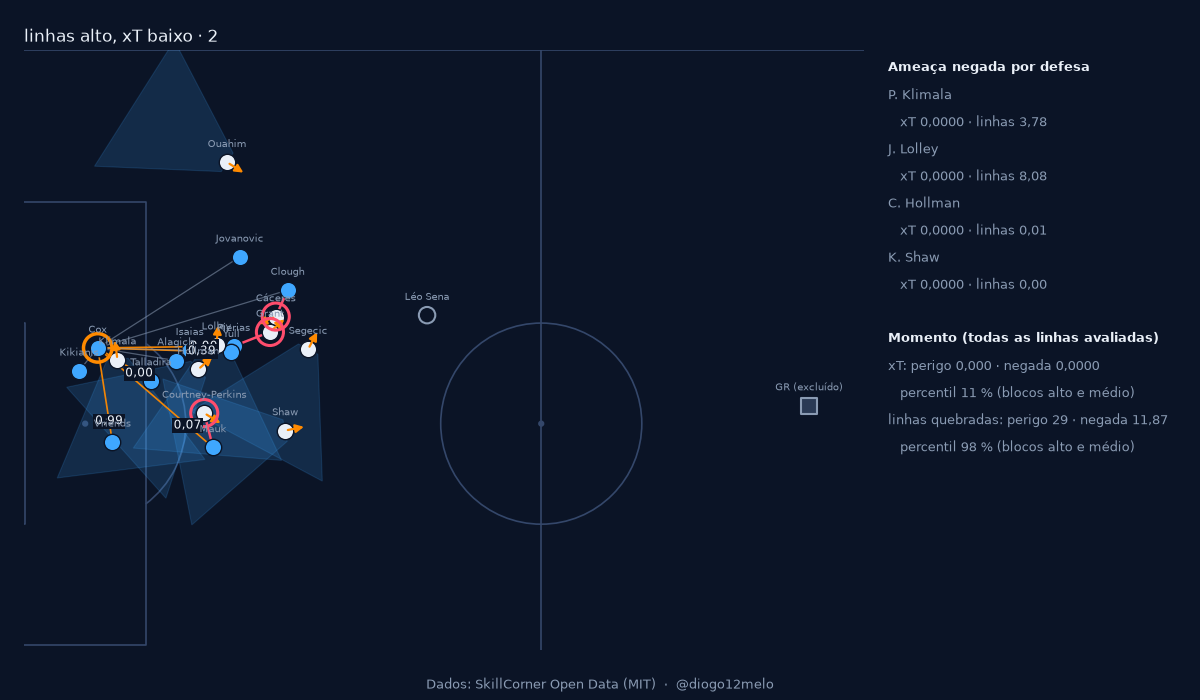

In [52]:
linhas_m = []
for grupo, rot in (("xt_alto", "xT alto, linhas baixo"), ("linhas_alto", "linhas alto, xT baixo")):
    for x in f["momentos_que_mais_discordam"][grupo]:
        linhas_m.append({"grupo": rot, "jogo": x["jogo"], "frame": x["frame"], "fase": ROT[x["fase"]],
                         "negada xT": round(x["xt"]["negada"], 4), "percentil xT": round(x["percentil_xt"], 2),
                         "negada linhas": round(x["linhas"]["negada"], 2), "percentil linhas": round(x["percentil_linhas"], 2)})
display(pd.DataFrame(linhas_m))
for grupo in ("xt_alto", "linhas_alto"):
    for x in f["momentos_que_mais_discordam"][grupo]:
        display(Image(filename=str(ROOT / x["imagem"]), width=900))

### 6A.9 Momento da decisão: só os últimos 1 s e 2 s da posse individual

In [53]:
d = V31["momento_da_decisao"]
display(pd.DataFrame(d["rho_por_posicao"]).T.rename(columns={"media": "ρ médio", "minimo": "ρ mínimo"}).astype(float).round(3))
for j, x in d["posses_por_tipo_de_fim"].items():
    display(pd.DataFrame(x).fillna(0).astype(int).rename_axis(f"jogo {j}"))
for chave in ("xt_1s", "xt_2s"):
    print(chave, "sobem:", [(x["nome"], x["posicao"], round(x["variacao"], 2)) for x in d["sobem_e_descem"][chave]["sobem"]])
    print(chave, "descem:", [(x["nome"], x["posicao"], round(x["variacao"], 2)) for x in d["sobem_e_descem"][chave]["descem"]])

,ρ médio,ρ mínimo,jogadores
xt_1s,0.953,0.7,58.0
xt_2s,0.969,0.8,58.0
linhas_1s,0.953,0.8,58.0
linhas_2s,0.953,0.8,58.0


,posses_alinhadas,posses_com_frames_1s,posses_com_frames_2s
jogo 1925299,,,
pass,805,805,805
possession_loss,69,69,69
shot,20,20,20
clearance,16,16,16
foul_suffered,11,11,11
unknown,3,2,3


,posses_alinhadas,posses_com_frames_1s,posses_com_frames_2s
jogo 1996435,,,
pass,759,759,759
possession_loss,63,63,63
shot,22,22,22
clearance,13,13,13
foul_suffered,8,8,8
unknown,7,6,6


xt_1s sobem: [('H. Van Der Saag', 'RB', 0.4), ('J. Courtney-Perkins', 'LB', 0.25), ('N. Acosta', 'RW', 0.12), ('L. Jovanovic', 'CF', 0.0), ('R. White', 'AM', 0.0), ('Z. Clough', 'RW', 0.0), ('J. Kucharski', 'LW', 0.0), ('A. Ouahim', 'LW', 0.0), ('A. Segecic', 'RDM', 0.0), ('A. Goodwin', 'CF', 0.0)]
xt_1s descem: [('R. Warland', 'LB', -0.25), ('D. Pierias', 'RB', -0.2), ('Z. de Jesus', 'RB', -0.2), ('A. Ayoubi', 'RW', -0.12), ('J. Risdon', 'RB', 0.0), ('J. Carluccio', 'RW', 0.0), ('D. Williams', 'CF', 0.0), ('T. Mrčela', 'LCB', 0.0), ('T. Ostler', 'RW', 0.0), ('N. Blair', 'CF', 0.0)]
xt_2s sobem: [('J. Courtney-Perkins', 'LB', 0.25), ('H. Van Der Saag', 'RB', 0.2), ('K. Jelacic', 'LW', 0.12), ('L. Jovanovic', 'CF', 0.11), ('A. Ayoubi', 'RW', 0.0), ('C. Hollman', 'RDM', 0.0), ('J. Kucharski', 'LW', 0.0), ('A. Goodwin', 'CF', 0.0), ('A. Segecic', 'RDM', 0.0), ('Isaias', 'RDM', 0.0)]
xt_2s descem: [('R. Warland', 'LB', -0.25), ('Z. de Jesus', 'RB', -0.2), ('A. Ouahim', 'LW', -0.12), ('Doug

### 6A.10 C8 e xPass (resultados já calculados, 8b e 9a)

In [54]:
jc = V31["ja_calculado"]
c8 = jc["c8"]
print("C8 · coeficientes do M3:", {k: round(v["coef"], 3) for k, v in c8["coeficientes_M3"].items() if k.startswith("sombra")})
display(pd.DataFrame({k: {m_: v["modelos"][m_]["log_loss"] for m_ in ("M0", "M1", "M2", "M3")} for k, v in c8["fora_da_amostra"].items()}).round(3))
xp = jc["xpass"]
print("K1:", xp["K1"])
print("γ (dois jogos):", xp["gamma_dois_jogos"])
print("log-loss com e sem sombra:", {k: round(v["log_loss"], 4) for k, v in xp["log_loss_com_e_sem_sombra"].items()})
print(xp["veredicto"])

C8 · coeficientes do M3: {'sombra_bola': -0.414, 'sombra_tronco': -1.362}


,1925299_para_1996435,1996435_para_1925299
M0,1.478,1.534
M1,1.430,1.483
M2,1.419,1.480
M3,1.420,1.479


K1: {'ece': 0.0051838182621618345, 'limite_ece': 0.03, 'jogos_a_bater_a_taxa_base': 20, 'minimo_de_jogos': 16, 'cumpre': True}
γ (dois jogos): {'tronco': {'gamma': -0.3735874748912807, 'erro_padrao': 0.29660865391514735, 'ic95': [-0.9549404365649694, 0.20776548678240808], 'n': 1408}, 'bola': {'gamma': -0.3401838450034047, 'erro_padrao': 0.2727417131496178, 'ic95': [-0.8747576027766556, 0.19438991276984618], 'n': 1408}}
log-loss com e sem sombra: {'sem_sombra': 0.2676, 'tronco': 0.2693, 'bola': 0.2684}
{'moedas_que_passam': [], 'decisao': 'v4 não aceite: o artigo segue com a v3.1'}


### 6A.11 Terceira moeda: «risco»
Valor negado numa linha = `(p_l(∅) − p_l(C)) · (g_l + c_l)`, com `p_l(∅) = 1` na v3.1, `g_l` = ganho de xT e `c_l` = xT do adversário no ponto onde a linha seria cortada
(grelha invertida; ponto onde o defesa com maior probabilidade de corte, todos os defesas incluídos, a corta com mais probabilidade; parâmetros da literatura). Nunca é negativa.
Mesmo Shapley e mesma agregação; a ameaça disponível da linha passa a ser `g + c`. Números calculados em `numeros_9c.py` (`fase9c.json`, também em `artigo_v31.json`, secção `fase_9c`).

In [55]:
F9C = V31["fase_9c"]
mr = F9C["moeda_risco"]
display(pd.DataFrame(mr["totais"]).T.round(2))
c = mr["custo_da_perda"]
print(f"linhas avaliadas {c['linhas_avaliadas']:,} · custo c médio {pt(c['custo_medio'], 4)} · ganho g médio {pt(c['ganho_medio'], 4)} · "
      f"{pt(c['pct_linhas_com_ganho_zero'], 1)} % das linhas com g = 0 · {pt(c['pct_linhas_com_custo_maior_que_ganho'], 1)} % com c > g")
print("percentis do custo:", {k: pt(v, 4) for k, v in c["percentis_custo"].items()}, "· do ganho:", {k: pt(v, 4) for k, v in c["percentis_ganho"].items()})

,lances,disponivel,negada,pct_negada
xt,16299.0,447.31,187.41,41.90
linhas,16299.0,133852.00,35440.01,26.48
risco,16299.0,2649.67,521.53,19.68


linhas avaliadas 96,305 · custo c médio 0,0229 · ganho g médio 0,0046 · 45,1 % das linhas com g = 0 · 92,9 % com c > g
percentis do custo: {'0.1': '0,0100', '0.25': '0,0113', '0.5': '0,0148', '0.75': '0,0239', '0.9': '0,0351', '0.99': '0,2575'} · do ganho: {'0.5': '0,0004', '0.75': '0,0030', '0.9': '0,0076', '0.99': '0,0795'}


**Ponto de corte dentro da área de quem tem a bola** (área grande: 16,5 m × 40,32 m a partir da linha de baliza própria). Linhas avaliadas, dois jogos juntos, e as mesmas linhas na moeda xT.

In [56]:
z = F9C["moeda_risco"]["corte_na_area_propria"]
display(pd.DataFrame({k: z["juntos"][k] for k in ("corte_na_area_propria", "corte_fora_da_area")}).round(4))
print("as mesmas linhas, ameaça negada total:", {k: round(v, 4) for k, v in z["mesmas_linhas_em_xt"].items()})
print("linhas com g = 0 e sombra:", {k: round(v, 3) for k, v in F9C["moeda_risco"]["linhas_sem_ganho_de_xt_com_sombra"].items()})

,corte_na_area_propria,corte_fora_da_area
linhas,5845.0000,90460.0000
pct_das_linhas,6.0693,93.9307
custo_medio,0.1160,0.0169
custo_maximo,0.2575,0.1081
ganho_medio,0.0007,0.0049
valor_medio_g_mais_c,0.1167,0.0218
linhas_com_sombra,2182.0000,46064.0000
negada_media_por_linha_com_sombra,0.0363,0.0096
pct_da_negada_total,15.1911,84.8089


as mesmas linhas, ameaça negada total: {'linhas': 5845, 'negada_risco': 79.2264, 'negada_xt': 0.7161, 'negada_media_risco_por_linha_com_sombra': 0.0363, 'negada_media_xt_por_linha_com_sombra': 0.0003}
linhas com g = 0 e sombra: {'linhas': 19249, 'pct_com_corte_na_area_propria': 4.478, 'negada_risco': 124.146, 'pct_da_negada_risco_total': 23.804}


### 6A.12 Índice por fase defensiva (xT, linhas, risco)
Índice do jogador numa fase = ameaça negada por momento / média por momento de todos os jogadores nessa fase × 100 (100 = média da fase); um momento = um frame alinhado (0,2 s) em que o jogador defende nessa fase.
Percentil dentro da fase entre os jogadores com pelo menos 100 momentos (20 s) na fase. Tabela completa por jogador: `outputs/cover_shadow/indice_por_fase.csv`.

In [57]:
ROT = {"high_block": "bloco alto", "medium_block": "bloco médio", "low_block": "bloco baixo", "chaotic": "caótica", "defending_direct": "defesa de jogo direto",
       "defending_set_play": "bola parada", "defending_quick_break": "contra-ataque", "defending_transition": "transição defensiva"}
ip = F9C["indice_por_fase"]
for moeda in ("xt", "linhas", "risco"):
    t = pd.DataFrame(ip[moeda]["distribuicao_por_fase"]).set_index("fase")
    t.index = [ROT.get(i, i) for i in t.index]
    print("moeda", moeda)
    display(t.round(1))

moeda xt


,jogadores,fora_por_poucos_momentos,mediana,p90,maximo
caótica,42,16,23.7,91.7,3698.6
defesa de jogo direto,0,48,NaN,NaN,NaN
contra-ataque,10,39,106.5,372.2,558.1
bola parada,8,42,73.5,236.2,292.5
transição defensiva,17,21,15.7,355.6,798.1
bloco alto,54,3,65.8,265.4,509.6
bloco baixo,55,3,54.7,193.3,347.7
bloco médio,56,2,85.6,196.0,497.5


moeda linhas


,jogadores,fora_por_poucos_momentos,mediana,p90,maximo
caótica,42,16,55.4,269.5,643.9
defesa de jogo direto,0,48,NaN,NaN,NaN
contra-ataque,10,39,75.6,213.6,322.4
bola parada,8,42,137.6,321.0,370.2
transição defensiva,17,21,16.4,222.7,331.8
bloco alto,54,3,70.6,240.9,356.7
bloco baixo,55,3,68.3,249.5,401.1
bloco médio,56,2,95.9,222.8,493.4


moeda risco


,jogadores,fora_por_poucos_momentos,mediana,p90,maximo
caótica,42,16,72.1,208.7,589.0
defesa de jogo direto,0,48,NaN,NaN,NaN
contra-ataque,10,39,106.0,323.8,448.4
bola parada,8,42,111.9,221.6,235.5
transição defensiva,17,21,67.2,256.2,351.2
bloco alto,54,3,61.1,279.0,610.4
bloco baixo,55,3,84.7,215.7,440.4
bloco médio,56,2,101.5,245.4,602.0


### 6A.13 Números por fase: ρ entre as três moedas e parte da ameaça negada total
ρ de Spearman por jogador dentro da posição, em cada bloco (só os frames da fase), e parte (%) da ameaça negada total que cada fase reúne em cada moeda.

In [58]:
n = F9C["numeros_por_fase"]
linhas_rho = []
for fase, d in n["rho_por_jogador_dentro_da_posicao"].items():
    for par, v in d.items():
        linhas_rho.append({"fase": ROT[fase], "par de moedas": par.replace("_", " · "), "ρ médio": v["media"], "ρ mínimo": v["minimo"], "n (jogadores)": v["n_jogadores"]})
display(pd.DataFrame(linhas_rho).set_index(["fase", "par de moedas"]).round(3))
p = {m: pd.DataFrame(n["parte_da_negada_total_por_fase"][m]).dropna(subset=["fase"]).set_index("fase")["pct_da_negada_total"] for m in ("xt", "linhas", "risco")}
t = pd.DataFrame(p)
t.index = [ROT.get(i, i) for i in t.index]
display(t.round(1).rename(columns=lambda m: f"% da negada total ({m})"))

ρ médio  ρ mínimo  n (jogadores)
fase        par de moedas                                   
bloco alto  xt · linhas       0.915     0.400             52
            xt · risco        0.824     0.200             52
            linhas · risco    0.894     0.600             52
bloco médio xt · linhas       0.993     0.976             53
            xt · risco        0.950     0.900             53
            linhas · risco    0.954     0.881             53
bloco baixo xt · linhas       0.791     0.400             53
            xt · risco        0.897     0.700             53
            linhas · risco    0.821     0.400             53

,% da negada total (xt),% da negada total (linhas),% da negada total (risco)
caótica,3.5,4.7,8.9
defesa de jogo direto,0.0,0.2,0.2
contra-ataque,9.5,0.6,4.5
bola parada,14.6,4.6,7.4
transição defensiva,1.9,0.7,2.0
bloco alto,2.5,18.1,22.0
bloco baixo,59.2,34.6,34.8
bloco médio,8.8,36.6,20.2


### 6A.14 Casos concretos (imagens em `outputs/cover_shadow/momentos_9c/`)
Momentos de bloco alto em que um avançado tem sombra sobre a linha do guarda-redes ou de um central para um colega junto à área, com o portador na própria área ou a menos de 5 m dela;
os quatro momentos da 9b, agora com a moeda risco; C06 e C03 nas três moedas. Cada imagem mostra, por defesa, a ameaça negada e o índice na fase em cada moeda.

In [59]:
print({k: v for k, v in F9C["casos"]["bloco_alto_criterios"].items() if k != "criterios"}, F9C["casos"]["bloco_alto_criterios"]["criterios"])
def resumo(x):
    return {"jogo": x["jogo"], "frame": x["frame"], "fase": ROT.get(x["fase"], x["fase"]), **{f"negada {m}": round(x[m]["negada"], 4) for m in ("xt", "linhas", "risco")},
            **{f"percentil {m}": round(x["percentil"][m], 0) for m in ("xt", "linhas", "risco")}}
display(pd.DataFrame([resumo(x) for x in F9C["casos"]["bloco_alto"]]))
display(pd.DataFrame([{k: (round(v, 4) if isinstance(v, float) else v) for k, v in x["linha"].items()} for x in F9C["casos"]["bloco_alto"]]))
display(pd.DataFrame([resumo(x) | {"grupo": g} for g, l in F9C["casos"]["momentos_9b"].items() for x in l]))
display(pd.DataFrame([resumo(x) | {"lance": k} for k, x in F9C["casos"]["C06_e_C03"].items()]))
for k, x in F9C["casos"]["C06_e_C03"].items():
    for m in ("xt", "linhas", "risco"):
        print(k, m, {n: round(s, 4) for n, s in x[m]["shapley"].items()})

{'linhas_candidatas': 1076, 'momentos_candidatos': 640, 'posses_candidatas': 97} {'fase': 'high_block', 'portador': ['GK', 'LCB', 'RCB'], 'portador_a_menos_de_m_da_propria_baliza': 21.5, 'sombra_de': ['CF', 'LW', 'RW'], 'recetor_a_menos_de_m_da_baliza_do_portador': 26.5, 'ordem': 'Shapley do avançado nessa linha na moeda risco'}


,jogo,frame,fase,negada xt,negada linhas,negada risco,percentil xt,percentil linhas,percentil risco
0,1925299,56018,bloco alto,0.0003,3.4269,0.9395,47.0,79.0,100.0
1,1996435,22256,bloco alto,0.0000,1.2579,0.3254,11.0,61.0,100.0
2,1925299,35904,bloco alto,0.0014,1.0000,0.2605,63.0,58.0,99.0


,portador_nome,pos_portador,recetor_nome,pos_recetor,defesa_nome,pos_defesa,comprimento,ganho,custo,p_chegar,p_defesa,corte_na_area_propria,shapley_xt,shapley_linhas,shapley_risco,dist_baliza,dist_baliza_recetor
0,T. Mrčela,LCB,N. Pennington,LM,T. Waddingham,CF,6.4938,0.0000,0.2575,0.0,1.0,True,0.0000,0.0000,0.2575,7.31,6.27
1,H. Devenish-Meares,GK,K. Shaw,LCB,A. Goodwin,CF,6.1617,0.0000,0.2575,0.0,1.0,True,0.0000,0.0000,0.2575,8.08,7.70
2,H. Bility,LCB,L. Herrington,RCB,D. Williams,CF,32.3418,0.0014,0.2575,0.0,1.0,True,0.0013,0.9717,0.2515,4.15,5.98


,jogo,frame,fase,negada xt,negada linhas,negada risco,percentil xt,percentil linhas,percentil risco,grupo
0,1996435,28188,bloco alto,0.0459,0.0000,0.0632,100.0,14.0,93.0,xt_alto
1,1996435,55052,bloco alto,0.0063,0.0000,0.4391,89.0,14.0,100.0,xt_alto
2,1925299,3584,bloco alto,0.0000,22.0000,1.3175,11.0,100.0,100.0,linhas_alto
3,1996435,42752,bloco alto,0.0000,11.8661,0.2663,11.0,98.0,99.0,linhas_alto


,jogo,frame,fase,negada xt,negada linhas,negada risco,percentil xt,percentil linhas,percentil risco,lance
0,1925299,12660,bloco médio,0.0043,3.3516,0.0109,84.0,79.0,47.0,C06
1,1996435,39646,bloco médio,0.0042,3.0419,0.0206,83.0,77.0,63.0,C03


C06 xt {'K. Jelacic': 0.0043}
C06 linhas {'K. Jelacic': 3.3516}
C06 risco {'K. Jelacic': 0.0109}
C03 xt {'P. Klimala': 0.0042}
C03 linhas {'P. Klimala': 3.0419}
C03 risco {'P. Klimala': 0.0206}


### 6A.15 Etiqueta de fase do momento 1996435 · frame 28188
A SkillCorner atribui ao frame a fase defensiva da linha de `phases_of_play` em que ele cai (`frame_start` ≤ frame ≤ `frame_end`): coluna `team_out_of_possession_phase_type`, a mesma que a coluna `fase` do contexto usado nas agregações.

In [60]:
e = F9C["etiqueta_de_fase_1996435_28188"]
print("fase atribuída ao frame:", e["fase_atribuida_pelo_frame"]["valor"], "· coluna", e["fase_atribuida_pelo_frame"]["coluna_skillcorner"], "· fase de posse da mesma linha:", e["fase_de_posse_da_mesma_linha"])
print({k: e["linha_de_phases_of_play"][k] for k in ("index", "frame_start", "frame_end", "duration", "n_player_possessions_in_phase", "team_possession_lead_to_shot", "team_possession_lead_to_goal")})
print(f"bola no frame: {e['bola_xy']} · a {pt(e['bola_a_m_da_baliza_de_quem_defende'], 1)} m da baliza de quem defende · dentro da área: {e['bola_dentro_da_area_de_quem_defende']}")
display(pd.DataFrame(e["bola_ao_longo_da_fase"]).round(1))

fase atribuída ao frame: high_block · coluna team_out_of_possession_phase_type · fase de posse da mesma linha: build_up
{'index': 243, 'frame_start': 28118, 'frame_end': 28212, 'duration': 9.4, 'n_player_possessions_in_phase': 4, 'team_possession_lead_to_shot': True, 'team_possession_lead_to_goal': True}
bola no frame: [-43.48, 16.76] · a 9,0 m da baliza de quem defende · dentro da área: True


,frame,bola_x,bola_y,a_m_da_baliza_de_quem_defende
0,28156,-21.9,13.6,30.6
1,28158,-21.8,13.1,30.6
2,28160,-22.3,12.6,30.2
3,28162,-22.6,12.2,29.9
4,28164,-23.0,12.0,29.5
5,28166,-23.3,11.7,29.2
6,28168,-24.1,11.7,28.4
7,28188,-43.5,16.8,9.0


### 6A.16 Moeda oficial: risco (D44)
Decisão do Diogo (D44): a moeda oficial da v3.1 passa a ser o **risco**. O valor negado numa linha é `(p(∅) − p(C)) · (g + c)`, com `g` o ganho de xT da linha e `c` o xT do adversário no ponto onde a linha seria cortado
(parâmetros da literatura, linhas até 35 m). A leitura oficial é o **índice por fase defensiva** (100 = média por momento dos jogadores nessa fase; percentil dentro da fase; só jogadores com pelo menos 100 momentos na fase).
O xT e as linhas quebradas ficam como análise de sensibilidade (secções anteriores). Os números vêm de `artigo_v31.json`, secção `risco` (`numeros_9d.py`).

Em linguagem de treinador: *fechar uma linha vale o perigo que o adversário deixa de ganhar, mais o perigo que passa a correr se arriscar o passe*.

Ressalvas: o custo da perda vem da grelha de xT (12 × 8, grosseira); o valor é potencial (o que valeria se o passe fosse tentado) e soma linhas alternativas entre si; as etiquetas de fase da SkillCorner são por fase, não por momento;
nas variantes da sensibilidade (C4, C5) o custo `c` é o da base.

In [2]:
R = V31["risco"]
print("moeda oficial:", V31["moeda_oficial"], "·", R["definicao"]["negada_l"])
ROTULOS = {"high_block": "bloco alto", "medium_block": "bloco médio", "low_block": "bloco baixo", "chaotic": "caótica", "defending_direct": "defesa de jogo direto",
           "defending_set_play": "bola parada", "defending_quick_break": "contra-ataque", "defending_transition": "transição defensiva",
           "attacking_third": "terço ofensivo", "middle_third": "terço médio", "defensive_third": "terço defensivo", None: "sem etiqueta"}
tot = pd.DataFrame(R["totais"]).T
tot.index = ["dois jogos" if i == "juntos" else i for i in tot.index]
display(tot.round(3))

moeda oficial: risco · (1 − p_chegar_l) · (g_l + c_l); g = ganho de xT, c = xT do adversário no ponto de corte; p(∅) = 1


,lances,disponivel,negada,pct_negada
dois jogos,16299.0,2649.669,521.533,19.683
1925299,8563.0,1300.880,254.000,19.525
1996435,7736.0,1348.789,267.533,19.835


**Por fase defensiva e por terço da posse** (em risco): % negada sobre `g + c`, parte da ameaça negada total e dos lances.

In [3]:
for por in ("fase", "terco"):
    t = pd.DataFrame(R["fase_e_terco"][por])
    t[por] = t[por].map(lambda x: ROTULOS.get(x, x))
    display(t.set_index(por)[["lances", "disponivel", "negada", "pct_negada", "pct_da_negada_total", "pct_dos_lances"]].round(3))

,lances,disponivel,negada,pct_negada,pct_da_negada_total,pct_dos_lances
fase,,,,,,
sem etiqueta,4,0.527,0.227,43.036,0.043,0.025
contra-ataque,380,57.756,23.545,40.766,4.515,2.331
bola parada,246,95.635,38.702,40.468,7.421,1.509
bloco baixo,4938,590.464,181.362,30.715,34.775,30.296
transição defensiva,315,38.170,10.200,26.722,1.956,1.933
caótica,904,215.989,46.367,21.467,8.890,5.546
defesa de jogo direto,26,6.476,1.145,17.676,0.219,0.160
bloco médio,6137,753.840,105.265,13.964,20.184,37.653
bloco alto,3349,890.813,114.721,12.878,21.997,20.547


,lances,disponivel,negada,pct_negada,pct_da_negada_total,pct_dos_lances
terco,,,,,,
terço ofensivo,4001,518.976,200.419,38.618,38.429,24.548
terço médio,6951,770.521,138.625,17.991,26.580,42.647
terço defensivo,5347,1360.173,182.488,13.417,34.991,32.806


**Índice por fase** (moeda risco): mediana, p90 e máximo entre os jogadores com pelo menos 100 momentos na fase.

In [4]:
d = R["indice_por_fase"]
t = pd.DataFrame(d["distribuicao_por_fase"])
t["fase"] = t["fase"].map(lambda x: ROTULOS.get(x, x))
display(t.set_index("fase").round(1))
print("negada por momento média da fase:", {ROTULOS.get(k, k): round(v, 5) for k, v in d["media_da_fase_negada_por_momento"].items()})

,jogadores,fora_por_poucos_momentos,mediana,p90,maximo
fase,,,,,
caótica,42,16,72.1,208.7,589.0
defesa de jogo direto,0,48,NaN,NaN,NaN
contra-ataque,10,39,106.0,323.8,448.4
bola parada,8,42,111.9,221.6,235.5
transição defensiva,17,21,67.2,256.2,351.2
bloco alto,54,3,61.1,279.0,610.4
bloco baixo,55,3,84.7,215.7,440.4
bloco médio,56,2,101.5,245.4,602.0


negada por momento média da fase: {'caótica': 0.00476, 'defesa de jogo direto': 0.00409, 'contra-ataque': 0.00589, 'bola parada': 0.01428, 'transição defensiva': 0.00308, 'bloco alto': 0.0032, 'bloco baixo': 0.00352, 'bloco médio': 0.00167}


**C3** (a sombra da linha seguida contra as alternativas não depende da moeda: confirma-se que coincide com a 9b), **C4** (variantes da v3.1, mais os limites de 30 e 40 m) e **C5** (tronco contra bola), em risco.

In [5]:
c3 = R["c3"]
print("C3 igual ao da 9b:", R["c3_igual_ao_da_9b"], "· com controlo", round(c3["dif_controlada"], 3), [round(c3["dif_controlada_inf"], 3), round(c3["dif_controlada_sup"], 3)],
      "· sem controlo", round(c3["dif_sem_controlo"], 3), "· taxa de completos com p < 0,5:", round(100 * c3["taxa_baixa"], 1), "%", f"({c3['completos_baixa']} de {c3['n_baixa']})")
c4 = pd.DataFrame(R["c4"])
display(c4.set_index("variante")[["rho_jogador", "rho_jogador_minimo", "rho_lance"] + [c for c in c4.columns if c.startswith("pct_")]].round(3))
print("ρ por jogador: mínimo", round(c4["rho_jogador"].min(), 3), "· máximo", round(c4["rho_jogador"].max(), 3), "· ρ por lance mínimo", round(c4["rho_lance"].min(), 3))
c5 = R["c5"]
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in c5.items() if k != "jogadores_tabela"})

C3 igual ao da 9b: True · com controlo -0.118 [-0.137, -0.099] · sem controlo -0.117 · taxa de completos com p < 0,5: 63.1 % (53 de 84)


,rho_jogador,rho_jogador_minimo,rho_lance,pct_1925299,pct_1996435
variante,,,,,
angulo_cone=45,1.000,1.000,0.993,19.124,19.362
angulo_cone=90,0.996,0.976,0.988,20.295,20.778
comprimento_cone=8,1.000,1.000,0.969,19.604,19.821
comprimento_cone=12,0.996,0.976,0.969,19.398,19.736
largura_junto_ao_corpo=1,0.982,0.800,0.957,17.078,17.427
largura_junto_ao_corpo=3,1.000,1.000,0.984,20.223,20.648
tempo_reacao=0.5,0.996,0.976,0.989,21.805,22.464
tempo_reacao=0.9,0.996,0.976,0.992,18.188,18.155
velocidade_bola=12,0.996,0.976,0.987,21.813,22.537


ρ por jogador: mínimo 0.875 · máximo 1.0 · ρ por lance mínimo 0.771
{'rho_media': 0.942, 'rho_minimo': 0.4, 'pct_mudam': 36.594, 'linhas': 96305, 'pct_negada_tronco_bola': {'1925299': [19.525233358514388, 20.982884130144615], '1996435': [19.835037736104947, 20.855196473583554]}, 'jogadores': 58}


**C6** (a reprodutibilidade da moeda: os custos de perda e as tabelas em risco recalculados coincidem com os guardados; a v3.1 em si e os testes estão na `c6` da 9b), **W01–W08**, **momento da decisão** e **comprimento das linhas**.

In [6]:
print("custos e moeda recalculados iguais aos guardados:", R["c6_moeda"]["todas_iguais"], "· C6 da 9b (v3.1, tabelas, testes):", V31["c6"].get("todas_iguais"))
display(pd.DataFrame([{"lance": k, "linhas": v["risco"]["linhas_avaliadas"], "valor g + c": v["risco"]["perigo"], "negada": v["risco"]["negada"],
                       "% negada": 100 * v["risco"]["negada"] / v["risco"]["perigo"] if v["risco"]["perigo"] else float("nan"),
                       "defesas": ", ".join(f"{n} {s:.4f}" for n, s in v["risco"]["shapley"].items())} for k, v in R["lances_w01_w08"].items()]).set_index("lance").round(4))
display(pd.DataFrame(R["momento_da_decisao"]["rho_por_posicao"]).T.round(3))
for versao in ("v3", "v3_1"):
    display(pd.DataFrame(R["negada_por_comprimento"][versao]).round(3).assign(versao=versao).set_index(["versao", "de_m"]))

custos e moeda recalculados iguais aos guardados: True · C6 da 9b (v3.1, tabelas, testes): True


,linhas,valor g + c,negada,% negada,defesas
lance,,,,,
W01,4,0.2492,0.1827,73.3095,"T. Gomulka 0.0997, N. Pennington 0.0535, R. Wa..."
W02,9,0.5479,0.4634,84.5863,"T. Gomulka 0.1802, J. Carluccio 0.1498, N. Pen..."
W03,6,0.4127,0.4084,98.9711,"J. Carluccio 0.2370, N. Pennington 0.1632, K. ..."
W04,5,0.3351,0.0531,15.8297,"J. Courtney-Perkins 0.0257, R. Grant 0.0178, C..."
W05,6,0.5173,0.4792,92.6378,"E. Alagich 0.4683, J. Yull 0.0080, P. Kikianis..."
W06,5,0.1038,0.0227,21.8566,"A. Bugarija 0.0227, A. Faisal 0.0000"
W07,4,0.0705,0.0001,0.1069,"Léo Sena 0.0001, K. Shaw 0.0000"
W08,3,0.0386,0.0001,0.2087,B. Vriends 0.0001


,media,minimo,jogadores
risco_1s,0.942,0.8,58.0
risco_2s,0.960,0.8,58.0


ate_m  linhas  disponivel   negada  pct_do_total_negada  \
versao de_m                                                             
v3     0.0     10.0   13795     486.949   60.251                8.701   
       10.0    20.0   39658    1076.241  175.107               25.288   
       20.0    30.0   31644     820.455  203.400               29.374   
       30.0    35.0   11208     266.025   82.774               11.954   
       35.0    45.0   13827     282.835  100.870               14.567   
       45.0  1000.0    9831     166.265   70.045               10.116   

             pct_das_linhas  
versao de_m                  
v3     0.0           11.499  
       10.0          33.059  
       20.0          26.378  
       30.0           9.343  
       35.0          11.526  
       45.0           8.195

ate_m  linhas  disponivel   negada  pct_do_total_negada  \
versao de_m                                                             
v3_1   0.0     10.0   13795     486.949   60.251               11.553   
       10.0    20.0   39658    1076.241  175.107               33.576   
       20.0    30.0   31644     820.455  203.400               39.000   
       30.0    35.0   11208     266.025   82.774               15.871   
       35.0    45.0       0       0.000    0.000                0.000   
       45.0  1000.0       0       0.000    0.000                0.000   

             pct_das_linhas  
versao de_m                  
v3_1   0.0           14.324  
       10.0          41.180  
       20.0          32.858  
       30.0          11.638  
       35.0           0.000  
       45.0           0.000

**C06, C03 e o caso de pressão alta** (1996435 · frame 22256, Goodwin sobre o guarda-redes) por defesa: valor em risco, % do disponível no lance e índice do jogador na fase.

In [7]:
for nome in ("c06", "c03", "caso_pressao_alta"):
    c = R[nome]
    print(nome, "· jogo", c["jogo"], "· frame", c["frame"], "· fase", ROTULOS.get(c["fase"], c["fase"]), "· linhas", c["linhas_avaliadas"], "· disponível", round(c["disponivel"], 4),
          "· negada", round(c["negada"], 4), f"({c['pct_negada']:.1f} %)")
    display(pd.DataFrame(c["por_defesa"]).T.round(4))

c06 · jogo 1925299 · frame 12660 · fase bloco médio · linhas 7 · disponível 0.1139 · negada 0.0109 (9.6 %)


,negada,pct_do_disponivel,momentos_na_fase,indice_na_fase,percentil_na_fase
K. Jelacic,0.0109,9.5999,1109.0,156.8831,73.2143


c03 · jogo 1996435 · frame 39646 · fase bloco médio · linhas 8 · disponível 0.1537 · negada 0.0206 (13.4 %)


,negada,pct_do_disponivel,momentos_na_fase,indice_na_fase,percentil_na_fase
P. Klimala,0.0206,13.3807,1100.0,217.7307,85.7143


caso_pressao_alta · jogo 1996435 · frame 22256 · fase bloco alto · linhas 5 · disponível 0.4429 · negada 0.3254 (73.5 %)


,negada,pct_do_disponivel,momentos_na_fase,indice_na_fase,percentil_na_fase
A. Goodwin,0.3224,72.7915,735.0,292.5808,90.7407
J. Yull,0.0030,0.6811,878.0,161.7767,75.9259


**Sensibilidade às outras moedas**: ρ por jogador, dentro da posição, em cada bloco, entre risco e xT e entre risco e linhas (calculado na 9c), e a parte da ameaça negada total por fase em cada moeda.

In [8]:
s = R["sensibilidade_entre_moedas"]
display(pd.DataFrame({f: {par.replace("_", " · "): v["media"] for par, v in d.items()} for f, d in s["rho_por_jogador_dentro_da_posicao"].items()}).T.rename(index=ROTULOS).round(3))
display(pd.DataFrame({m: pd.DataFrame(s["parte_da_negada_total_por_fase"][m]).dropna(subset=["fase"]).set_index("fase")["pct_da_negada_total"]
                      for m in ("risco", "xt", "linhas")}).rename(index=ROTULOS).round(1))

,xt · risco,linhas · risco
bloco alto,0.824,0.894
bloco médio,0.950,0.954
bloco baixo,0.897,0.821


,risco,xt,linhas
fase,,,
caótica,8.9,3.5,4.7
defesa de jogo direto,0.2,0.0,0.2
contra-ataque,4.5,9.5,0.6
bola parada,7.4,14.6,4.6
transição defensiva,2.0,1.9,0.7
bloco alto,22.0,2.5,18.1
bloco baixo,34.8,59.2,34.6
bloco médio,20.2,8.8,36.6


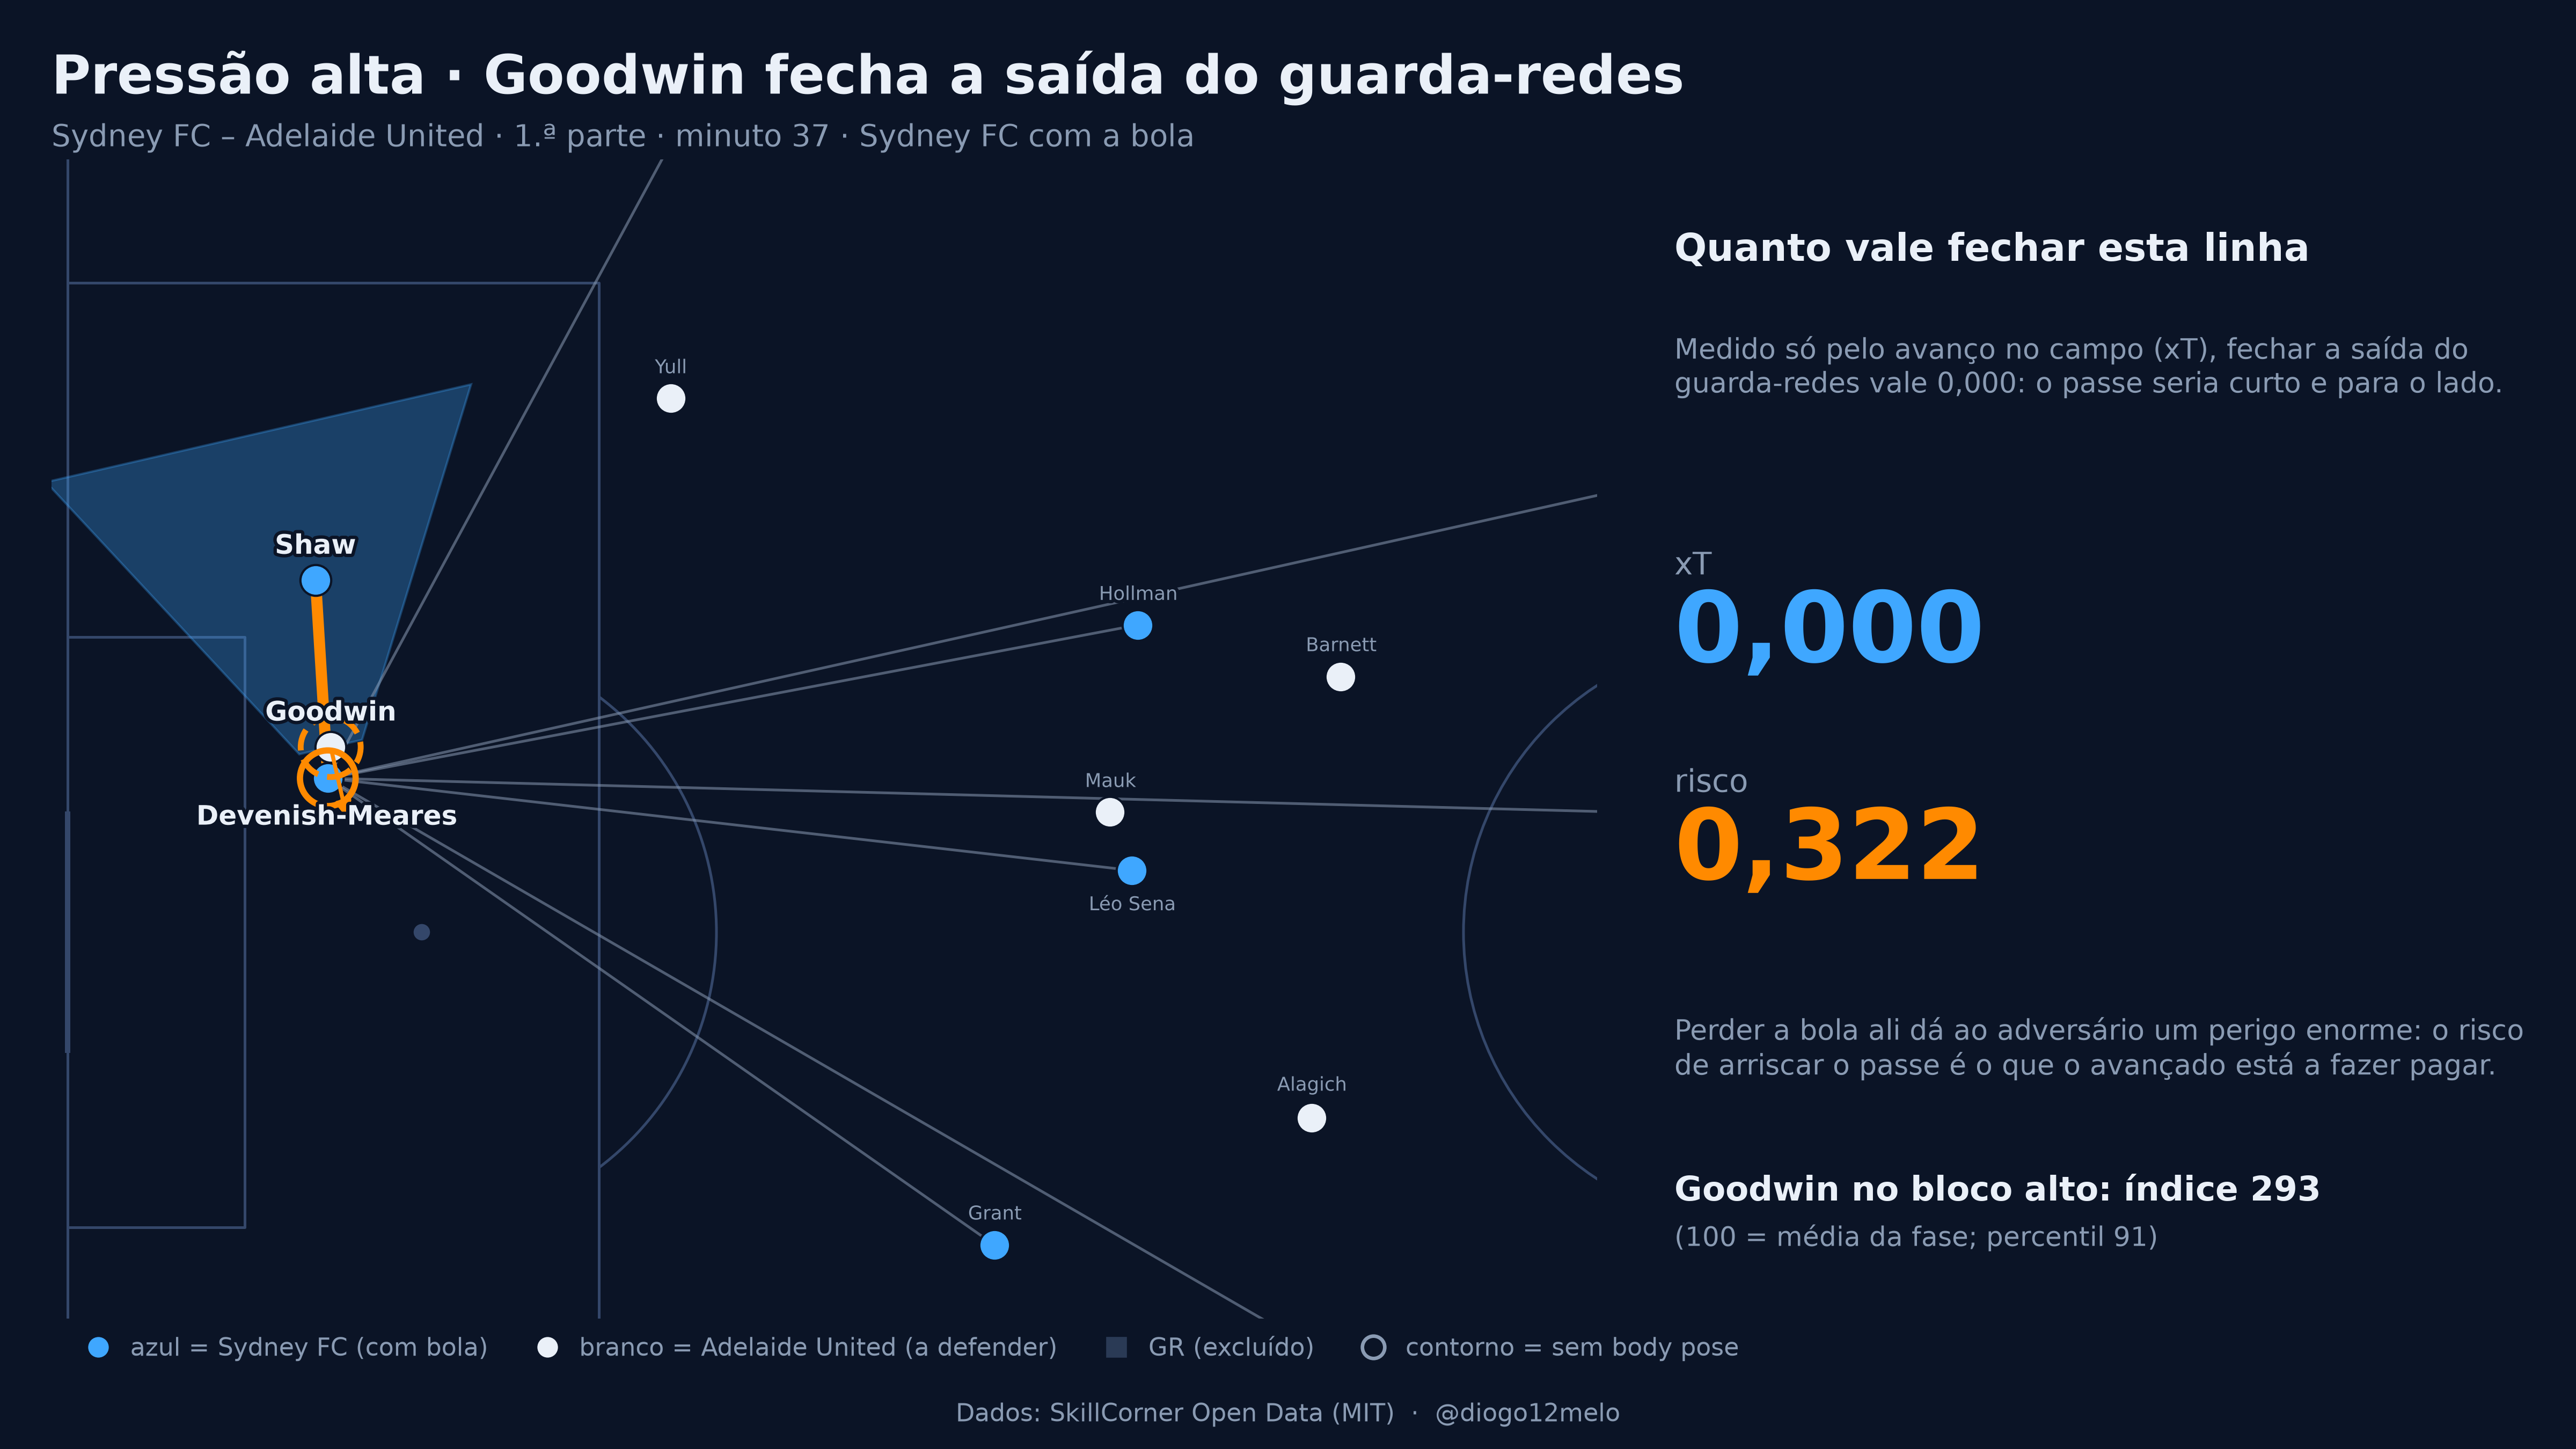

In [9]:
from IPython.display import Image

Image(filename=str(SAIDA / "artigo" / "novo_pressao_alta_goodwin.png"), width=900)

## 7. Avaliação face aos critérios de sucesso

Os critérios são os do notebook 01. O veredicto resume a evidência das secções anteriores; os números vêm da v3, salvo indicação.

| Critério | Veredicto | Justificação |
|---|---|---|
| **C1** · Validade aparente | Cumpre | Nas três rondas de revisão por um treinador, as sombras foram consideradas coerentes em 7/15 (v1), 15/15 (v2) e 8/8 (v3) lances. A última ronda, com lances novos depois dos ajustes, funciona como validação independente (secção 1). |
| **C2** · Separa sombra de marcação | Cumpre | Na revisão independente (v3), a marcação foi considerada correta em 7 de 8 lances. O caso restante (W02) é de interpretação: o defesa estava 0,45 m fora da tolerância do lado da baliza (1 m) e o colega não estava em fora de jogo (secções 1.3 e 1.4). |
| **C3** · Coerência com o jogo | Cumpre parcialmente | A sombra distingue as linhas que os jogadores evitam (diferença de sombra com controlo do comprimento e do ganho de xT: −0,121 [−0,139; −0,102]), mas sobrestima o fecho das linhas: 61,6% dos passes tentados com probabilidade de chegar < 0,5 chegam (53 de 86), em parte porque só se observam os passes tentados (secções 2 e 3.2). |
| **C4** · Estabilidade | Cumpre, com uma ressalva | Variações razoáveis dos parâmetros alteram pouco a ameaça negada (46,9% / 39,4% na partida; entre 42,6% e 51,5% / 35,4% e 45,2%) e quase nada a ordenação: ρ por jogador ≥ 0,975 e por lance ≥ 0,950 (secção 3.3). A exceção é o bloqueio pelo corpo, que altera o valor absoluto (24,8% / 22,2% sem bloqueio a 59,3% / 51,4% com 1,5 m) sem alterar muito a ordenação (ρ por jogador 0,984 a 0,997 entre 0,5 e 1 m; 0,896 sem bloqueio e 0,920 a 1,5 m). A métrica deve ler-se de forma comparativa (secção 3.2). |
| **C5** · O corpo acrescenta alguma coisa | Cumpre | A orientação pelo tronco altera a sombra em 40,1% das linhas e dá menos ameaça negada do que o cone virado para a bola (46,9% vs 49,2% e 39,4% vs 43,5%), mantendo uma ordenação de jogadores semelhante (ρ 0,972) (secção 4). |
| **C6** · Reprodutível e rastreável | Cumpre | A v3 reproduz as tabelas do notebook 04; os testes e o lint do projeto passam; os dois jogos correm com os mesmos parâmetros (secção 6). |
| **C7** · Explicável (opcional) | Por avaliar | Faz-se na fase 6, com as animações finais. |

## 8. Síntese da fase

Resultados descritos sem os classificar. A sensibilidade da v2 (C4) está calculada: 32 variantes × 2 jogos, incluindo as do bloqueio pelo corpo (raios 0, 0,5, 0,7, 1, 1,5 m e gradual); a secção 3.1 mostra, para cada regra nova, a ameaça negada, o C3 com controlo e a taxa de completos abaixo de 0,5. A **v3** (marcação a 4 m com tolerância de 1 m no lado da baliza, D33, e bloqueio gradual, D34) é a definição final da fase: calculou-se a base e as cinco variantes do bloqueio por raio fixo (secção 3.2); os parâmetros antigos (ângulo, comprimento e largura do cone, reação, velocidade da bola, incerteza, marcação) repetiram-se na v3 (secção 3.3), tal como o C5 (cone virado para a bola).

- **C1 e C2 (revisão).** Primeira ronda (v1, 15 lances): sombras 7 *sim*, 8 *em parte*, 0 *não*; marcação 5 *sim*, 9 *em parte*, 1 *não*. Dela saíram D25–D30. Segunda ronda (v2): 15 lances novos (5 de maior ameaça negada, 5 ao acaso, 5 de maior diferença entre tronco e bola, sem repetir posses), figuras e clips em `outputs/cover_shadow/revisao_v2/`; folha `revisao_lances_v2.csv`: sombras 15 *sim*; marcação 10 *sim*, 4 *em parte*, 1 *não*. Dela saíram D32–D34 (secção 1.3).
- **Efeito das regras novas (jogo 1925299 / 1996435).** Ameaça negada: 34,0% / 31,4% (v1) para 57,7% / 49,8% (v2). Linhas excluídas na v2: 35,9% / 27,5% (a maior parte por falta de pose; fora de jogo 2 902 e 2 788 linhas, cruzamento 916 e 601).
- **C3 (coerência com o jogo).** Passes com linha avaliada: 1 355 (v1) e 1 342 (v2). Diferença de sombra entre a linha seguida e as disponíveis: −0,102 [−0,110; −0,095] (v1) e −0,180 [−0,194; −0,166] (v2); percentil médio 0,31 nas duas. **Com o controlo do comprimento e do ganho de xT** (nos passes com linhas comparáveis, n = 1 081 e 1 072): −0,100 para −0,038 [−0,046; −0,030] (v1) e −0,177 para −0,161 [−0,186; −0,138] (v2). Taxa de passes completos: sem sombra 94,8% [93,3; 96,0]; com probabilidade de chegar abaixo de 0,5, 35,0% (n = 20) na v1 e 64,6% (n = 113) na v2 [55,4; 72,8]; entre 0,5 e 0,9, 68,8% (n = 16); entre 0,9 e 1, 77,8% (n = 176). Dentro das bandas de comprimento, na v2, a taxa abaixo de 0,5 é 71,1% (0–10 m, n = 38), 66,7% (10–20 m, n = 42) e 54,5% (20 m ou mais, n = 33). Na v2 a faixa abaixo de 0,5 ficou com muito mais passes e uma taxa de completos bem mais alta do que na v1.
- **C4 (estabilidade).** v1: % da ameaça negada entre 24,6% e 44,8% (jogo 1925299) com 34,0% nos valores de partida; ρ por jogador entre 0,955 e 1,000. v2: ver as secções 3 e 3.1. Nos limiares novos, a % negada (jogo 1925299 / 1996435) vai de 28,6% / 26,7% (bloqueio desligado) a 62,4% / 55,9% (raio 1,5 m), com 57,7% / 49,8% na partida e 50,7% / 43,5% no bloqueio gradual; pressão, saída da marcação, passe curto e passe atrasado movem-na menos de 1 ponto.
- **C5 (o corpo).** Com o cone virado para a bola, a sombra muda em 43,8% das linhas avaliadas na v1 e 42,6% na v2 (com perigo: 48,8% e 46,9%). Na v1, 17 356 linhas têm sombra só pelo corpo e 6 513 só pela bola; na v2, 17 560 e 6 509. % negada tronco/bola no jogo 1925299: 34,0/39,2 (v1) e 57,7/60,4 (v2); no 1996435: 31,4/35,1 e 49,8/54,5. Na v3, a sombra muda em 40,1% das linhas avaliadas (com perigo: 44,0%); 18 287 linhas têm sombra só pelo corpo e 6 738 só pela bola; % negada tronco/bola 46,9/49,2 (jogo 1925299) e 39,4/43,5 (1996435). Por jogador, dentro da posição, ρ = 0,953 (v1), 0,975 (v2) e 0,972 (v3; mínimo 0,800); diferença absoluta mediana 0,029, 0,037 e 0,023 xT. (Corrigido a 3/11, D35: a v1 não foi recalculada e mantém o erro da orientação para a bola.)
- **C4 na v3 (secção 3.3).** Um parâmetro de cada vez, nos dois jogos: a % negada (jogo 1925299 / 1996435) varia entre 42,6% e 51,5% / 35,4% e 45,2% (46,9% / 39,4% na partida); o maior efeito é o da velocidade da bola (43,8% a 51,5% / 35,6% a 45,2%), do tempo de reação e da largura junto ao corpo. O ρ de Spearman face à v3 não desce de 0,975 por jogador (dentro da posição) nem de 0,950 por lance (comprimento do cone a 12 m); é 1,000 por jogador em 7 das 16 variantes.
- **v3 (secção 3.2).** Ameaça negada (jogo 1925299 / 1996435): 34,0% / 31,4% (v1), 57,7% / 49,8% (v2) e 46,9% / 39,4% (v3); linhas excluídas na v3: 33,5% / 25,6%. C3 com controlo (1 087 passes): −0,121 [−0,139; −0,102] (v3), contra −0,161 [−0,186; −0,138] (v2) e −0,038 [−0,046; −0,030] (v1). Com probabilidade de chegar abaixo de 0,5: 61,6% [51,1; 71,2] de passes completos (53 de 86) na v3, 64,6% (73 de 113) na v2 e 35,0% (7 de 20) na v1. Estabilidade face à v3 com bloqueio por raio fixo, ρ de Spearman por jogador (dentro da posição) / por lance: 0 m 0,896 / 0,911; 0,5 m 0,984 / 0,970; 0,7 m 0,996 / 0,984; 1 m 0,997 / 0,992; 1,5 m 0,920 / 0,973. A % negada (jogo 1925299 / 1996435) vai de 24,8% / 22,2% (0 m) a 59,3% / 51,4% (1,5 m), com 46,9% / 39,4% no bloqueio gradual.
- **Verificações depois da 2.ª revisão (secção 1.3).** V01: o guarda-redes (C. Cook, GK) está em x = −50,5 m e não consta da tabela de defesas; os defesas com cone mais perto da baliza nesse frame são D. Williams (CF, a 3,2 m da baliza), R. Warland (LB) e T. Ostler (RW). Cruzamentos: o D27 exclui 916 e 601 linhas (1,03% e 0,74%); dos 100 frames com mais ameaça negada, 100 e 96 têm o portador no terço ofensivo (39 e 42 fora da largura da grande área) e 36 e 26 estão na zona de cruzamento. Marcações: V06 estava a 3,36 m (entrada a 3 m) e V12 e V15 a −0,10 m e −0,68 m no lado da baliza; no V11, no frame do lance, a 2,99 m e do lado certo, o defesa já era classificado como a marcar na v2, mas só em 5 dos 20 frames da janela de ±3 s (distância entre 2,7 e 3,1 m). Com a v3, os quatro são classificados como a marcar no frame do lance; nos frames da janela, 13 de 23 (V06), 20 de 20 (V11), 6 de 9 (V12) e 3 de 19 (V15).
- **Por zona e fase (D32).** Disponível apenas como tabelas descritivas (secção 3.2 d e notebook 04, secção 4.1): por exemplo, nos dois jogos juntos, a % negada é 51,5% com a posse no terço ofensivo, 33,6% no médio e 25,3% no defensivo; por fase defensiva, 46,3% no bloco baixo, 30,5% no médio e 24,9% no alto.
- **Comparação com a SkillCorner.** Igual nas duas versões, como esperado (o perigo da linha não depende das regras novas): 4 870 de 5 360 opções coincidem; ρ = 0,417 [0,392; 0,442]; só com ganho de xT positivo (3 243), 0,585 [0,559; 0,610].
- **C6 (reprodutibilidade).** A `base` da v3 reproduz, tabela a tabela, as do notebook 04 nos dois jogos. Os testes passam (222); o lint do repositório assinala ocorrências fora do projeto (`projects/livres`, `src/footy/transform`).
- **Limitações.** Dois jogos; 1 342 passes com linha avaliada e 16 a 176 nas faixas com sombra; os passes bloqueados não são observados; a sensibilidade varia um parâmetro de cada vez; os limiares da v3 (D33, D34) foram ajustados a partir de 4 casos da revisão; as correlações por jogador usam 4 a 9 jogadores por posição.
- **3.ª revisão (secção 1.4).** 8 lances novos (W01–W08; 3 de maior ameaça negada, 3 ao acaso, 2 de maior diferença entre tronco e bola), sem repetir posses das rondas anteriores; folha `revisao_lances_v3.csv` em branco, figuras e clips em `outputs/cover_shadow/revisao_v3/`.


### Em linguagem corrente

Esta fase não mede se a métrica "acerta", porque não há uma resposta certa guardada. Por isso olha-se
para ela de várias maneiras. Um treinador vê 15 lances e diz se as sombras e quem marca fazem sentido; dessa
revisão saíram seis mudanças à definição, e um segundo grupo de 15 lances novos fica à espera de segunda opinião.
Compara-se com o que os jogadores fizeram mesmo: passaram mais para linhas livres? Os passes por
linhas com sombra falharam mais? E isso continua a valer quando se comparam passes do mesmo comprimento e com o
mesmo ganho de perigo? Mexe-se um botão de cada vez (o ângulo, o comprimento do cone, o tempo de
reação, os limiares novos…) para ver se os resultados mudam muito ou mantêm a ordem dos jogadores e dos lances.
Troca-se o corpo do defesa por "olhar para a bola" para ver quanto o corpo acrescenta. Compara-se o perigo
calculado com o da SkillCorner onde existe. E confirma-se que tudo se refaz do princípio e dá os mesmos números.
Em todas estas medidas mostram-se lado a lado os números da primeira versão e da segunda.
Depois da segunda ronda de revisão, a regra da marcação ficou um pouco mais larga (um defesa passa a marcar quando está
a menos de 4 m do atacante e mesmo lado a lado com ele) e o corpo tapa a linha de forma gradual em vez de só a menos de
1 m. A definição final (v3) nega menos ameaça do que a v2, e a ordem dos jogadores e dos lances quase não muda quando
se troca a forma de contar o bloqueio, a não ser quando o bloqueio é desligado ou muito largo.
